# 34 – Modellvergleich und Umsetzung nach Aufgabenstellung: Modell Ivelina gegen Modell LSTM

**Worum es geht:** Im Projekt gibt es zwei vollständige Ansätze. Dieses Notebook baut beide aus
denselben Daten neu, prüft sie nach denselben Regeln und sagt am Ende, **welches Modell welche Aufgabe der Aufgabenstellung
übernimmt und wie das umgesetzt wird**. Umgesetzt ist es im Dashboard in Notebook 35.

| | Modell Ivelina | Modell LSTM |
|---|---|---|
| Idee | Jede Station hat eine eigene **Kennlinie** über der Außentemperatur. Ein **CUSUM-Konto** zählt, ob sie über mehrere Tage davon wegläuft. Dazu ein **Netzvergleich** jeder Station mit den anderen im selben Winter. | Ein **neuronales Netz (LSTM)** sagt aus den letzten 7 Tagen voraus, wie Rücklauf und Durchfluss heute sein müssten. Dazu fasst ein zweites LSTM jeden Tag in 8 Zahlen zusammen, aus denen eine Regression die **Fehlerart** schätzt. |
| Notebooks | Kennlinien-Strang, im Titel nummeriert 20 bis 27: `netzvergleich` (20), `tagesmonitor` (21), `alarme` (22), `23_nachbarn`, `24_netzereignisse`, `25_netzkarte`, `27_bestwert`, Vorarbeit 12 bis 15 | Modell-Strang 18 bis 22: `18_modelldaten_labels`, `19_kmeans_einstufung_folie5`, `20_lstm_fehlererkennung`, `21_prognose_lstm_waechter`, `22_xgboost_fehlerklassen` |
| Code | `src/tagesmonitor.py`, `src/netzvergleich.py`, `src/alarmbewertung.py`, `src/stationsblatt.py` | `src/prognose_waechter.py`, `src/fehlerklassen.py` |

Dazu kommt **XGBoost** aus Notebook 22 als dritter Kandidat für die Fehlerart, und **einfache Regeln
ohne Lernen** als Messlatte: Ein kompliziertes Modell muss zeigen, dass es mehr kann als eine Regel.

**Warum noch ein Vergleich?** Notebook 32 hat beide schon gegenübergestellt, aber Schwellen auf denselben
Fällen gewählt, an denen es misst, und der LSTM-Encoder hatte die Teststationen gesehen. Das Audit
(Notebook 33, `docs/model_audit/`) hat das LSTM sauber neu gelernt, aber nur mit Kennzahlen verglichen,
nicht mit Ivelinas ganzem Modell. Hier gilt für beide Modelle **eine** Zeitachse und **ein** Satz Regeln,
und alles wird aus Notebook 00 neu gerechnet.

**Lesehilfe.** Jeder Abschnitt hat dieselbe Form: *Frage → So prüfen wir → Ergebnis → Was das heißt.*
Die Logik steht in `src/finalvergleich.py`, hier stehen nur die Aufrufe und die Erklärung.
Wörter für den Stand einer Aussage:

- **belegt**: im Code oder in den Daten nachgewiesen,
- **nachgerechnet**: in diesem Notebook ausgeführt,
- **nur gespeichert**: aus einer Datei übernommen, nicht neu gerechnet,
- **Deutung**: plausible Einordnung, nicht direkt gemessen,
- **nicht prüfbar**: es fehlen Daten dafür.

**Inhalt**
0. Die Antwort auf einer Seite
1. Was gefordert ist
2. Die Modelle in einfachen Worten
3. Daten: beide Modelle nutzen Notebook 00
4. Spielregeln
5. Beide Modelle neu lernen
6. Test A: Merkt das Modell, wenn sich eine Station verändert? (echte Begehungen)
7. Test B: Findet das Modell eingebaute Fehler?
8. Test C: Welche Station hat welchen Fehler? (Konfusionsmatrizen, XGBoost erklärt)
9. Test D: Dauerhaft schlecht, Effizienz, Potenzial
10. Test E: Reihenfolge der Empfehlungen
11. Neue Stationen, spätere Zeit, Jahreszeiten
12. Fallbeispiele mit echten Daten
13. Entscheidung und Dashboard-Bauplan
14. Modelle speichern und Dashboard umstellen
15. Mehrwert der KI gegenüber Regeln
16. Modellwahl ohne Blick auf die Testdaten

## 0 · Die Antwort auf einer Seite

**Kurz: Keins der beiden Modelle ist allein besser. Sie können Verschiedenes, und das Dashboard braucht beide.**
Alle Zahlen sind in diesem Notebook neu gerechnet (**nachgerechnet**), aus denselben Notebook-00-Daten,
mit gemeinsamer Zeitachse und Schwellen nur aus der Probezeit.

| Aufgabe im Dashboard | nehmen wir | weil | Urteil |
|---|---|---|---|
| **Veränderung melden in der Heizperiode**, Erfolgskontrolle nach einer Maßnahme | **Modell Ivelina** (Tagesmonitor: Kennlinie + CUSUM) | Bemerkt echte Begehungen am deutlichsten (18 von 43 gegen 24 % an Vergleichsstationen, p = 0,006). Im Winter findet es eingebaute Rücklauf- und schleichende Fehler am besten (47 % gegen 33 % beim Prognose-LSTM, bei 10 % Fehlalarmen). | Pilot mit Einschränkungen |
| **Veränderung melden an warmen Tagen**, plötzlicher Dauerdurchfluss | **Modell LSTM** (Prognose-LSTM + CUSUM, auf allen Stationen gelernt) | Ivelinas Modell rechnet im Sommer nicht. Das LSTM findet bei 5 % Fehlalarmen 78 % der eingebauten Dauerdurchflüsse (150 l/h), das Wochenmittel 45 %. | Pilot mit Einschränkungen |
| **Fehlerart Ventil** (Reparatur nach Folie 5) | **Modell LSTM** (LSTM-Fingerabdruck → logistische Regression, ohne Kennzahlen, nur auf begangenen Stationen gelernt), **Bestätigung durch Modell Ivelina** (Fehlerbild „ventil“) | AUC 0,83 [0,64; 0,98], 8 von 11 gefunden bei 4 Fehlalarmen; mit anderen Startwerten 0,84 und 0,90. Ivelinas Fehlerbild: 4 von 4 richtig, aber nur 4 gefunden. Mit der Wahl des Modells nur im Lernteil 0,84, gleichauf mit der einfachen Sommernacht-Regel (0,85; Abschnitt 16). | Pilot |
| **Dämmung** | Modell LSTM als Hinweis | AUC 0,79 [0,65; 0,90], mit anderen Startwerten 0,79 und 0,77; mit Modellwahl nur im Lernteil 0,78 (Abschnitt 16); keine einzelne Regel kommt über 0,61, die KI findet ein Muster (mit Modellwahl im Lernteil +0,17 [−0,04; +0,38], knapp nicht gesichert, Abschnitt 16b); Vorsprung gegenüber der Regression auf Kennzahlen (0,73) nicht gesichert | weitere Validierung nötig |
| **Kapazitätsanpassung** | Regel „Spitzenlast zum alten Vertrag“ | AUC 0,76, 5 von 9 bei 1 Fehlalarm; gelernte Modelle scheitern | Pilot mit Einschränkungen |
| **Stationsleistung, Netzeffizienz, dauerhaft schlechter Betrieb** | **Modell Ivelina** (Netzvergleich, Potenzial) | Nur der Vergleich mit anderen Stationen sieht eine Station, die schon immer schlecht läuft (Ventilfall 68956351: Rang 1 vor der Reparatur) | Pilot (beschreibend) |
| Regelungsoptimierung, Durchfluss einstellen, Sollwert, Filter, Regelhysterese | keins als Ursache, nur als Symptom | in den Daten nicht erkennbar (AUC um oder unter 0,5; Hysterese höchstens 15 %) | für diese Aufgabe ungeeignet |
| **XGBoost** | nicht im Dashboard | nirgends verlässlich besser als Regression oder Regel; bei Dämmung je nach Startwerten 0,74 bis 0,87 | für diese Aufgaben ungeeignet |
| echte Frühwarnung vor einem Fehler | – | Beginn eines Fehlers nie bekannt | nicht prüfbar |

**Ist Ivelinas Modell nur besser, weil es für den Winter gebaut ist?** Nein. Ein LSTM, das genauso
gebaut ist (feste Referenz, gleiche Heiztage, gleiche Regel), ist praktisch gleich gut (Abschnitt 7b).
Den Unterschied zum Prognose-LSTM macht die **Bauweise** mit fester Referenz, nicht der Modelltyp. Bei
Gleichstand bleibt die Kennlinie, weil sie einfacher und erklärbar ist.

**Wichtigste Grenze:** Ivelinas Wächter vergleicht mit einer festen Referenz. An 43 % der Testtage steht
eines seiner Konten am Deckel, er kann dort nicht neu alarmieren. **Nächster Schritt:** Referenz nach
jeder Begehung und zu jeder Heizperiode neu lernen und Test A damit wiederholen.

## 1 · Was gefordert ist

**Quelle 1: Aufgabenstellung des Projekts.**
- **Datenanalyse:** stationsspezifische Leistung; Anomalien wie überhöhte Rücklauftemperatur, kontinuierlicher Durchfluss, dynamische Regelhysterese.
- **Modellentwicklung:** automatisierte Anomalieerkennung und Klassifizierung von Fehlerarten an HAST.
- **Visualisierung:** Dashboard mit Netzeffizienz, Stationsleistung und Optimierungspotenzialen.
- **Empfehlungssystem:** priorisierte Handlungsempfehlungen wie Regelungsoptimierung, Reparatur oder Kapazitätsanpassung.

**Quelle 2: Präsentation des Projektpartners** (`notebooks/20260212_Anomaliedetektion.pdf`, 6 Folien):

| Folie | Inhalt | Was wir daraus nehmen |
|---|---|---|
| 2 | Verteilung und Häufigkeit von Fehlern an HAST; leicht behebbare Fehler an Regelung und Ventilen führen zu hohen Rücklauftemperaturen | Der Rücklauf ist das zentrale Symptom |
| 3 | +19,3 K Rücklauf durch Fehler und Suboptima; Liste der Ursachen (Über-/Unterdimensionierung, ungedämmte Leitungen, Undichtigkeiten, Luft, Zirkulation, Verschmutzung, Sensorfehler, Schichtfehler Speicher, Regelabweichung, Stellgliedausfall, klemmende Thermostatventile, hydraulischer Abgleich) | Viele Ursachen, ein Symptom: Aus einem warmen Rücklauf folgt **nicht** eindeutig eine Ursache |
| 4 | Bilanzgebiet mit drei Mustern: dynamische Regelhysterese, kontinuierlicher Durchfluss, ungedämmte Leitungen | Die drei Anomalien, die wir als Fehler einbauen (Test B) |
| 5 | Drei Betriebsarten: sehr effizient (kein Handlungsbedarf), mittelmäßig (Regelparameter optimieren), ineffizient (defektes Regelventil tauschen) | Die drei Klassen nach Folie 5 (Test C) |
| 6 | Ergebnis einer Optimierung von etwa 60 HAST: Netzverluste −13,4 %, Rendite 27 % | Beispiel des Partners, **kein Ergebnis unserer Modelle** |

**Daraus folgen sieben verschiedene Aufgaben.** Sie werden oft vermischt, brauchen aber verschiedene Prüfungen:

| Aufgabe | gefordert? | Was das Dashboard zeigen muss | Woran wir es prüfen | Abschnitt |
|---|---|---|---|---|
| Symptom: ist die Station gerade auffällig? | ja (Anomalieerkennung) | „Rücklauf / Durchfluss auffällig“ | Netzvergleich, Kennzahlen | 8, 9 |
| Veränderung gegenüber dem eigenen Normalbetrieb | ja (Anomalieerkennung) | Alarm mit Datum und Richtung | Begehungen (A), eingebaute Fehler (B) | 6, 7 |
| Fehlerart | ja (Klassifizierung) | „vermutete Ursache“ | Befunde der Begehungen | 8 |
| Warnung bei einer aktuellen Auffälligkeit | Deutung von „Anomalieerkennung“ | Alarm-Liste | wie Veränderung | 6, 7 |
| **echte Frühwarnung** vor einem künftigen Fehler | **nicht ausdrücklich gefordert** | – | **nicht prüfbar**: der Beginn eines Fehlers ist nie bekannt, nur der Tag seiner Entdeckung | 13 |
| Effizienz und Optimierungspotenzial | ja (Visualisierung) | Netzeffizienz, Rang, Abstand zum besten Viertel | Wirkung der Begehungen | 9 |
| Empfehlung und Reihenfolge | ja (Empfehlungssystem) | Handlung, Dringlichkeit, Begründung | Befunde unter den ersten 10 | 10 |

**Wichtig:** Ein Wächter, der jede Station nur mit ihrer eigenen Vergangenheit vergleicht, sieht eine
Station nicht, die **schon immer** schlecht läuft. Stabil ist nicht gleich gut. Dafür braucht es den
Vergleich mit anderen Stationen (Abschnitt 9).

## 2 · Die Modelle in einfachen Worten

### 2a · Modell Ivelina: Kennlinie und CUSUM-Konto

```
Zählerstände um Mitternacht ──► Energie und Volumen je Tag ──► Abkühlung (kWh je m³) und Tagesvolumen
                                                                       │
Referenzzeit (Heiztage vor dem Lernende) ──► Kennlinie: erwarteter Wert bei jeder Außentemperatur
                                                                       │
jeder neue Heiztag:  Abweichung = gemessen − erwartet;   z = Abweichung / normale Streuung
                                                                       │
CUSUM-Konto:  Konto = max(0, Konto + z − 0,5)   (für beide Richtungen getrennt)
                                                                       │
Konto über h = 5  ──►  Alarm  (weniger Abkühlung oder mehr Wasser = „schlechter“)
```

- **Warum Kennlinie?** Bei −5 °C braucht ein Haus viel mehr Wärme als bei +10 °C. Die Kennlinie nimmt
  das Wetter heraus. Übrig bleibt, was die Station *anders* macht als sonst.
- **Warum ein Konto?** Ein einzelner seltsamer Tag ist oft Zufall. Das Konto sammelt kleine Abweichungen
  über viele Tage. Erst wenn sie sich aufsummieren, gibt es einen Alarm. Jeden Tag werden 0,5 abgezogen,
  damit normales Rauschen das Konto nicht füllt.
- **Was ein Alarm aussagt:** Die Station verhält sich *anders als in ihrer Referenzzeit*. Er sagt
  **nicht**, warum. Er sagt auch nicht, dass die Station vorher gut war.
- **Nur Heiztage** (Tagesmittel unter 15 °C): Im Sommer ist die Abkühlung kaum vom Wetter abhängig, der
  Wächter rechnet dann nicht.

**Netzvergleich (zweiter Teil des Modells):** Je Kernwinter (Dezember bis Februar) bekommt jede Station
fünf Kennzahlen, etwa die Spreizung bei mittlerer Last und den Anteil der Stunden mit Rücklauf über
50 °C. Jede Kennzahl wird mit dem Median aller Stationen desselben Winters verglichen. Liegt eine
Kennzahl im schlechtesten Zehntel, gilt sie als „schlecht“. Ab zwei schlechten Kennzahlen ist die
Station **auffällig**. Aus der Kombination entsteht ein **Fehlerbild** (z. B. „ventil“: Volumenstrom
folgt der Leistung kaum und die Spreizung ist klein). Das **Potenzial** ist der Abstand zum besten
Viertel. Die **Priorität** ist *hoch*, wenn die Station auffällig ist und der Wächter in diesem Winter
eine Verschlechterung meldet.

### 2b · Modell LSTM: Vorhersage des Tages und Fingerabdruck der Station

```
letzte 7 Tage × 24 Stunden: Rücklauf, Durchfluss, Vorlauf, Außentemperatur
            + heutiger Vorlauf und heutige Außentemperatur
                          │
               LSTM (Encoder–Decoder, 64 Zustände)
                          │
      Vorhersage für heute, Stunde für Stunde: Rücklauf und Durchfluss
                          │
Abweichung: Rücklauf im Tagesmittel, Durchfluss nachts 0–5 Uhr;  z = (Abweichung − üblich) / üblich Streuung
                          │
Regel „Schwelle“: |z| über der Schwelle an 2 Tagen hintereinander   oder   Regel „CUSUM“: Konto wie oben
```

- **Was gelernt wird:** wie Rücklauf und Durchfluss einer Station normalerweise auf Vorlauf, Wetter und
  die letzten Tage reagieren. Gelernt wird auf allen Stationen gemeinsam (ein Netz für alle).
- **Was ein Alarm aussagt:** Heute ist anders, als die letzten Tage erwarten ließen. Weil das Netz die
  letzten 7 Tage als Eingang nimmt, **gewöhnt es sich an eine bleibende Veränderung** nach etwa einer Woche.
- **In jeder Jahreszeit**, auch im Sommer.

**Fehlerart (zweiter Teil):** Ein zweites LSTM (aus Notebook 20) übersetzt jeden Tag in **8 Zahlen**
(Embedding). Je Station wird der Mittelwert über den Winter 23/24 und den Sommer 2024 gebildet, nur aus
Tagen **vor** der Begehung. Mit 12 einfachen Kennzahlen (z. B. Anteil der Sommernächte mit Durchfluss)
schätzt eine **logistische Regression** die Wahrscheinlichkeit für einen Ventilbefund und für einen
Dämmungsbefund. Die **Klasse nach Folie 5** entsteht so: p(Ventil) ≥ 0,5 heißt „Reparatur (Ventil)“;
sonst entscheidet ein K-Means mit zwei Gruppen auf drei Regelungs-Kennzahlen zwischen
„Regelungsoptimierung“ und „kein Handlungsbedarf“.

Ein Embedding ist **keine** Diagnose: Die 8 Zahlen haben keine Bedeutung für sich. Erst die Regression
verbindet sie mit Befunden, und sie ist nur so gut wie diese Befunde.

### 2c · XGBoost

**XGBoost** baut viele kleine Entscheidungsbäume nacheinander. Jeder Baum stellt ein paar Ja/Nein-Fragen
(z. B. „läuft die Station in mehr als 40 % der Sommernächte?“) und korrigiert die Fehler der Bäume vor
ihm. Eingänge sind dieselben wie bei der Regression. Der Vorteil: Er kann Wechselwirkungen finden.
Der Nachteil: Bei 53 Stationen lernt er leicht Zufall mit. Wir prüfen ihn genauso und erklären am Ende
mit den **Beiträgen je Merkmal**, warum er entscheidet, wie er entscheidet (Abschnitt 8).

### 2d · Drei Gegenproben, damit der Vergleich nicht schief ist

1. **LSTM mit fester Referenz (gebaut wie Ivelinas Wächter).** Ivelinas Modell ist für den Winter gebaut
   und vergleicht mit einer festen Referenz. Das Prognose-LSTM vergleicht mit den letzten 7 Tagen. Um zu
   trennen, was am *Modelltyp* liegt und was an der *Bauweise*, gibt es ein drittes Modell:
   - Ein LSTM sagt Abkühlung und Tagesvolumen **nur aus dem Temperaturverlauf der letzten 7 Tage**
     voraus. Es sieht keine Messwerte der Station.
   - Gelernt wird auf **denselben Referenz-Heiztagen** wie Ivelinas Kennlinie, mit **derselben**
     Streuungsregel und **demselben** CUSUM-Konto.
   - Der einzige Unterschied ist also Gerade gegen neuronales Netz.
2. **Nur begangene Stationen.** Dem Team wurde vorgegeben, nur auf begangenen Stationen zu lernen. Wir
   halten uns daran, wo mit Befunden gelernt wird (Fehlerart). Die Wächter lernen ohne Befunde das
   Normalverhalten und sollen alle Stationen überwachen, deshalb lernen sie auf allen. Die jeweils andere
   Fassung läuft als Gegenprobe mit.
3. **Ein eigenes Sommer-LSTM.** Lohnt sich ein Modell nur für warme Tage, oder ist es mit nur einem
   Sommer an Lerndaten überangepasst?

## 3 · Daten: beide Modelle nutzen Notebook 00

**Frage:** Bekommen beide Modelle wirklich dieselben Messwerte?

**So prüfen wir:** Wir laden die 93 Stundenreihen aus `data/processed/real_meters/` (Ausgabe von
Notebook 00) **einmal**. Ivelinas Modell rechnet direkt darauf. Die Stundentabelle des LSTM wird hier
aus denselben Reihen gebaut und mit `modell_stunden.parquet` aus Notebook 18 verglichen.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import finalvergleich as fv
from src import tagesmonitor as tm
from src import prognose_waechter as pw
from src import fehlerklassen as fk
from src import pruefstand as ps
from src import modellpaket as mp

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
plt.rcParams["figure.facecolor"] = "white"
print("PyTorch", torch.__version__, "| Grafikkarte:", torch.cuda.is_available())

PyTorch 2.11.0+cu128 | Grafikkarte: True


In [2]:
e = fv.lade_eingaben(ROOT)
pruefung = fv.gleiche_daten_pruefen(e["serien"], e["stunden"])
pruefung

,Prüfung,Wert
0,Zähler in den NB-00-Reihen (Ivelina),93.0
1,Zähler in der LSTM-Stundentabelle,93.0
2,größte Abweichung Rücklauf LSTM-Tabelle zu NB ...,0.0
3,gemessene Stunden in NB 18,1690145.0
4,gemessene Stunden hier,1690145.0
5,davon gleiche Zähler-Stunden,1690145.0
6,größte Abweichung Rücklauf zu NB 18 [K],0.0
7,größte Abweichung Durchfluss zu NB 18 [l/h],0.0


In [3]:
assert pruefung.loc[0, "Wert"] == pruefung.loc[1, "Wert"] == 93
assert pruefung.set_index("Prüfung").filter(like="Abweichung", axis=0)["Wert"].max() == 0.0
serien = e["serien"]
erste = min(s.index.min() for s in serien.values())
letzte = max(s.index.max() for s in serien.values())
print(f"93 HAST, Messungen von {erste:%d.%m.%Y} bis {letzte:%d.%m.%Y}")
print(f"gemessene Stunden mit Rücklauf und Durchfluss: {e['stunden'].dropna(subset=['ruecklauf', 'durchfluss']).shape[0]:,}".replace(",", "."))

93 HAST, Messungen von 01.11.2021 bis 20.07.2026
gemessene Stunden mit Rücklauf und Durchfluss: 1.690.145


**Ergebnis:** Beide Modelle sehen dieselben 93 Reihen, Stunde für Stunde gleich, und die Tabelle des
LSTM ist identisch mit der aus Notebook 18 (**nachgerechnet**).

### Die Labels: was wir über die Stationen wissen

Die einzige Wahrheit, die wir haben, sind die **Begehungen** (Protokoll der Übergabestationen,
`data/raw/20252810_Ergebnis_Optimierung_FW[45].xlsx`). Notebook 18 macht daraus sechs Labels je Zähler.
**Laut Team und Projektpartner gilt: Was im Protokoll steht, war der Fehler. Was nicht drinsteht, war es nicht.**

In [4]:
lab = e["labels"]
termine = e["termine"]
n_termine = sum(len(v) for v in termine.values())
print(f"{len(lab)} begangene Zähler mit Zeitreihe, {n_termine} Begehungstermine mit Datum an {sum(1 for v in termine.values() if v)} Zählern")
d = pd.Series([pd.Timestamp(t) for v in termine.values() for t in v])
print("Begehungen je Monat:", d.dt.to_period("M").value_counts().sort_index().to_dict())
labeltabelle = pd.DataFrame({
    "Bedeutung": pd.Series(fv.ZIEL_TEXT),
    "Quelle": ["Kästchen Stellventil/Stellmotor oder Freitext (befundcodes)", "Kästchen oder Freitext",
               "Kästchen", "Kästchen", "Kästchen", "Vertrag neu kleiner als alt"],
    "Stationen mit Befund": [int(lab[z].sum()) for z in fv.ZIELE],
    "Stationen bekannt": [int(lab[z].notna().sum()) for z in fv.ZIELE],
})
labeltabelle

56 begangene Zähler mit Zeitreihe, 58 Begehungstermine mit Datum an 56 Zählern
Begehungen je Monat: {Period('2024-08', 'M'): 2, Period('2024-09', 'M'): 34, Period('2024-10', 'M'): 3, Period('2024-11', 'M'): 13, Period('2024-12', 'M'): 1, Period('2025-03', 'M'): 1, Period('2025-09', 'M'): 4}


,Bedeutung,Quelle,Stationen mit Befund,Stationen bekannt
ventil,Ventil getauscht / Ventilbefund,Kästchen Stellventil/Stellmotor oder Freitext ...,11,56
daemmung,Leitungen gedämmt,Kästchen oder Freitext,23,56
durchfluss,Durchfluss neu eingestellt,Kästchen,20,56
temperatur,Rücklauf-Sollwert gesenkt,Kästchen,36,56
filter,Filter gereinigt,Kästchen,26,56
ueberdimensioniert,Vertrag verkleinert,Vertrag neu kleiner als alt,9,37


**Was die Labels sind und was nicht:**

| Aussage | Stand |
|---|---|
| Ein Eintrag heißt: Dieser Fehler lag vor und wurde behoben. | belegt (Protokoll, Teamangabe) |
| Kein Eintrag heißt: Dieser Fehler lag an der Station nicht vor. Eine Meldung des Modells ohne Eintrag ist also ein **Fehlalarm**. | Teamangabe (gilt nur für begangene Stationen) |
| Der **Beginn** eines Fehlers ist nie bekannt, nur das Datum der Begehung. | belegt |
| 37 HAST wurden nie begangen. Sie sind **unbekannt, nicht gesund**. | belegt |
| „Rücklauf-Sollwert gesenkt“ steht bei fast zwei Dritteln der begangenen Stationen. | belegt |
| Fehlerarten werden nur an **einer Station = einem Fall** gemessen, nie an Fenstern. Tausende Tage aus 11 Ventilfällen sind 11 Fälle. | Spielregel |

## 4 · Spielregeln

Diese Regeln stehen **vor** jedem Testergebnis fest. Sie gelten für beide Modelle gleich.

1. **Gleiche Daten:** die 93 Reihen aus Notebook 00, siehe Abschnitt 3.
2. **Gleiche Zeitachse:**
   - **Lernen** bis 31.01.2024: Kennlinien (Ivelina) und Netzgewichte (LSTM).
   - **Kalibrieren** 08.02. bis 31.03.2024: die normale Schwankung des LSTM je Station.
   - **Einstellen** April und Mai 2024: Hier wird die Alarmlast eingestellt, auf Tagen, die keins der Modelle kennt.
   - **Test** ab 08.06.2024 bis Datenende: Alle Begehungen liegen hier.
   - Die 7 Tage Abstand am Anfang sind das Eingabefenster des LSTM. So teilen Lernen und Test keinen einzigen Rohdatentag.
3. **Gleiche Alarmlast:** Ivelinas Wächter behält ihre eigene Einstellung h = 5. Alle anderen Wächter bekommen so viele Alarme, wie er in der Einstellzeit gibt. Wer öfter alarmiert, trifft sonst automatisch öfter.
4. **Fehlerart je Station:**
   - Fünffache Kreuzvalidierung über ganze Stationen. Zwei Zähler an derselben Adresse (Zählertausch) bleiben zusammen.
   - Der LSTM-Encoder wird in jedem Durchgang **ohne** die Teststationen neu gelernt.
   - Feste Grenze p ≥ 0,5, nichts wird nachträglich verschoben.
5. **Nur Daten vor der Begehung** für die Fehlerart. Die Kennzahl „Spitzenlast zum Anschlusswert“ bleibt draußen: Der Anschlusswert ist bei 7 von 9 verkleinerten Verträgen schon der neue Wert.
6. **Einfache Gegner laufen mit:**
   - Wochenmittel: Erwartung = Mittel der letzten 7 Tage, ohne Lernen.
   - Sommernacht-Regel: Anteil der Sommernächte mit Durchfluss.
   - Auslastung zum alten Vertrag.
7. **Unsicherheit** über ganze Stationen (Bootstrap), nie über Tage oder Fenster.
8. **Zwei Fassungen je Wächter:**
   - **gemeinsam geschnitten** ist der Hauptvergleich.
   - **„wie gebaut“** (Ivelinas eigene Referenzregel, das LSTM-Paket aus Notebook 21) läuft nur als Gegenprobe.

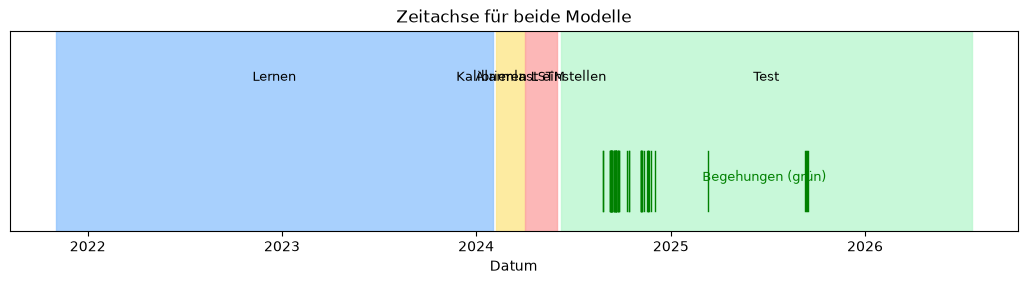

In [5]:
fig, ax = plt.subplots(figsize=(13, 2.6))
abschnitte = [("Lernen", erste, fv.LERN_ENDE, "#93C5FD"),
              ("Kalibrieren LSTM", fv.VAL_START, fv.WAHL_START, "#FDE68A"),
              ("Alarmlast einstellen", fv.WAHL_START, fv.VAL_ENDE, "#FCA5A5"),
              ("Test", fv.TEST_START, letzte, "#BBF7D0")]
for name, von, bis, farbe in abschnitte:
    ax.axvspan(von, bis, color=farbe, alpha=0.8)
    ax.text(von + (bis - von) / 2, 0.75, name, ha="center", fontsize=9)
for t in d:
    ax.plot([t, t], [0.1, 0.4], color="green", lw=1)
ax.text(pd.Timestamp("2025-03-01"), 0.25, "Begehungen (grün)", fontsize=9, color="green")
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_title("Zeitachse für beide Modelle")
ax.set_xlabel("Datum")
fv.speichere(fig, "00_zeitachse")
plt.show()

## 5 · Beide Modelle neu lernen

**So geht es:** `fv.waechter_bauen` lernt Ivelinas Kennlinien bis zum Lernende und das Prognose-LSTM auf
denselben Tagen (frühes Stoppen nur auf der Kalibrierzeit). Danach stellt es alle Wächter auf dieselbe
Alarmlast ein. Dazu kommen die Gegenproben aus 2d: das LSTM mit fester Referenz und das Prognose-LSTM nur
auf begangenen Stationen. Die Startwerte sind fest (Seed 0), ein neuer Lauf ergibt dieselben Gewichte.

In [6]:
w = fv.waechter_bauen(e)
print("Ivelina, Referenzstatus:", w["ref"]["status"].value_counts().to_dict())
print("LSTM: gelernt auf", len(w["lstm"]["lern_stationen"]), "Stationen,", w["lstm"]["lern_ziele"], "Lerntage und",
      w["lstm"]["val_ziele"], "Prüftage; kalibriert:", len(w["kal"]), "Stationen")
w = fv.nv_hinzufuegen(w, e)
w = fv.nur_begangene_hinzufuegen(w, e)
print("LSTM mit fester Referenz:", w["nv"]["stationen"], "Stationen,", w["nv"]["lern_tage"], "Referenz-Heiztage,",
      w["nv"]["pruef_tage"], "Prüftage")
print("Prognose-LSTM nur begangene:", len(w["beg"]["stationen"]), "Lernstationen")

Prognose-LSTM: 143 Runden, bester Validierungsfehler 0.1040, 27 s


Ivelina, Referenzstatus: {'ok': 86, 'zu wenige Referenztage': 6, 'keine Tage nach der Referenz': 1}
LSTM: gelernt auf 87 Stationen, 20510 Lerntage und 8599 Prüftage; kalibriert: 86 Stationen


LSTM mit fester Referenz: 65 Runden, bester Validierungsfehler 0.9982, 4 s


Prognose-LSTM: 104 Runden, bester Validierungsfehler 0.1072, 11 s


LSTM mit fester Referenz: 86 Stationen, 26546 Referenz-Heiztage, 4531 Prüftage
Prognose-LSTM nur begangene: 54 Lernstationen


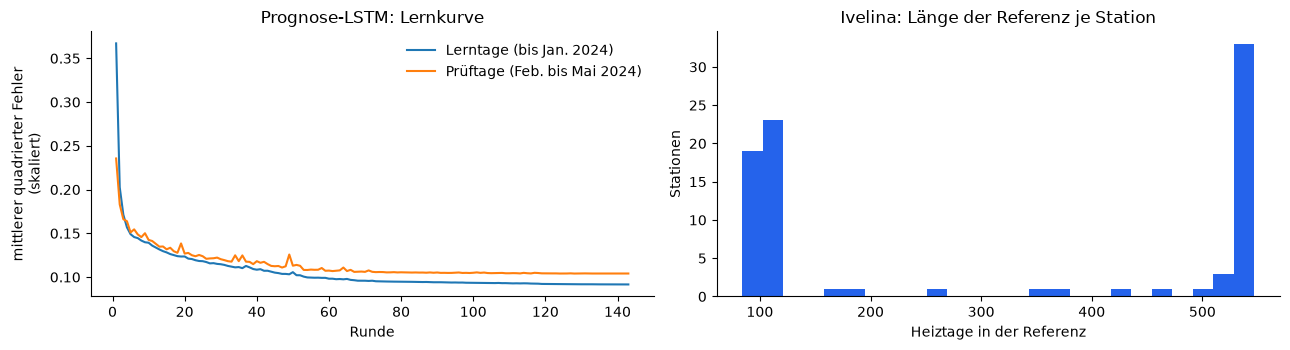

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
k = w["lstm"]["lernkurve"]
ax[0].plot(k["runde"], k["lernen"], label="Lerntage (bis Jan. 2024)")
ax[0].plot(k["runde"], k["validierung"], label="Prüftage (Feb. bis Mai 2024)")
ax[0].set_xlabel("Runde")
ax[0].set_ylabel("mittlerer quadrierter Fehler\n(skaliert)")
ax[0].set_title("Prognose-LSTM: Lernkurve")
ax[0].legend(frameon=False)
r = w["ref"]
ax[1].hist(r.loc[r["status"] == "ok", "ref_tage"], bins=25, color=fv.FARBE_IVELINA)
ax[1].set_xlabel("Heiztage in der Referenz")
ax[1].set_ylabel("Stationen")
ax[1].set_title("Ivelina: Länge der Referenz je Station")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "01_lernen")
plt.show()

**Gleiche Alarmlast.** Ivelinas Wächter gibt mit h = 5 auf den gemeinsamen Tagen von April und Mai 2024
eine bestimmte Zahl an Alarmen. Für das LSTM und das Wochenmittel wird je Regel der Wert gesucht, der
am nächsten daran liegt:

In [8]:
print("Ziel:", w["ziel_alarme"], "Alarme auf", len(w["wahltage"]), "gemeinsamen Stationstagen")
pd.DataFrame([{"Wächter": fv.WAECHTER[k], "Regel": r, "gewählter Wert": v} for k, (r, v) in w["einstellung"].items()])

Ziel: 31 Alarme auf 2184 gemeinsamen Stationstagen


,Wächter,Regel,gewählter Wert
0,Modell Ivelina (Kennlinie + CUSUM),cusum,5.00
1,Modell LSTM + Schwelle,schwelle,2.75
2,Modell LSTM + CUSUM,cusum,10.00
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00
5,LSTM mit fester Referenz (gebaut wie Ivelinas ...,cusum,15.00
6,"Modell LSTM + CUSUM, nur begangene Stationen g...",cusum,10.00


In [9]:
last = fv.arbeitslast(w)
last.round(2)

,Wächter,Regel,Einstellung,Einstellzeit (Apr–Mai 2024),Test (ab Juni 2024)
0,Modell Ivelina (Kennlinie + CUSUM),cusum,5.00,5.18,4.34
1,Modell LSTM + Schwelle,schwelle,2.75,5.52,6.04
2,Modell LSTM + CUSUM,cusum,10.00,5.52,3.40
3,Wochenmittel + Schwelle (ohne Lernen),schwelle,3.00,6.36,6.15
4,Wochenmittel + CUSUM (ohne Lernen),cusum,10.00,3.51,6.37
5,LSTM mit fester Referenz (gebaut wie Ivelinas ...,cusum,15.00,5.18,2.66
6,"Modell LSTM + CUSUM, nur begangene Stationen g...",cusum,10.00,5.18,3.34


**Was das heißt:** In der Einstellzeit liegen alle Wächter bei ähnlich vielen Alarmen je Station und Jahr.
Im Test weichen sie voneinander ab, weil sich die Daten über die Zeit verändern. Deshalb zeigen die Tests
unten immer auch die **Kontrollquote** (wie oft dieselbe Regel ohne Ereignis alarmiert) und Kurven über
alle Einstellungen. So gewinnt kein Modell nur, weil es öfter alarmiert.

## 6 · Test A: Merkt das Modell, wenn sich eine Station verändert?

**Frage:** Bei einer Begehung wurde etwas repariert oder eingestellt. Die Station sollte danach **besser**
laufen. Meldet der Wächter das?

**So prüfen wir:**
- Für jede Begehung im Test zählen wir, ob der Wächter von 7 Tagen vor bis 60 Tage nach dem Termin
  Alarm gibt. Das ist Sebs Prüfung aus Notebook 17, `pruefstand.trefferpruefung`.
- Dasselbe Fenster an **Vergleichsstationen** ohne Begehung ergibt die **Kontrollquote**: wie oft der
  Wächter ohnehin alarmiert.
- Ein Wächter taugt nur, wenn er an Begehungen deutlich öfter alarmiert als an den Vergleichsstationen.
- Getrennt nach Richtung, wie in Ivelinas `alarme.ipynb`: Nach einer durchgeführten Maßnahme erwarten wir
  eine Verbesserung.
- Gezählt wird nur auf Tagen, die alle Wächter beobachten (Heiztage).

**Wichtig:** Ein Alarm *nach* der Begehung zeigt die Wirkung der Maßnahme. Er ist **keine Vorhersage**
des Fehlers.

In [10]:
A, einzel_A = fv.test_begehungen(w, termine)
A_besser = A[A["Richtung"] == "besser"]
A[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "Hebel", "p (einseitig)"]].round(3)

,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,Hebel,p (einseitig)
0,Modell Ivelina (Kennlinie + CUSUM),besser,43,18,0.419,0.237,1.766,0.006
1,Modell Ivelina (Kennlinie + CUSUM),alle,43,23,0.535,0.459,1.166,0.198
2,Modell Ivelina (Kennlinie + CUSUM),schlechter,43,10,0.233,0.275,0.845,0.784
3,Modell LSTM + Schwelle,besser,43,10,0.233,0.256,0.908,0.694
4,Modell LSTM + Schwelle,alle,43,19,0.442,0.472,0.936,0.708
5,Modell LSTM + Schwelle,schlechter,43,11,0.256,0.310,0.824,0.826
6,Modell LSTM + CUSUM,besser,43,10,0.233,0.263,0.884,0.729
7,Modell LSTM + CUSUM,alle,43,17,0.395,0.435,0.909,0.749
8,Modell LSTM + CUSUM,schlechter,43,9,0.209,0.242,0.865,0.746
9,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.326,0.262,1.244,0.215


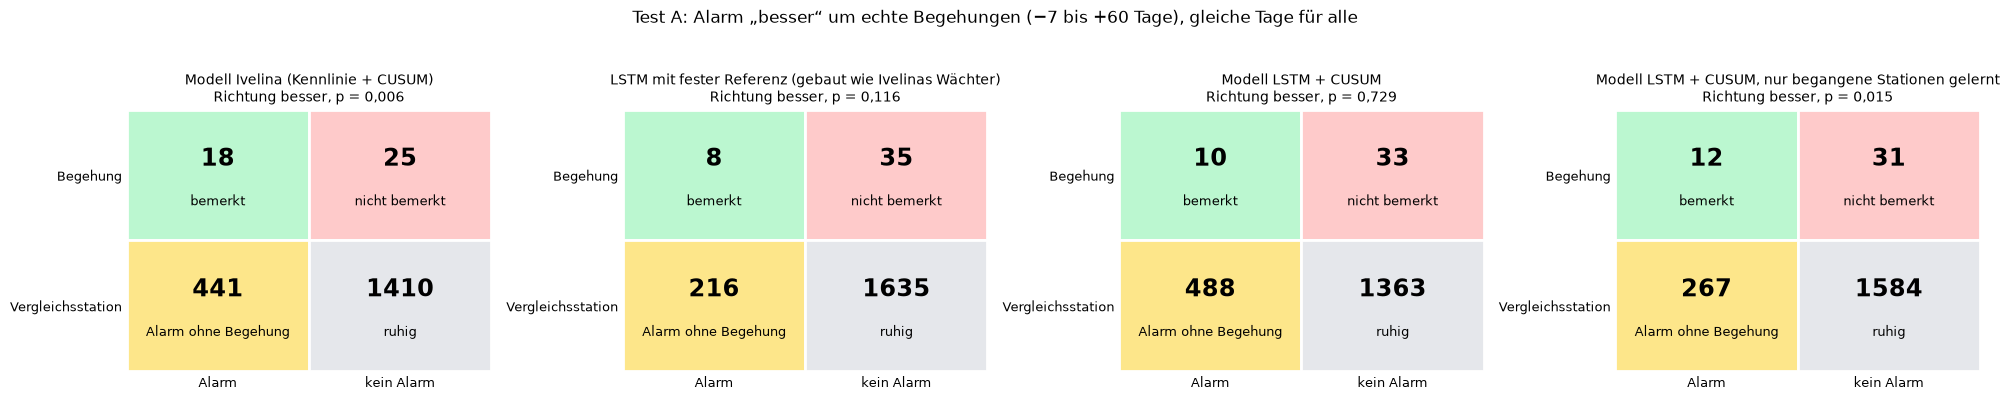

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, key in zip(axes, ["ivelina", "nv", "lstm_c", "lstm_beg"]):
    z = A_besser[A_besser["key"] == key].iloc[0]
    fv.zeichne_vierfeld(ax, z, f"{fv.WAECHTER[key]}\nRichtung besser, p = {z['p (einseitig)']:.3f}".replace(".", ","),
                        zeile_ja="Begehung", zeile_nein="Vergleichsstation",
                        spalte_ja="Alarm", spalte_nein="kein Alarm",
                        woerter=("bemerkt", "nicht bemerkt", "Alarm ohne Begehung", "ruhig"),
                        schluessel=("Begehung, Alarm", "Begehung, kein Alarm", "Kontrolle, Alarm", "Kontrolle, kein Alarm"))
fig.suptitle("Test A: Alarm „besser“ um echte Begehungen (−7 bis +60 Tage), gleiche Tage für alle", y=1.04)
fig.tight_layout()
fv.speichere(fig, "02_testA_konfusion")
plt.show()

Die Vergleichsfenster überlappen sich (dieselbe Vergleichsstation zählt bei mehreren Begehungen). Sie
zeigen die Grundrate, sind aber keine unabhängigen Fälle. Gezählt und getestet wird über die Begehungen.

**Fall für Fall:** Dieselben Begehungen, bemerkt von Ivelina gegen bemerkt vom LSTM (McNemar):

In [12]:
a_iv = einzel_A[("ivelina", "besser")].set_index(["zaehler", "datum"])["treffer"]
zeilen = []
for key in ["nv", "lstm_s", "lstm_c", "lstm_beg", "wm_s", "wm_c"]:
    b = einzel_A[(key, "besser")].set_index(["zaehler", "datum"])["treffer"].reindex(a_iv.index)
    m = ps.mcnemar(a_iv, b)
    zeilen.append({"gegen": fv.WAECHTER[key], "nur Ivelina": m["nur A"], "nur der andere": m["nur B"],
                   "beide": m["beide"], "keiner": m["keiner"], "p (McNemar)": round(m["p (McNemar)"], 3)})
pd.DataFrame(zeilen)

,gegen,nur Ivelina,nur der andere,beide,keiner,p (McNemar)
0,LSTM mit fester Referenz (gebaut wie Ivelinas ...,12,2,6,23,0.013
1,Modell LSTM + Schwelle,12,4,6,21,0.077
2,Modell LSTM + CUSUM,15,7,3,18,0.134
3,"Modell LSTM + CUSUM, nur begangene Stationen g...",12,6,6,19,0.238
4,Wochenmittel + Schwelle (ohne Lernen),10,6,8,19,0.454
5,Wochenmittel + CUSUM (ohne Lernen),10,7,8,18,0.629


**Über alle Einstellungen:** Jeder Punkt ist eine Einstellung (Schwelle oder h). Nach rechts steigt die
Arbeitslast im Test, nach oben der **Vorsprung** = Quote an Begehungen minus Kontrollquote. Der gewählte
Punkt ist umrandet. So sieht man, ob ein Modell nur wegen seiner Einstellung gewinnt.

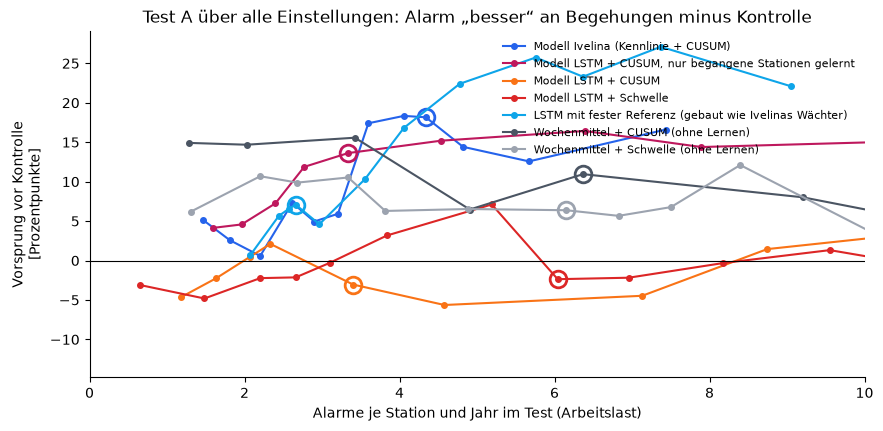

In [13]:
KA = fv.kurve_begehungen(w, termine)
fig, ax = plt.subplots(figsize=(10, 4.5))
farben = {"ivelina": fv.FARBE_IVELINA, "nv": "#0EA5E9", "lstm_s": fv.FARBE_LSTM, "lstm_c": "#F97316",
          "lstm_beg": "#BE185D", "wm_s": "#9CA3AF", "wm_c": "#4B5563"}
for key, g in KA.groupby("key"):
    g = g.sort_values("Arbeitslast")
    ax.plot(g["Arbeitslast"], 100 * g["Vorsprung"], "-o", ms=4, color=farben[key], label=fv.WAECHTER[key])
    s = g[g["gewählt"]]
    ax.plot(s["Arbeitslast"], 100 * s["Vorsprung"], "o", ms=12, mfc="none", mec=farben[key], mew=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlim(0, 10)
ax.set_xlabel("Alarme je Station und Jahr im Test (Arbeitslast)")
ax.set_ylabel("Vorsprung vor Kontrolle\n[Prozentpunkte]")
ax.set_title("Test A über alle Einstellungen: Alarm „besser“ an Begehungen minus Kontrolle")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "03_testA_kurve")
plt.show()

### Gegenprobe: beide Wächter „wie gebaut“

- **Ivelinas eigene Regel:** Die Referenz ist das erste Jahr einer Station. Liegt vorher eine Begehung,
  endet sie 14 Tage davor.
- **LSTM:** das Paket aus Notebook 21, in Betrieb seit dem 24.10.2026. Gelernt bis Juni 2024,
  Regel Schwelle z ≥ 4.

Notebook 32 hat mit diesen Fassungen gerechnet.

In [14]:
ref_g = fv.ivelina_referenz(w["mt"], termine, lern_ende=None)
mod_g, _ = tm.modelle(w["mt"], ref_g)
verl_g = fv.ivelina_verlauf(w["mt"], ref_g, mod_g)
al_g = fv.ivelina_alarme(verl_g)
#das Paket, das Notebook 21 gebaut hat (Quelle im Paket), nicht die gerade aktive Version
nb21 = [v for v in mp.versionen("prognose_lstm")
        if "21_prognose" in mp.lade_paket("prognose_lstm", v, pruefen=False).meta.get("quelle", "")]
alt_lstm = pw.lade(nb21[-1])
print("LSTM-Paket wie gebaut:", alt_lstm["paket"].version, "| Regel:", alt_lstm["parameter"].get("alarmregel"),
      alt_lstm["parameter"].get("schwelle"))
tab_alt = pw.anwenden(alt_lstm, e["stunden"])
tab_alt = tab_alt[tab_alt["status"] == "überwacht"]
al_alt = fv._alarmzeilen(tab_alt, tab_alt["alarm"].to_numpy())
al_alt["bewertung"] = np.where(al_alt["richtung"] > 0, "schlechter", "besser")
beob_g = fv.gemeinsame_tage(fv.ivelina_beobachtet(verl_g), fv.lstm_beobachtet(tab_alt))
A_g, einzel_g = fv.test_begehungen(w, termine, alarme={"ivelina (wie gebaut)": al_g, "lstm (Paket NB 21)": al_alt},
                                   tage=beob_g)
A_g[["Wächter", "Richtung", "Fälle", "bemerkt", "Quote", "Kontrollquote", "p (einseitig)"]].round(3)

LSTM-Paket wie gebaut: 2026-10-24_132552 | Regel: schwelle 4.0


,Wächter,Richtung,Fälle,bemerkt,Quote,Kontrollquote,p (einseitig)
0,ivelina (wie gebaut),besser,43,25,0.581,0.217,0.000
1,ivelina (wie gebaut),alle,43,29,0.674,0.486,0.010
2,ivelina (wie gebaut),schlechter,43,14,0.326,0.312,0.483
3,lstm (Paket NB 21),besser,43,7,0.163,0.078,0.048
4,lstm (Paket NB 21),alle,43,12,0.279,0.222,0.233
5,lstm (Paket NB 21),schlechter,43,9,0.209,0.177,0.349


In [15]:
t = einzel_g[("ivelina (wie gebaut)", "alle")].copy()
t["Referenz endet direkt vor dieser Begehung"] = [
    ref_g.at[z, "ende_grund"] == "vor Begehung" and 0 <= (dt - ref_g.at[z, "ref_ende"]).days <= 30
    for z, dt in zip(t["zaehler"], t["datum"])]
t.groupby("Referenz endet direkt vor dieser Begehung").agg(Begehungen=("treffer", "size"),
    bemerkt=("treffer", "sum"), Kontrollquote=("kontrollquote", "mean")).round(2)

,Begehungen,bemerkt,Kontrollquote
Referenz endet direkt vor dieser Begehung,,,
False,25,15,0.47
True,18,14,0.51


### Gegenprobe: nur begangene Stationen als Vergleich

Das Prognose-LSTM „nur begangene“ kennt alle Stationen mit Begehung, aber kaum eine Vergleichsstation.
Damit das nicht verzerrt, zählen hier nur begangene Stationen als Vergleich (ohne eigene Begehung im
Fenster), für alle Wächter gleich.

In [16]:
nur_beg = list(e["labels"].index)
gt_ = w["gemeinsam"][w["gemeinsam"]["datum"] >= fv.TEST_START]
zeilen = []
for key, a in w["alarme"].items():
    a = fv.nur_tage(a, gt_)
    for richt in ("besser", "alle"):
        aa = a if richt == "alle" else a[a["bewertung"] == richt]
        b = ps.bilanz(ps.trefferpruefung(aa, gt_, fv.begehungsfaelle(termine), termine, stationen=nur_beg))
        zeilen.append({"Wächter": fv.WAECHTER[key], "Richtung": richt, "Fälle": b["Fälle"], "bemerkt": b["Treffer"],
                       "Kontrollquote": b["Kontrollquote"], "p (einseitig)": b["p (einseitig)"]})
pd.DataFrame(zeilen).round(3)

,Wächter,Richtung,Fälle,bemerkt,Kontrollquote,p (einseitig)
0,Modell Ivelina (Kennlinie + CUSUM),besser,43,18,0.337,0.167
1,Modell Ivelina (Kennlinie + CUSUM),alle,43,23,0.529,0.531
2,Modell LSTM + Schwelle,besser,43,10,0.301,0.875
3,Modell LSTM + Schwelle,alle,43,19,0.450,0.602
4,Modell LSTM + CUSUM,besser,43,10,0.448,0.999
5,Modell LSTM + CUSUM,alle,43,17,0.505,0.945
6,Wochenmittel + Schwelle (ohne Lernen),besser,43,14,0.244,0.143
7,Wochenmittel + Schwelle (ohne Lernen),alle,43,22,0.555,0.766
8,Wochenmittel + CUSUM (ohne Lernen),besser,43,15,0.229,0.050
9,Wochenmittel + CUSUM (ohne Lernen),alle,43,18,0.389,0.402


## Was Test A heißt

- **Modell Ivelina bemerkt die Wirkung der Begehungen am deutlichsten:** 18 von 43 Begehungen mit
  Meldung „besser“, an Vergleichsstationen im selben Fenster nur 24 % (p = 0,006).
- **Das Prognose-LSTM auf allen Stationen** liegt auf Höhe der Kontrolle (10 von 43 gegen 26 %), mit
  beiden Regeln und bei jeder Einstellung (Kurve).
- **Fall für Fall** ist Ivelinas Vorsprung gegen das LSTM bei 43 Fällen noch nicht gesichert: 12 zu 4
  (p = 0,08) gegen Schwelle, 15 zu 7 (p = 0,13) gegen CUSUM.
- **Das LSTM mit fester Referenz** ist bei seiner gewählten Einstellung (h = 15) zu streng: 8 von 43
  gegen 12 %, mit nur 2,7 Alarmen je Station und Jahr im Test. Bei gleicher Arbeitslast liegt es fast
  gleichauf mit Ivelina, siehe 7b.
- **Das Prognose-LSTM nur auf begangenen Stationen** zeigt ein Signal: 12 von 43 gegen 14 %
  (p = 0,02), alle Richtungen 23 von 43 gegen 34 % (p = 0,007). Das hält auch, wenn nur begangene
  Stationen als Vergleich zählen (alle Richtungen 23 von 43 gegen 33 %, p = 0,004).
  - Vorsicht: Inzwischen laufen sieben Wächter mit je drei Richtungen. Bei so vielen Vergleichen sieht
    einer leicht zufällig gut aus.
  - Im Sommer ist diese Fassung schwächer (Test B). Deshalb bleibt sie eine Gegenprobe.
- **Mit nur begangenen Vergleichsstationen** wird Ivelinas Vorsprung kleiner (18 von 43 gegen 34 %,
  p = 0,17).
  - Deutung: Begangene Vergleichsstationen hatten selbst Maßnahmen.
  - Ivelinas Wächter rechnet nur an Heiztagen. Die Verbesserung nach einer Begehung im September meldet
    er deshalb oft erst im Oktober oder November, also mitten im Fenster einer späteren Begehung.
  - Dann ist die Kontrolle nicht sauber. Die Hauptprüfung mit allen Vergleichsstationen bleibt maßgeblich.
- **Alarme in beide Richtungen zusammen trennen bei Ivelina nicht** (23 von 43 gegen 46 %).
  Verschlechterungen gibt es an Begehungen nicht öfter als sonst. Der Wächter zeigt die **Wirkung einer
  Maßnahme**, er sagt keinen Fehler voraus. Das passt zu Ivelinas `alarme.ipynb`.
- **Wie gebaut** bemerkt Ivelinas Wächter mehr (25 von 43 gegen 22 %, p < 0,001).
  - Ein Teil davon kommt aus der Referenzregel: Bei 18 Begehungen endet die Referenz genau 14 Tage
    vorher, der Wächter startet frisch kurz vor dem Ereignis.
  - Ergebnis über alle Richtungen: 14 von 18 bemerkt, sonst 15 von 25.
  - Für die Erfolgskontrolle ist das gewollt, für einen fairen Vergleich nicht.
- **Für das Dashboard:** Der Tagesmonitor ist der Wächter für die Heizperiode und für die Erfolgskontrolle.

## 7 · Test B: Findet das Modell eingebaute Fehler?

**Frage:** Bei echten Fehlern kennen wir nie den Beginn. Was passiert, wenn wir einen Fehler mit
**bekanntem** Beginn in echte Daten schreiben?

**So prüfen wir:** An jeder Station, die beide Wächter überwachen, wird je Jahreszeit ein zufälliger
Starttag gezogen. Bedingungen: genug Messwerte in den 30 Tagen danach, keine Begehung in der Nähe. Ab dem
Starttag schreiben wir einen Fehler in die **Stundenwerte aus Notebook 00**, 30 Tage lang. Alle Spalten
bleiben zueinander stimmig: Leistung aus Durchfluss mal Spreizung, und die **Energie- und Volumenzähler**
laufen mit. Neu gegenüber Notebook 21 und 32: So kann auch Ivelinas Wächter geprüft werden, denn er rechnet
aus Zählerständen.

| eingebauter Fehler | was physikalisch passiert | Bezug |
|---|---|---|
| Dauerdurchfluss 50 / 150 l/h | Ventil schließt nicht oder Bypass: zusätzlich fließt Wasser mit Vorlauftemperatur, der Rücklauf mischt sich warm, die Leistung bleibt gleich | Folie 4: kontinuierlicher Durchfluss |
| Rücklauf +5 K | Regelung verstellt: gleiche Leistung bei 5 K kleinerer Spreizung, also mehr Durchfluss | Folie 2/3: überhöhte Rücklauftemperatur |
| schleichend +5 K in 30 Tagen | wie oben, aber langsam ansteigend (z. B. Verschmutzung) | Folie 3: Verschmutzung |
| Regelhysterese 6 h | Ventil pendelt: 3 h 30 % mehr, 3 h 30 % weniger Durchfluss bei gleicher Leistung | Folie 4: dynamische Regelhysterese |
| Fühler hängt | Rücklauffühler bleibt stehen, der Zähler rechnet mit dem falschen Wert | Folie 3: Sensorfehler |

Ausgewertet wird, ob der Wächter in den 14 Tagen ab Fehlerbeginn alarmiert (beim schleichenden Fehler in
30 Tagen). Dazu kommt dasselbe Fenster **ohne** Fehler: Das ist die **Fehlalarmquote**. Hier ist die
Wahrheit bekannt, deshalb ergibt das eine echte Konfusionsmatrix.

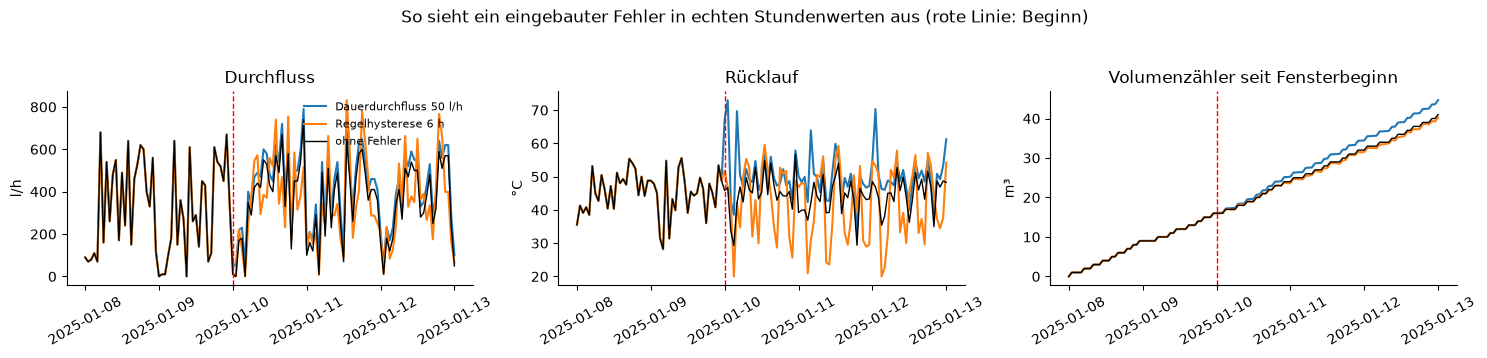

In [17]:
beispiel = e["serien"][next(m for m in w["kal"].index if e["serien"][m].loc["2025-01-05":"2025-01-15", "flow"].notna().sum() > 200)]
start = pd.Timestamp("2025-01-10")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharex=True)
for art, (typ, staerke) in [("Dauerdurchfluss 50 l/h", fv.STOERUNGEN["Dauerdurchfluss 50 l/h"]),
                            ("Regelhysterese 6 h", fv.STOERUNGEN["Regelhysterese 6 h"])]:
    g = fv.stoerung_einrechnen(beispiel, start, typ, staerke, tage=5)
    fenster = g.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
    ax[0].plot(fenster.index, fenster["flow"], label=art)
    ax[1].plot(fenster.index, fenster["rt"], label=art)
    ax[2].plot(fenster.index, fenster["volume"] - fenster["volume"].iloc[0], label=art)
roh = beispiel.loc[start - pd.Timedelta(days=2): start + pd.Timedelta(days=3)]
ax[0].plot(roh.index, roh["flow"], color="black", lw=1, label="ohne Fehler")
ax[1].plot(roh.index, roh["rt"], color="black", lw=1, label="ohne Fehler")
ax[2].plot(roh.index, roh["volume"] - roh["volume"].iloc[0], color="black", lw=1, label="ohne Fehler")
for a, t, y in zip(ax, ["Durchfluss", "Rücklauf", "Volumenzähler seit Fensterbeginn"], ["l/h", "°C", "m³"]):
    a.set_title(t)
    a.set_ylabel(y)
    a.axvline(start, color="red", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("So sieht ein eingebauter Fehler in echten Stundenwerten aus (rote Linie: Beginn)", y=1.04)
fig.tight_layout()
plt.show()

In [18]:
ST = fv.stoerungen_rechnen(w, e)
SA = fv.stoerungen_auswerten(ST, w)
print(ST["faelle"].groupby("saison").size().rename("Stationen je Jahreszeit").to_dict())
SA.groupby(["saison", "Wächter"])["bewertbar"].mean().unstack().round(2)

25/157 Fälle, 10 s


50/157 Fälle, 20 s


75/157 Fälle, 30 s


100/157 Fälle, 40 s


125/157 Fälle, 50 s


150/157 Fälle, 60 s


{'Sommer': 78, 'Winter': 79}


Wächter,LSTM mit fester Referenz (gebaut wie Ivelinas Wächter),Modell Ivelina (Kennlinie + CUSUM),Modell LSTM + CUSUM,"Modell LSTM + CUSUM, nur begangene Stationen gelernt",Modell LSTM + Schwelle,Wochenmittel + CUSUM (ohne Lernen),Wochenmittel + Schwelle (ohne Lernen)
saison,,,,,,,
Sommer,0.00,0.00,1.00,1.00,1.00,1.00,1.00
Winter,0.99,0.99,0.99,0.99,0.99,0.99,0.99


Im **Sommer** kann Ivelinas Wächter nicht bewerten: Er rechnet nur an Heiztagen. Das ist keine Schwäche
der Rechnung, sondern ihr Zweck. Im Sommer gibt es nur das LSTM oder das Wochenmittel.

**Ergebnis bei den gewählten Einstellungen** (nur bewertbare Fälle). Die Zeile „ohne Fehler“ ist die
Fehlalarmquote:

In [19]:
B = (SA[SA["bewertbar"]].groupby(["saison", "art", "Wächter"])
     .agg(Fälle=("alarm", "size"), Trefferquote=("alarm", "mean"), Tage_bis_Alarm=("tage_bis_alarm", "median"))
     .reset_index())
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Trefferquote").round(2)

Wächter                              LSTM mit fester Referenz (gebaut wie Ivelinas Wächter)  Modell Ivelina (Kennlinie + CUSUM)  Modell LSTM + CUSUM  Modell LSTM + CUSUM, nur begangene Stationen gelernt  \
saison art                                                                                                                                                                                                   
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                      NaN                 0.78                                               0.68      
       Dauerdurchfluss 50 l/h                                                      NaN                                      NaN                 0.44                                               0.45      
       Fühler hängt                                                                NaN                                      NaN                 0.36                                               0.32      
       Regelhysterese 6 h                                                          NaN                                      NaN                 0.08                                               0.08      
       Rücklauf +5 K                                                               NaN                                      NaN                 0.12                                               0.14      
       ohne Fehler                                                                 NaN                                      NaN                 0.04                                               0.05      
       schleichend +5 K in 30 Tagen                                                NaN                                      NaN                 0.18                                               0.17      
Winter Dauerdurchfluss 150 l/h                                                    0.65                                     0.78                 0.69                                               0.67      
       Dauerdurchfluss 50 l/h                                                     0.42                                     0.56                 0.46                                               0.44      
       Fühler hängt                                                               0.37                                     0.47                 0.27                                               0.33      
       Regelhysterese 6 h                                                         0.05                                     0.13                 0.10                                               0.12      
       Rücklauf +5 K                                                              0.38                                     0.55                 0.24                                               0.23      
       ohne Fehler                                                                0.05                                     0.12                 0.03                                               0.08      
       schleichend +5 K in 30 Tagen                                               0.37                                     0.53                 0.18                                               0.28      

Wächter                              Modell LSTM + Schwelle  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                              
Sommer Dauerdurchfluss 150 l/h                         0.81                                0.85                                   0.77  
       Dauerdurchfluss 50 l/h                          0.46                                0.56                                   0.49  
       Fühler hängt                                    0.35                                0.31                                   0.31  
       Regelhyster

In [20]:
B.pivot_table(index=["saison", "art"], columns="Wächter", values="Tage_bis_Alarm").round(1)

Wächter                              LSTM mit fester Referenz (gebaut wie Ivelinas Wächter)  Modell Ivelina (Kennlinie + CUSUM)  Modell LSTM + CUSUM  Modell LSTM + CUSUM, nur begangene Stationen gelernt  \
saison art                                                                                                                                                                                                   
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                      NaN                  2.0                                                1.0      
       Dauerdurchfluss 50 l/h                                                      NaN                                      NaN                  3.5                                                4.0      
       Fühler hängt                                                                NaN                                      NaN                  4.0                                                4.0      
       Regelhysterese 6 h                                                          NaN                                      NaN                  9.0                                                7.0      
       Rücklauf +5 K                                                               NaN                                      NaN                  6.0                                                7.0      
       ohne Fehler                                                                 NaN                                      NaN                 11.0                                                7.5      
       schleichend +5 K in 30 Tagen                                                NaN                                      NaN                 22.0                                               18.0      
Winter Dauerdurchfluss 150 l/h                                                     3.0                                      2.0                  0.5                                                0.5      
       Dauerdurchfluss 50 l/h                                                      6.0                                      3.0                  1.0                                                2.5      
       Fühler hängt                                                                4.0                                      3.0                  3.0                                                7.0      
       Regelhysterese 6 h                                                          4.5                                      6.5                  9.0                                                8.0      
       Rücklauf +5 K                                                               6.5                                      3.0                  4.0                                                3.0      
       ohne Fehler                                                                 4.5                                      7.0                  7.5                                                4.0      
       schleichend +5 K in 30 Tagen                                               22.0                                     18.0                 23.0                                               18.0      

Wächter                              Modell LSTM + Schwelle  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                              
Sommer Dauerdurchfluss 150 l/h                          1.0                                 1.0                                    1.0  
       Dauerdurchfluss 50 l/h                           1.0                                 2.0                                    1.0  
       Fühler hängt                                     1.0                                 3.0                                    1.0  
       Regelhyster

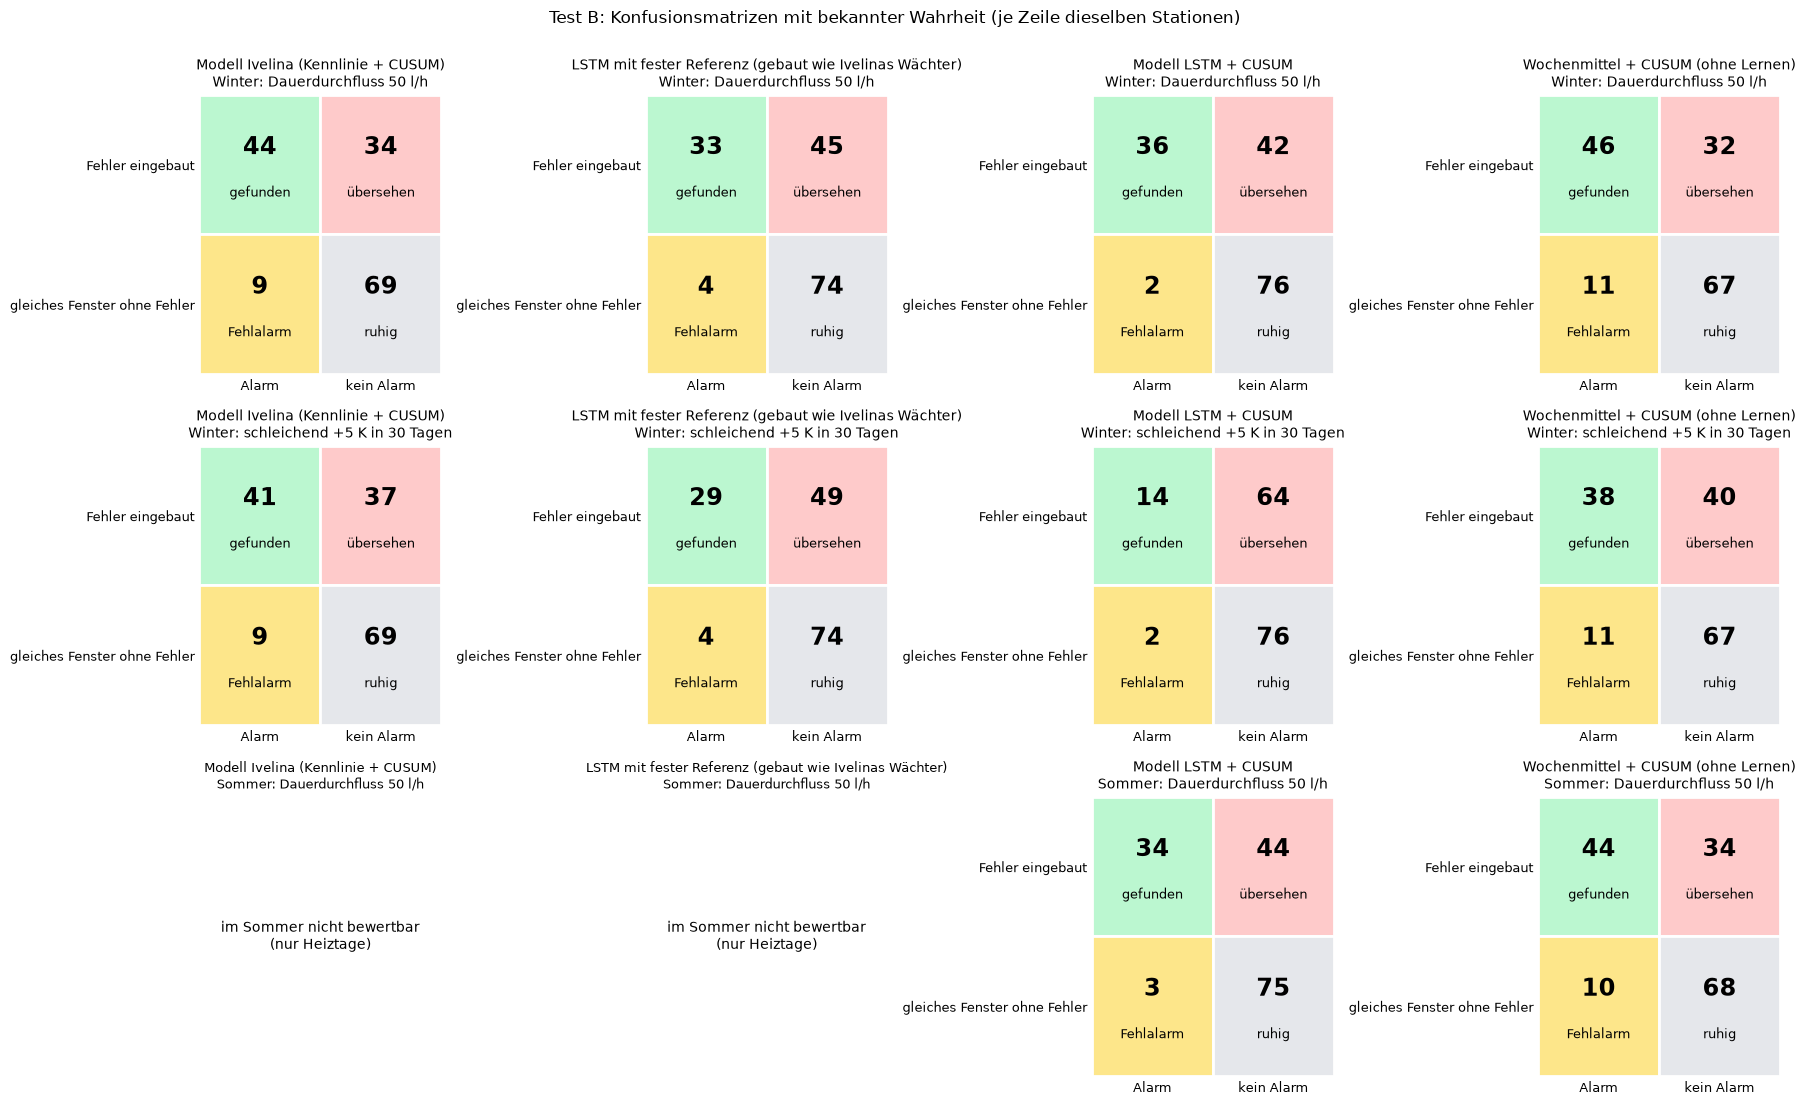

In [21]:
def vierfeld_stoerung(sa, key, saison, art):
    t = sa[(sa["key"] == key) & (sa["saison"] == saison) & sa["bewertbar"]]
    mit = t[t["art"] == art].set_index("zaehler")["alarm"]
    ohne = t[t["art"] == "ohne Fehler"].set_index("zaehler")["alarm"].reindex(mit.index).dropna().astype(bool)
    mit = mit.reindex(ohne.index)
    return {"gefunden": int(mit.sum()), "übersehen": int((~mit).sum()),
            "Fehlalarm": int(ohne.sum()), "ruhig": int((~ohne).sum())}

faelle_bild = [("Winter", "Dauerdurchfluss 50 l/h"), ("Winter", "schleichend +5 K in 30 Tagen"),
               ("Sommer", "Dauerdurchfluss 50 l/h")]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for i, (saison, art) in enumerate(faelle_bild):
    for j, key in enumerate(["ivelina", "nv", "lstm_c", "wm_c"]):
        ax = axes[i, j]
        if saison == "Sommer" and key in ("ivelina", "nv"):
            ax.text(0.5, 0.5, "im Sommer nicht bewertbar\n(nur Heiztage)", ha="center", va="center")
            ax.axis("off")
            ax.set_title(f"{fv.WAECHTER[key]}\n{saison}: {art}", fontsize=9)
            continue
        fv.zeichne_vierfeld(ax, vierfeld_stoerung(SA, key, saison, art), f"{fv.WAECHTER[key]}\n{saison}: {art}",
                            zeile_ja="Fehler eingebaut", zeile_nein="gleiches Fenster ohne Fehler",
                            spalte_ja="Alarm", spalte_nein="kein Alarm",
                            woerter=("gefunden", "übersehen", "Fehlalarm", "ruhig"))
fig.suptitle("Test B: Konfusionsmatrizen mit bekannter Wahrheit (je Zeile dieselben Stationen)", y=1.0)
fig.tight_layout()
fv.speichere(fig, "04_testB_konfusion")
plt.show()

**Fair über alle Einstellungen:** Wer öfter alarmiert, findet mehr und hat mehr Fehlalarme. Deshalb zeigt
die nächste Grafik für jeden Wächter alle Einstellungen. Nach rechts steigen die Fehlalarme in sauberen
Fenstern, nach oben die gefundenen Fehler. **Weiter oben links ist besser.** Darunter steht die
Trefferquote bei höchstens 10 % bzw. 5 % Fehlalarmen. Diese Werte sind auf dem Test abgelesen. Sie dienen
**nur dem Vergleich**, nicht zum Einstellen.

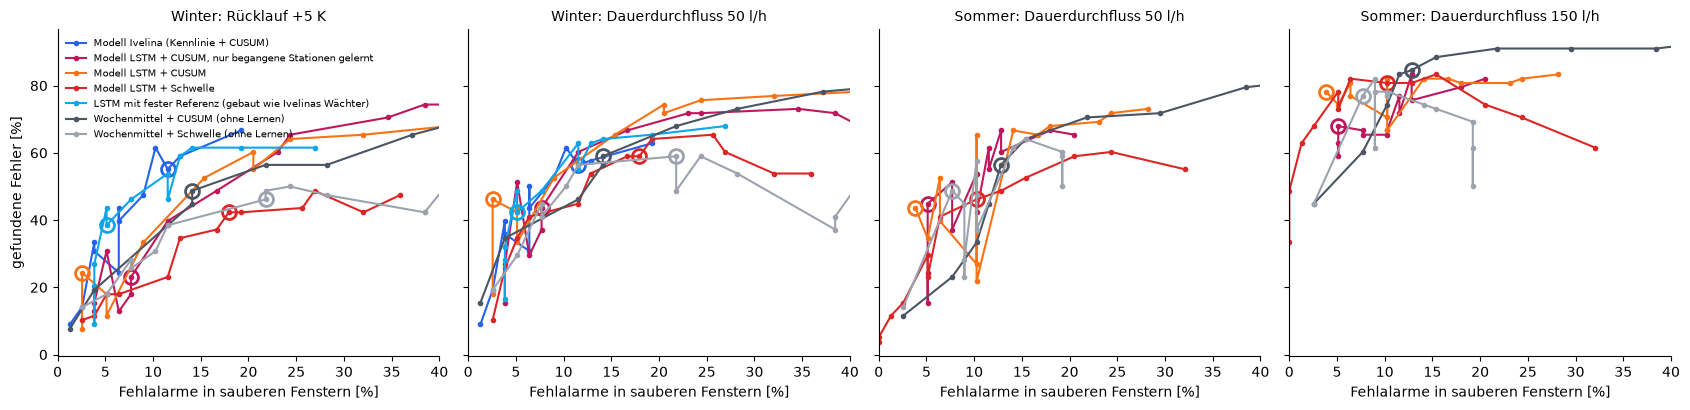

In [22]:
SK = fv.stoerungen_kurve(ST, w)
zeigen = [("Winter", "Rücklauf +5 K"), ("Winter", "Dauerdurchfluss 50 l/h"), ("Sommer", "Dauerdurchfluss 50 l/h"),
          ("Sommer", "Dauerdurchfluss 150 l/h")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, (saison, art) in zip(axes, zeigen):
    for key, g in SK[(SK["saison"] == saison) & (SK["art"] == art)].groupby("key"):
        g = g.sort_values("Fehlalarmquote")
        ax.plot(100 * g["Fehlalarmquote"], 100 * g["Trefferquote"], "-o", ms=3, color=farben[key], label=fv.WAECHTER[key])
        s = g[g["gewählt"]]
        ax.plot(100 * s["Fehlalarmquote"], 100 * s["Trefferquote"], "o", ms=10, mfc="none", mec=farben[key], mew=2)
    ax.set_title(f"{saison}: {art}", fontsize=10)
    ax.set_xlabel("Fehlalarme in sauberen Fenstern [%]")
    ax.set_xlim(0, 40)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("gefundene Fehler [%]")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fv.speichere(fig, "05_testB_kurven")
plt.show()

In [23]:
def bester_bei(g, fa):
    ok = g[g["Fehlalarmquote"] <= fa + 1e-9]
    return ok["Trefferquote"].max() if len(ok) else np.nan

gleich10 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.10)).unstack("Wächter")
gleich5 = SK.groupby(["saison", "art", "Wächter"]).apply(lambda g: bester_bei(g, 0.05)).unstack("Wächter")
print("Trefferquote bei höchstens 10 % Fehlalarmen")
display(gleich10.round(2))
print("Trefferquote bei höchstens 5 % Fehlalarmen")
gleich5.round(2)

Trefferquote bei höchstens 10 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie Ivelinas Wächter)  Modell Ivelina (Kennlinie + CUSUM)  Modell LSTM + CUSUM  Modell LSTM + CUSUM, nur begangene Stationen gelernt  \
saison art                                                                                                                                                                                                   
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                      NaN                 0.81                                               0.68      
       Dauerdurchfluss 50 l/h                                                      NaN                                      NaN                 0.53                                               0.51      
       Fühler hängt                                                                NaN                                      NaN                 0.36                                               0.33      
       Regelhysterese 6 h                                                          NaN                                      NaN                 0.10                                               0.09      
       Rücklauf +5 K                                                               NaN                                      NaN                 0.24                                               0.14      
       schleichend +5 K in 30 Tagen                                                NaN                                      NaN                 0.24                                               0.19      
Winter Dauerdurchfluss 150 l/h                                                    0.74                                     0.77                 0.73                                               0.72      
       Dauerdurchfluss 50 l/h                                                     0.49                                     0.53                 0.53                                               0.51      
       Fühler hängt                                                               0.44                                     0.46                 0.38                                               0.37      
       Regelhysterese 6 h                                                         0.12                                     0.09                 0.15                                               0.12      
       Rücklauf +5 K                                                              0.46                                     0.47                 0.33                                               0.31      
       schleichend +5 K in 30 Tagen                                               0.38                                     0.42                 0.27                                               0.28      

Wächter                              Modell LSTM + Schwelle  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                              
Sommer Dauerdurchfluss 150 l/h                         0.82                                0.60                                   0.82  
       Dauerdurchfluss 50 l/h                          0.41                                0.23                                   0.49  
       Fühler hängt                                    0.31                                0.12                                   0.31  
       Regelhysterese 6 h                              0.12                                0.08                                   0.12  
       Rücklauf +5 K                                   0.22                                0.15                                   0.22  
       schleichend +5 K in 30 Tagen                    0.22                                0.13                                   0.26  
Winter Dauerdurchfl

Trefferquote bei höchstens 5 % Fehlalarmen


Wächter                              LSTM mit fester Referenz (gebaut wie Ivelinas Wächter)  Modell Ivelina (Kennlinie + CUSUM)  Modell LSTM + CUSUM  Modell LSTM + CUSUM, nur begangene Stationen gelernt  \
saison art                                                                                                                                                                                                   
Sommer Dauerdurchfluss 150 l/h                                                     NaN                                      NaN                 0.78                                                NaN      
       Dauerdurchfluss 50 l/h                                                      NaN                                      NaN                 0.44                                                NaN      
       Fühler hängt                                                                NaN                                      NaN                 0.36                                                NaN      
       Regelhysterese 6 h                                                          NaN                                      NaN                 0.08                                                NaN      
       Rücklauf +5 K                                                               NaN                                      NaN                 0.12                                                NaN      
       schleichend +5 K in 30 Tagen                                                NaN                                      NaN                 0.18                                                NaN      
Winter Dauerdurchfluss 150 l/h                                                    0.63                                     0.67                 0.69                                               0.45      
       Dauerdurchfluss 50 l/h                                                     0.32                                     0.40                 0.46                                               0.27      
       Fühler hängt                                                               0.29                                     0.31                 0.27                                               0.13      
       Regelhysterese 6 h                                                         0.04                                     0.05                 0.10                                               0.04      
       Rücklauf +5 K                                                              0.27                                     0.33                 0.24                                               0.15      
       schleichend +5 K in 30 Tagen                                               0.26                                     0.31                 0.18                                               0.15      

Wächter                              Modell LSTM + Schwelle  Wochenmittel + CUSUM (ohne Lernen)  Wochenmittel + Schwelle (ohne Lernen)  
saison art                                                                                                                              
Sommer Dauerdurchfluss 150 l/h                         0.68                                0.45                                   0.45  
       Dauerdurchfluss 50 l/h                          0.15                                0.12                                   0.14  
       Fühler hängt                                    0.17                                0.03                                   0.05  
       Regelhysterese 6 h                              0.04                                0.03                                   0.03  
       Rücklauf +5 K                                   0.10                                0.05                                   0.06  
       schleichend +5 K in 30 Tagen                    0.10                                0.06                                   0.05  
Winter Dauerdurchfl

## Was Test B heißt

- **Winter: Modell Ivelina findet bei gleicher Fehlalarmquote am meisten.** Trefferquote bei höchstens
  10 % Fehlalarmen in 14 Tagen:

  | eingebauter Fehler | Modell Ivelina | LSTM mit fester Referenz | Prognose-LSTM |
  |---|---:|---:|---:|
  | Rücklauf +5 K | 47 % | 46 % | 33 % |
  | schleichend +5 K | 42 % | 38 % | 27 % |
  | Fühler hängt | 46 % | 44 % | 38 % |
  | Dauerdurchfluss 150 l/h | 77 % | 74 % | 73 % |
  | Dauerdurchfluss 50 l/h | 53 % | 49 % | 53 % |

- **Sommer: Nur das Prognose-LSTM kann prüfen, und dort ist es am besten.** Ivelinas Wächter und das LSTM
  mit fester Referenz rechnen an warmen Tagen nicht (0 % bewertbar). Das Prognose-LSTM mit CUSUM findet
  bei höchstens 5 % Fehlalarmen:
  - 78 % der Dauerdurchflüsse mit 150 l/h (Wochenmittel 45 %),
  - 44 % mit 50 l/h (Wochenmittel 12 bis 14 %).
- **Das Prognose-LSTM nur auf begangenen Stationen** ist im Sommer schwächer: Dauerdurchfluss 150 l/h
  68 % statt 81 % bei 10 % Fehlalarmen, und unter 5 % Fehlalarme kommt es gar nicht. Für die Rolle
  „warme Tage“ bleibt deshalb die Fassung auf allen Stationen.
- **Für das LSTM die Regel CUSUM statt Schwelle:** gleiche oder bessere Trefferquote bei weniger
  Fehlalarmen. In der gewählten Einstellung sind es 3 bis 4 % statt 10 bis 18 %.
- **Regelhysterese findet keins der Modelle** (höchstens 15 %). Die Tagesmengen bleiben gleich, und alle
  Wächter rechnen mit Tagesmitteln.
- **Schnelligkeit:** Dauerdurchfluss melden alle nach 1 bis 3 Tagen, schleichende Fehler erst nach 2 bis
  3 Wochen.
- **Grenze:** Eingebaute Fehler sind sauber, echte nicht. Die Zahlen bei 5 % Fehlalarmen beruhen auf
  wenigen sauberen Fenstern und schwanken stärker als die bei 10 %.

## 7b · Ist Ivelinas Modell nur im Vorteil, weil es für den Winter gebaut ist?

Gegenüber stehen drei Wächter auf denselben Heiztagen:
- Ivelinas Kennlinie,
- das LSTM mit **derselben** Bauweise (feste Referenz, gleiche Regel),
- das Prognose-LSTM mit Kurzzeitgedächtnis.

Verglichen wird ohne gewählte Einstellung:
- **Test A:** der Vorsprung vor der Kontrolle bei etwa gleicher Arbeitslast im Test (der Punkt jeder Kurve,
  der 4,3 Alarmen je Station und Jahr am nächsten liegt, so viele wie Ivelinas eigene Einstellung);
- **Test B:** die Trefferquote im Winter bei höchstens 10 % Fehlalarmen.

Dazu kommt die Vorhersagegenauigkeit auf denselben Testtagen.

In [24]:
zeilen = []
for key in ["ivelina", "nv", "lstm_c"]:
    k = KA[KA["key"] == key].copy()
    nah = k.iloc[(k["Arbeitslast"] - 4.34).abs().argmin()]
    z = {"Wächter": fv.WAECHTER[key], "Test A: Arbeitslast": nah["Arbeitslast"], "Test A: Vorsprung [Pp.]": 100 * nah["Vorsprung"]}
    for art in ["Rücklauf +5 K", "schleichend +5 K in 30 Tagen", "Dauerdurchfluss 50 l/h", "Dauerdurchfluss 150 l/h", "Fühler hängt"]:
        z[f"Test B Winter: {art}"] = gleich10.loc[("Winter", art), fv.WAECHTER[key]]
    zeilen.append(z)
vergleich_nv = pd.DataFrame(zeilen).set_index("Wächter")
display(vergleich_nv.round(2).T)
m = w["verlauf"].merge(w["nv"]["verlauf"], on=["meter", "kanal", "datum"], suffixes=("_iv", "_nv"))
m = m[m["datum"] >= fv.TEST_START]
fehler = m.assign(Kennlinie=(m["wert_iv"] - m["erwartung_iv"]).abs(), LSTM_feste_Referenz=(m["wert_nv"] - m["erwartung_nv"]).abs())
print("Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):")
fehler.groupby("kanal")[["Kennlinie", "LSTM_feste_Referenz"]].median().round(3)

Wächter,Modell Ivelina (Kennlinie + CUSUM),LSTM mit fester Referenz (gebaut wie Ivelinas Wächter),Modell LSTM + CUSUM
Test A: Arbeitslast,4.34,4.06,4.58
Test A: Vorsprung [Pp.],18.15,16.81,-5.64
Test B Winter: Rücklauf +5 K,0.47,0.46,0.33
Test B Winter: schleichend +5 K in 30 Tagen,0.42,0.38,0.27
Test B Winter: Dauerdurchfluss 50 l/h,0.53,0.49,0.53
Test B Winter: Dauerdurchfluss 150 l/h,0.77,0.74,0.73
Test B Winter: Fühler hängt,0.46,0.44,0.38


Mittlerer absoluter Vorhersagefehler im Test (Median über Tage):


,Kennlinie,LSTM_feste_Referenz
kanal,,
kwh_pro_m3,3.621,3.310
log_volumen,0.250,0.236


## Was 7b heißt

- **Gleich gut.** Bei etwa gleicher Arbeitslast (gut 4 Alarme je Station und Jahr) liegt der Vorsprung
  vor der Kontrolle bei 18 Prozentpunkten (Ivelina) und 17 (LSTM mit fester Referenz). Im Winter liegen
  die eingebauten Fehler je 1 bis 4 Prozentpunkte auseinander.
- **Das Netz sagt etwas genauer voraus**, mittlerer Fehler 3,31 gegen 3,62 kWh/m³ bei der Abkühlung.
  Daraus folgen aber keine besseren Alarme.
- **Das Prognose-LSTM mit Kurzzeitgedächtnis** liegt bei derselben Arbeitslast unter der Kontrolle
  (−6 Prozentpunkte) und findet im Winter deutlich weniger.
- **Was das heißt:**
  - Ivelinas Modell ist nicht besser, weil eine Gerade besser rechnet als ein Netz. Es ist besser, weil es
    mit einer **festen Referenz** vergleicht und deshalb bleibende Veränderungen nicht „vergisst“.
  - Ein LSTM, das genauso gebaut ist, kann dasselbe, aber nicht mehr.
  - Bei Gleichstand gewinnt das Einfachere. Die Kennlinie bleibt im Dashboard: erklärbar, ohne Grafikkarte,
    je Station nachvollziehbar.
- **Vorsicht bei der Einstellung:** In der Einstellzeit (April/Mai) wählte das Raster für das Netz h = 15.
  Im Test gibt es damit nur 2,7 Alarme je Station und Jahr. Die kleine Einstellzeit (31 Alarme) macht die
  Wahl unsicher, deshalb zählen hier die Kurven.

## 7c · Lohnt ein eigenes LSTM nur für den Sommer?

Ein Prognose-LSTM lernt nur auf warmen Tagen (Tagesmittel ab 15 °C) und wird auf den warmen Tagen der
Probezeit kalibriert. Es läuft auf denselben Sommerfällen aus Test B wie das ganzjährige LSTM, Regel
CUSUM, über das ganze Raster.

In [25]:
som = fv.sommer_lstm_pruefen(w, e, ST, log=lambda *a: None)
k = som["lernkurve"]
print(f"Sommer-LSTM: {som['lern_ziele']} Lerntage, {som['pruef_ziele']} Prüftage; bester Prüffehler {k['validierung'].min():.2f} "
      f"(ganzjähriges LSTM: {w['lstm']['lernkurve']['validierung'].min():.2f})")
for grenze in (0.10, 0.05):
    print(f"Trefferquote bei höchstens {grenze:.0%} Fehlalarmen, Sommer")
    display(som["kurve"][som["kurve"]["Fehlalarmquote"] <= grenze + 1e-9].groupby(["art", "modell"])["Trefferquote"].max()
            .unstack().round(2))

Sommer-LSTM: 5729 Lerntage, 2038 Prüftage; bester Prüffehler 12.73 (ganzjähriges LSTM: 0.10)
Trefferquote bei höchstens 10% Fehlalarmen, Sommer


modell,ganzjährig gelernt,nur Sommertage gelernt
art,,
Dauerdurchfluss 150 l/h,0.81,0.83
Dauerdurchfluss 50 l/h,0.53,0.49
Fühler hängt,0.36,0.38
Regelhysterese 6 h,0.10,0.14
Rücklauf +5 K,0.24,0.18
schleichend +5 K in 30 Tagen,0.24,0.23


Trefferquote bei höchstens 5% Fehlalarmen, Sommer


modell,ganzjährig gelernt
art,
Dauerdurchfluss 150 l/h,0.78
Dauerdurchfluss 50 l/h,0.44
Fühler hängt,0.36
Regelhysterese 6 h,0.08
Rücklauf +5 K,0.12
schleichend +5 K in 30 Tagen,0.18


## Was 7c heißt

- **Ein eigenes Sommer-LSTM lohnt sich nicht.**
  - Es hat nur einen Sommer (2023) zum Lernen.
  - Schon auf den warmen Tagen im Frühjahr 2024 liegt es weit daneben: Prüffehler 12,7 gegen 0,10 beim
    ganzjährigen Netz. Es kennt nur kleine Sommer-Durchflüsse.
  - Bei 10 % Fehlalarmen ist es mal etwas besser, mal schlechter (Dauerdurchfluss 150 l/h: 83 % gegen
    81 %; Rücklauf +5 K: 18 % gegen 24 %).
  - Unter 5 % Fehlalarme kommt es mit keiner Einstellung.
- **Die Aufteilung nach Jahreszeit gelingt besser über die Wahl des Wächters:**
  - Heizperiode: Ivelinas Kennlinie,
  - warme Tage: das ganzjährig gelernte Prognose-LSTM.
- Ein Modell je Jahreszeit hätte nur halb so viele Lerndaten und wäre eher überangepasst.

## 8 · Test C: Welche Station hat welchen Fehler?

**Frage:** Kann ein Modell aus den Daten **vor** der Begehung sagen, welche Maßnahme nötig war?

**So prüfen wir:**
- 53 begangene Stationen, nämlich alle mit genug Daten im Winter 23/24 und im Sommer 2024 vor der
  Begehung (dieselbe Menge wie in Notebook 22, 32 und im Audit).
- Fünf Durchgänge: Jedes Mal sind etwa 11 Stationen Test, die übrigen Lernen. Das LSTM-Embedding wird in
  jedem Durchgang neu gelernt, **nur auf den begangenen Lernstationen** (wie vorgegeben), nie auf den
  Teststationen. Die Fassung mit allen Stationen läuft als Gegenprobe.
- Ivelinas Netzvergleich braucht keine Labels. Er wird einmal für den Winter 23/24 gerechnet: vor allen
  Begehungen, jede Station gegen alle anderen.
- Kandidaten:
  - logistische Regression (LR) auf Kennzahlen, auf Kennzahlen + LSTM, auf LSTM allein;
  - XGBoost auf Kennzahlen und auf Kennzahlen + LSTM;
  - Regeln ohne Lernen;
  - Ivelinas Netz-Score und Fehlerbild.
- Gemessen wird:
  - **AUC**: Wie oft steht eine Station mit Befund vor einer ohne? 0,5 = Raten, 1 = perfekt.
  - **Konfusionsmatrix** an der festen Grenze.

In [26]:
KL = fv.klassifikation(e, log=lambda *a: None, nur_begangene=True)
print("Stationen:", len(KL["basis"]), "| Ventil:", int(KL["basis"]["ventil"].sum()), "| Dämmung:", int(KL["basis"]["daemmung"].sum()))
KL["fold_info"]

Stationen: 53 | Ventil: 11 | Dämmung: 22


,fold,Teststationen,Lernstationen Encoder,Lernpaare,Prüfpaare,Ventil im Test
0,0,11,43,16988,2227,2
1,1,11,43,16282,2167,2
2,2,11,43,17250,2116,3
3,3,10,44,17339,2171,2
4,4,10,44,18009,2235,2


In [27]:
assert len(KL["basis"]) == 53
for k, (tr, te) in enumerate(KL["folds"]):
    assert not set(e["gruppen"].reindex(KL["basis"].index[tr])) & set(e["gruppen"].reindex(KL["basis"].index[te]))
netz = fv.netzvergleich(e["serien"], termine, e["anschluss"], e["bhkw"])
iv = fv.ivelina_je_station(netz, "23/24", al_g)
print("Netzvergleich Winter 23/24:", len(iv), "Stationen,", int(iv["auffaellig"].sum()), "auffällig")
print("Fehlerbilder:", iv["fehlerbild"].replace("", "keins").value_counts().to_dict())

Netzvergleich Winter 23/24: 86 Stationen, 9 auffällig
Fehlerbilder: {'keins': 62, 'unruhig': 9, 'ventil': 8, 'durchfluss_je_kw': 3, 'rücklauf': 2, 'regelung': 1, 'durchfluss': 1}


### Ventil (Reparatur nach Folie 5)

In [28]:
tab_ventil = fv.bewertung_tabelle(KL, iv, e["gruppen"], "ventil")
tab_ventil.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu Regel Sommernacht-Anteil,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,11,0.816,0.598,0.976,-0.035,-0.113,0.034,8,3,5,37,0.615,0.727,0.667
1,LR Kennzahlen + LSTM,53,11,0.883,0.731,0.996,0.032,-0.092,0.167,8,3,3,39,0.727,0.727,0.727
2,LR nur LSTM-Embedding,53,11,0.833,0.641,0.975,-0.017,-0.202,0.128,8,3,4,38,0.667,0.727,0.696
3,Regel Sommernacht-Anteil,53,11,0.851,0.679,0.980,NaN,NaN,NaN,9,2,5,37,0.643,0.818,0.720
4,XGBoost Kennzahlen,53,11,0.816,0.604,0.978,-0.035,-0.114,0.015,7,4,4,38,0.636,0.636,0.636
5,XGBoost Kennzahlen + LSTM,53,11,0.877,0.752,0.972,0.026,-0.054,0.136,7,4,4,38,0.636,0.636,0.636
6,Modell Ivelina (Netz-Score / Fehlerbild),53,11,0.734,0.548,0.906,-0.117,-0.286,0.028,4,7,0,42,1.000,0.364,0.533


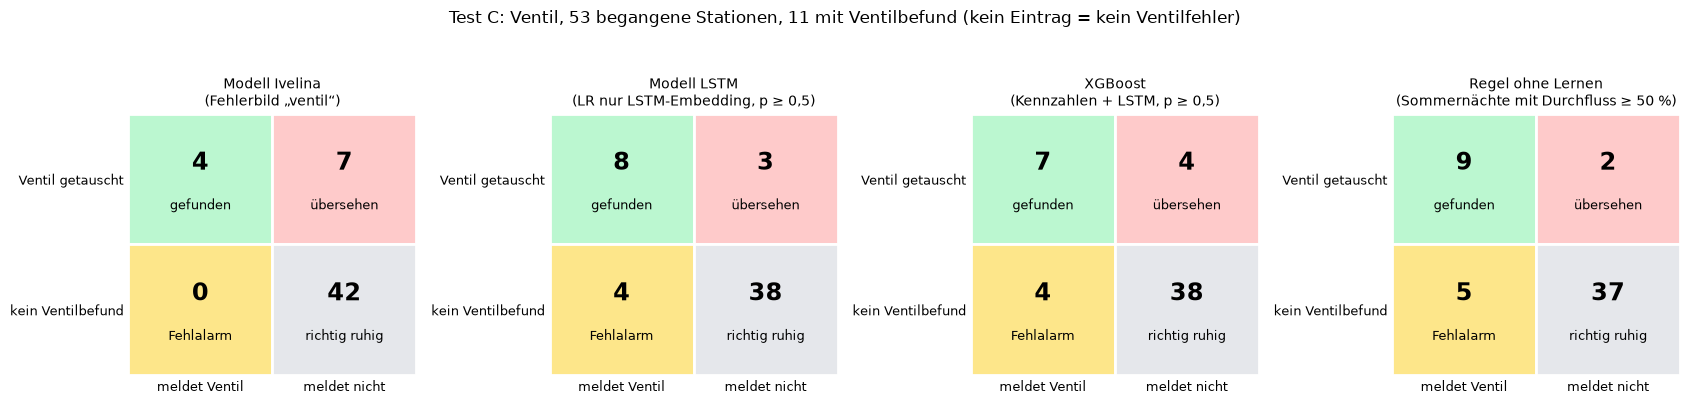

In [29]:
bv = fv.oof_breit(KL, "ventil").join(iv[["fehlerbild"]])
kandidaten_bild = [("Modell Ivelina\n(Fehlerbild „ventil“)", bv["fehlerbild"].eq("ventil")),
                   (f"Modell LSTM\n({fv.ENDMODELL}, p ≥ 0,5)", bv[fv.ENDMODELL] >= 0.5),
                   ("XGBoost\n(Kennzahlen + LSTM, p ≥ 0,5)", bv["XGBoost Kennzahlen + LSTM"] >= 0.5),
                   ("Regel ohne Lernen\n(Sommernächte mit Durchfluss ≥ 50 %)", bv["Regel Sommernacht-Anteil"] >= 0.5)]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, entscheidung) in zip(axes, kandidaten_bild):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bv["y"], entscheidung), name, spalte_ja="meldet Ventil", spalte_nein="meldet nicht",
                        zeile_ja="Ventil getauscht", zeile_nein="kein Ventilbefund")
fig.suptitle("Test C: Ventil, 53 begangene Stationen, 11 mit Ventilbefund (kein Eintrag = kein Ventilfehler)", y=1.05)
fig.tight_layout()
fv.speichere(fig, "06_testC_ventil")
plt.show()

### Dämmung

In [30]:
tab_daemmung = fv.bewertung_tabelle(KL, iv, e["gruppen"], "daemmung")
tab_daemmung.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,53,22,0.735,0.589,0.864,NaN,NaN,NaN,14.0,8.0,7.0,24.0,0.667,0.636,0.651
1,LR Kennzahlen + LSTM,53,22,0.802,0.664,0.919,0.067,-0.045,0.183,14.0,8.0,5.0,26.0,0.737,0.636,0.683
2,LR nur LSTM-Embedding,53,22,0.789,0.648,0.905,0.054,-0.062,0.179,15.0,7.0,7.0,24.0,0.682,0.682,0.682
3,XGBoost Kennzahlen,53,22,0.686,0.524,0.834,-0.048,-0.180,0.073,14.0,8.0,10.0,21.0,0.583,0.636,0.609
4,XGBoost Kennzahlen + LSTM,53,22,0.865,0.744,0.956,0.130,0.006,0.264,15.0,7.0,4.0,27.0,0.789,0.682,0.732
5,Modell Ivelina (Netz-Score / Fehlerbild),53,22,0.380,0.214,0.552,-0.355,-0.587,-0.108,NaN,NaN,NaN,NaN,NaN,NaN,NaN


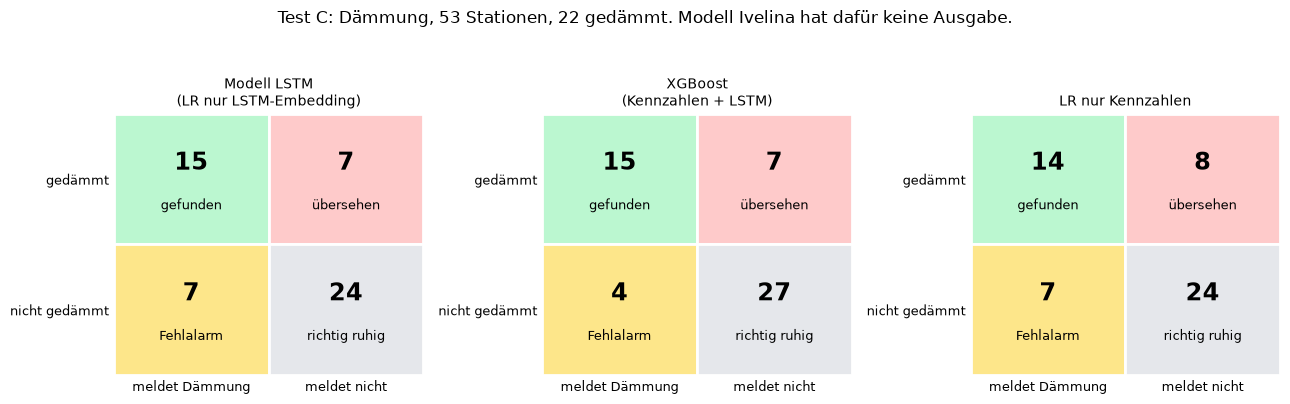

In [31]:
bd = fv.oof_breit(KL, "daemmung")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, spalte) in zip(axes, [(f"Modell LSTM\n({fv.ENDMODELL})", fv.ENDMODELL),
                                     ("XGBoost\n(Kennzahlen + LSTM)", "XGBoost Kennzahlen + LSTM"),
                                     ("LR nur Kennzahlen", "LR Kennzahlen")]):
    fv.zeichne_vierfeld(ax, fv.vierfeld(bd["y"], bd[spalte] >= 0.5), name, spalte_ja="meldet Dämmung",
                        spalte_nein="meldet nicht", zeile_ja="gedämmt", zeile_nein="nicht gedämmt")
fig.suptitle("Test C: Dämmung, 53 Stationen, 22 gedämmt. Modell Ivelina hat dafür keine Ausgabe.", y=1.05)
fig.tight_layout()
fv.speichere(fig, "07_testC_daemmung")
plt.show()

### Überdimensionierung (Kapazitätsanpassung) und die übrigen Maßnahmen

In [32]:
tab_ueber = fv.bewertung_tabelle(KL, iv, e["gruppen"], "ueberdimensioniert")
tab_ueber.round(3)

,Kandidat,Stationen,Befunde,AUC,AUC unten,AUC oben,Differenz zu LR Kennzahlen,Diff. unten,Diff. oben,gefunden,übersehen,Fehlalarm,richtig ruhig,Precision,Recall,F1
0,LR Kennzahlen,35,9,0.393,0.184,0.629,NaN,NaN,NaN,2.0,7.0,10.0,16.0,0.167,0.222,0.190
1,LR Kennzahlen + LSTM,35,9,0.325,0.121,0.546,-0.068,-0.260,0.107,2.0,7.0,11.0,15.0,0.154,0.222,0.182
2,LR nur LSTM-Embedding,35,9,0.491,0.264,0.724,0.098,-0.123,0.343,2.0,7.0,9.0,17.0,0.182,0.222,0.200
3,Regel Auslastung zum Vertrag,35,9,0.759,0.583,0.925,0.365,0.042,0.650,5.0,4.0,1.0,25.0,0.833,0.556,0.667
4,XGBoost Kennzahlen,35,9,0.530,0.328,0.727,0.137,-0.115,0.384,1.0,8.0,7.0,19.0,0.125,0.111,0.118
5,XGBoost Kennzahlen + LSTM,35,9,0.462,0.273,0.652,0.068,-0.200,0.308,0.0,9.0,7.0,19.0,0.000,0.000,0.000
6,Modell Ivelina (Netz-Score / Fehlerbild),35,9,0.598,0.352,0.837,0.205,-0.107,0.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
rest = []
for ziel in ["durchfluss", "temperatur", "filter"]:
    t = fv.bewertung_tabelle(KL, iv, e["gruppen"], ziel)
    for _, z in t.iterrows():
        rest.append({"Maßnahme": fv.ZIEL_TEXT[ziel], "Kandidat": z["Kandidat"], "Befunde": z["Befunde"],
                     "AUC": z["AUC"], "AUC unten": z["AUC unten"], "AUC oben": z["AUC oben"]})
rest = pd.DataFrame(rest)
rest.pivot_table(index="Kandidat", columns="Maßnahme", values="AUC").round(2)

Maßnahme,Durchfluss neu eingestellt,Filter gereinigt,Rücklauf-Sollwert gesenkt
Kandidat,,,
LR Kennzahlen,0.32,0.43,0.38
LR Kennzahlen + LSTM,0.29,0.30,0.33
LR nur LSTM-Embedding,0.36,0.31,0.30
Modell Ivelina (Netz-Score / Fehlerbild),0.53,0.57,0.51
XGBoost Kennzahlen,0.37,0.48,0.38
XGBoost Kennzahlen + LSTM,0.42,0.46,0.26


Werte deutlich unter 0,5 bedeuten hier kein umgekehrtes Signal. Bei kleinen Stichproben in der
Kreuzvalidierung landen Modelle ohne echten Zusammenhang oft unter 0,5. Entscheidend ist, dass das
Intervall die 0,5 einschließt oder darunter liegt: **nicht erkennbar**.

### Wie stabil ist das? Andere Startgewichte für das LSTM

Das Embedding hängt von den zufälligen Startgewichten des Netzes ab. Dieselben Folds mit zwei weiteren
Seeds:

In [34]:
stab = fv.stabilitaet(e, seeds=(1, 2), log=lambda *a: None)
haupt = []
for ziel in ("ventil", "daemmung"):
    b = fv.oof_breit(KL, ziel)
    for c in ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM"):
        from sklearn.metrics import roc_auc_score
        vf = fv.vierfeld(b["y"], b[c] >= 0.5)
        haupt.append({"Seed": 0, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                      "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
stab = pd.concat([pd.DataFrame(haupt), stab], ignore_index=True)
stab.pivot_table(index=["Ziel", "Kandidat"], columns="Seed", values="AUC").round(3)

Seed                                    0      1      2
Ziel     Kandidat                                      
daemmung LR Kennzahlen + LSTM       0.802  0.796  0.836
         LR nur LSTM-Embedding      0.789  0.789  0.768
         XGBoost Kennzahlen + LSTM  0.865  0.765  0.743
ventil   LR Kennzahlen + LSTM       0.883  0.890  0.885
         LR nur LSTM-Embedding      0.833  0.840  0.903
         XGBoost Kennzahlen + LSTM  0.877  0.842  0.877

### Gegenprobe: Encoder auf allen Stationen statt nur auf begangenen

In [35]:
from sklearn.metrics import roc_auc_score
namen = ("LR Kennzahlen + LSTM", "LR nur LSTM-Embedding", "XGBoost Kennzahlen + LSTM")
KL_alle = fv.klassifikation(e, log=lambda *a: None, ziele=("ventil", "daemmung"), kandidaten=namen, nur_begangene=False)
zeilen = []
for fassung, kl in (("nur begangene (Hauptlauf)", KL), ("alle Stationen (Gegenprobe)", KL_alle)):
    for ziel in ("ventil", "daemmung"):
        b = fv.oof_breit(kl, ziel)
        for c in namen:
            vf = fv.vierfeld(b["y"], b[c] >= 0.5)
            zeilen.append({"Encoder gelernt auf": fassung, "Ziel": ziel, "Kandidat": c, "AUC": roc_auc_score(b["y"], b[c]),
                           "gefunden": vf["gefunden"], "Fehlalarm": vf["Fehlalarm"]})
vergleich_beg = pd.DataFrame(zeilen)
vergleich_beg.pivot_table(index=["Ziel", "Kandidat"], columns="Encoder gelernt auf", values=["AUC", "Fehlalarm"]).round(3)

AUC                                             Fehlalarm                          
Encoder gelernt auf                alle Stationen (Gegenprobe) nur begangene (Hauptlauf) alle Stationen (Gegenprobe) nur begangene (Hauptlauf)
Ziel     Kandidat                                                                                                                             
daemmung LR Kennzahlen + LSTM                            0.782                     0.802                         7.0                       5.0
         LR nur LSTM-Embedding                           0.812                     0.789                         7.0                       7.0
         XGBoost Kennzahlen + LSTM                       0.716                     0.865                         6.0                       4.0
ventil   LR Kennzahlen + LSTM                            0.881                     0.883                         5.0                       3.0
         LR nur LSTM-Embedding                           0.866                     0.833                         6.0                       4.0
         XGBoost Kennzahlen + LSTM                       0.805                     0.877                         3.0                       4.0

### XGBoost erklärt: welche Merkmale den Ventilverdacht tragen

Für jede Teststation zerlegt XGBoost seine Entscheidung in **Beiträge je Merkmal** (TreeSHAP, in XGBoost
eingebaut). Ein positiver Beitrag schiebt den Verdacht nach oben. Ausgangswert plus alle Beiträge ergibt
den Logit, daraus p = 1 / (1 + e^(−Logit)).

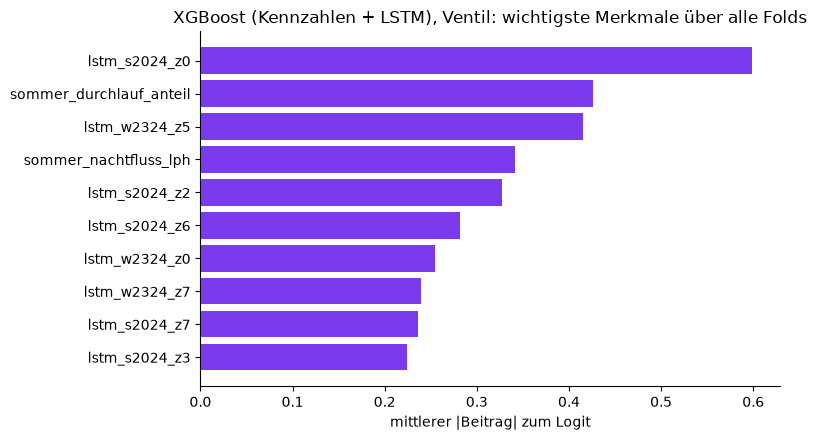

Die 5 wichtigsten Merkmale je Fold:
  Fold 0: lstm_s2024_z0, lstm_w2324_z4, lstm_w2324_z2, lstm_w2324_z7, lstm_w2324_z5
  Fold 1: lstm_s2024_z2, lstm_w2324_z7, sommer_durchlauf_anteil, streubreite_betriebspunkte, lstm_s2024_z6
  Fold 2: sommer_nachtfluss_lph, lstm_s2024_z6, lstm_w2324_z5, lstm_s2024_z0, lstm_w2324_z2
  Fold 3: sommer_durchlauf_anteil, lstm_s2024_z7, lstm_s2024_z3, lstm_w2324_z0, lstm_s2024_z2
  Fold 4: lstm_w2324_z5, lstm_w2324_z0, lstm_s2024_z0, lstm_s2024_z5, lstm_s2024_z4


In [36]:
beitr = KL["beitraege"].drop(columns=["fold"])
wichtig = beitr.drop(columns="basis").abs().mean().sort_values(ascending=False)
je_fold = KL["beitraege"].groupby("fold").apply(lambda g: g.drop(columns=["fold", "basis"], errors="ignore").abs().mean().nlargest(5).index.tolist())
fig, ax = plt.subplots(figsize=(8, 4.5))
top = wichtig.head(10)[::-1]
ax.barh(top.index, top.values, color=fv.FARBE_XGB)
ax.set_xlabel("mittlerer |Beitrag| zum Logit")
ax.set_title("XGBoost (Kennzahlen + LSTM), Ventil: wichtigste Merkmale über alle Folds")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fv.speichere(fig, "08_xgboost_beitraege")
plt.show()
print("Die 5 wichtigsten Merkmale je Fold:")
for k, liste in je_fold.items():
    print(f"  Fold {k}: {', '.join(liste)}")

In [37]:
fall = 68956351 if 68956351 in beitr.index else beitr.index[0]
b = beitr.loc[fall]
logit = b.sum()
zerlegung = b.drop("basis").sort_values(key=np.abs, ascending=False).head(6)
print(f"Station {fall}: Ausgangswert {b['basis']:+.2f}")
for name, wert in zerlegung.items():
    print(f"   {name:32s} {wert:+.2f}")
print(f"   übrige Merkmale                  {b.drop(['basis', *zerlegung.index]).sum():+.2f}")
print(f"Summe (Logit) {logit:+.2f}  ->  p(Ventil) = {1 / (1 + np.exp(-logit)):.2f}")
print("Kennzahlen dieser Station:", KL["kz"].loc[fall, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k"]].round(2).to_dict())

Station 68956351: Ausgangswert +0.58
   sommer_nachtfluss_lph            +0.85
   lstm_s2024_z6                    -0.73
   lstm_w2324_z2                    +0.60
   lstm_s2024_z0                    -0.56
   lstm_w2324_z5                    +0.54
   winter_nacht_tag_fluss           -0.41
   übrige Merkmale                  +0.57
Summe (Logit) +1.43  ->  p(Ventil) = 0.81
Kennzahlen dieser Station: {'sommer_durchlauf_anteil': 1.0, 'sommer_nachtfluss_lph': 518.0, 'winter_spreizung_last_k': 5.91}


### Die drei Klassen nach Folie 5

Befund aus der Begehung:
- **Reparatur**: Ventil getauscht.
- **Regelungsoptimierung**: Durchfluss neu eingestellt oder Rücklauf-Sollwert gesenkt.
- **keine dieser Maßnahmen**.

Modell LSTM: p(Ventil) ≥ 0,5, sonst K-Means. Modell Ivelina: Fehlerbild „ventil“, sonst ein anderes
Fehlerbild, sonst keins.

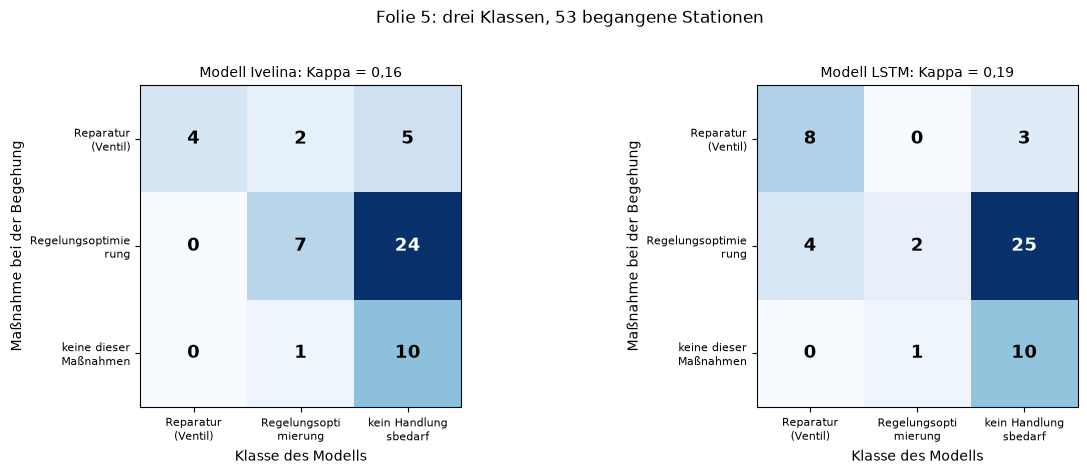

In [38]:
f5_befund = fv.folie5_befund(e["labels"].loc[KL["basis"].index])
p_v = fv.oof_breit(KL, "ventil")[fv.ENDMODELL]
f5_lstm = fv.folie5_lstm(p_v, KL["kmeans_klasse"].reindex(p_v.index))
f5_iv = fv.folie5_ivelina(iv["fehlerbild"].reindex(p_v.index).fillna(""))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (name, vorhersage) in zip(axes, [("Modell Ivelina", f5_iv), ("Modell LSTM", f5_lstm)]):
    m = pd.crosstab(f5_befund, vorhersage).reindex(index=fv.F5_KLASSEN, columns=fv.F5_KLASSEN, fill_value=0)
    m.index = ["Reparatur (Ventil)", "Regelungsoptimierung", "keine dieser Maßnahmen"]
    k = fv.kappa(f5_befund, vorhersage)
    fv.zeichne_matrix(ax, m, f"{name}: Kappa = {k:.2f}".replace(".", ","), "Klasse des Modells", "Maßnahme bei der Begehung")
fig.suptitle("Folie 5: drei Klassen, 53 begangene Stationen", y=1.02)
fig.tight_layout()
fv.speichere(fig, "09_folie5_matrizen")
plt.show()

### Gegenprobe mit späteren Daten: sinkt der Ventilverdacht, wo das Ventil getauscht wurde?

Beide Modelle laufen **unverändert** auf dem Winter 24/25 (und dem Sommer 2025, soweit vorhanden), also
nach den Begehungen. Wo das Ventil getauscht wurde, sollte der Verdacht sinken. Das ist eine Prüfung an
**bekannten Stationen in späterer Zeit**, ohne neu zu lernen.

In [39]:
teile = fv.fehlerklassen_teile(KL)
gp = fv.gegenprobe_nach_reparatur(teile, e, KL, netz)
from scipy import stats
zeilen = []
for gruppe, g in gp.groupby("gruppe"):
    g2 = g.dropna(subset=["p_ventil_vor", "p_ventil_nach"])
    p = stats.wilcoxon(g2["p_ventil_vor"], g2["p_ventil_nach"]).pvalue if len(g2) >= 6 else np.nan
    zeilen.append({"Gruppe": gruppe, "Stationen": len(g2), "p(Ventil) vorher, Median": g2["p_ventil_vor"].median(),
                   "p(Ventil) nachher, Median": g2["p_ventil_nach"].median(), "p (Wilcoxon)": p,
                   "Ivelina „ventil“ vorher": int(g["fehlerbild_vor"].eq("ventil").sum()),
                   "Ivelina „ventil“ nachher": int(g["fehlerbild_nach"].eq("ventil").sum())})
pd.DataFrame(zeilen).round(3)

,Gruppe,Stationen,"p(Ventil) vorher, Median","p(Ventil) nachher, Median",p (Wilcoxon),Ivelina „ventil“ vorher,Ivelina „ventil“ nachher
0,Ventil getauscht,11,0.707,0.254,0.042,4,1
1,"begangen, kein Ventil",43,0.265,0.075,0.000,0,1
2,nie begangen,37,0.301,0.231,0.066,4,4


## Was Test C heißt

**Gelernt wird hier nur auf begangenen Stationen**, wie dem Team vorgegeben. Die Fassung mit allen Stationen
ist die Gegenprobe: Beim Dashboard-Modell liegt sie etwas höher (Ventil 0,87 statt 0,83), hat aber mehr Fehlalarme
(6 statt 4).

- **Ventil (Reparatur):** Alle Kandidaten sind deutlich besser als Raten.
  - Modell LSTM (Regression nur auf den 16 LSTM-Zahlen, `fv.ENDMODELL`): AUC 0,83 [0,64; 0,98]. Mit anderen
    Startgewichten 0,84 und 0,90. Es schwankt also mehr als die Fassung mit Kennzahlen (0,88 bis 0,89).
  - Die einfache Sommernacht-Regel: 0,85 [0,68; 0,98].
  - Der Unterschied von −0,02 [−0,20; +0,13] ist **nicht gesichert**.
  - An der festen Grenze: LSTM 8 gefunden, 3 übersehen, 4 Fehlalarme (Precision 67 %).
    Regel: 9 / 2 / 5 (Precision 64 %).
- **Modell Ivelina beim Ventil:** Das Fehlerbild „ventil“ ist **genau, aber streng**.
  - 4 von 4 Meldungen richtig, aber nur 4 der 11 Fälle gefunden. Netz-Score AUC 0,73.
  - Als Bestätigung im Dashboard sehr gut, als alleiniger Finder zu streng.
- **Dämmung:**
  - Nur LSTM-Zahlen (Dashboard-Modell): AUC 0,79 [0,65; 0,90], mit anderen Seeds 0,79 und 0,77. Mit
    Kennzahlen dazu 0,80.
  - Kennzahlen allein: 0,73. Der Vorsprung (+0,05 [−0,06; +0,18]) ist **nicht gesichert**.
  - Gegen die beste an den Befunden angepasste Regel (0,61) liegt die KI deutlich vorn, knapp nicht gesichert (Abschnitt 15).
  - Ivelinas Netz-Score zeigt umgekehrt (0,38): Gedämmt wurde eher bei Stationen, die im Netz gut
    aussehen. Eine physikalische Erklärung dafür fehlt.
- **Überdimensionierung (Kapazitätsanpassung):** Nur die Regel „Spitzenlast zum alten Vertrag“ trägt:
  AUC 0,76 [0,58; 0,93], 5 von 9 gefunden bei 1 Fehlalarm. Gelernte Modelle scheitern (höchstens 0,53).
- **Durchfluss eingestellt, Sollwert gesenkt, Filter gereinigt:** für alle Kandidaten **nicht erkennbar**
  (AUC 0,26 bis 0,57). Das Dashboard darf diese Maßnahmen nicht als erkannte Fehlerart zeigen.
- **XGBoost** ist **nicht verlässlich**.
  - Beim Ventil in Test C 0,88, in der Validierung aber hinter der Regression (0,81 gegen 0,84, Abschnitt 16c).
  - Bei der Dämmung im Hauptlauf mit 0,87 vorn, mit anderen Startgewichten aber nur 0,77 und 0,74.
  - Seine wichtigsten Merkmale wechseln von Durchgang zu Durchgang. Stabil vorn sind nur
    Nachtdurchfluss und Anteil der Sommernächte mit Durchfluss, also dasselbe wie die einfache Regel.
  - Beim Ventilfall 68956351 ergibt sich p = 0,81 aus vielen kleinen Beiträgen, die sich teils aufheben.
  - **Nicht ins Dashboard.**
- **Folie 5:** Beide Modelle treffen die Reparatur-Klasse: Ivelina 4 von 11, LSTM 8 von 11.
  - Die Regelungsoptimierung trifft keins: 24 bzw. 25 der 31 Stationen mit eingestelltem Durchfluss oder
    gesenktem Sollwert landen in „kein Handlungsbedarf“.
  - Kappa 0,16 (Ivelina) und 0,19 (LSTM).
  - „Regelparameter optimieren“ ist deshalb keine geprüfte Erkennung und kommt nicht ins Dashboard.
- **Gegenprobe nach der Reparatur (bekannte Stationen, spätere Zeit):**
  - Wo das Ventil getauscht wurde, sinkt der Score im Median von 0,71 auf 0,25 (p = 0,04). Ivelinas
    Fehlerbild „ventil“ geht dort von 4 auf 1 zurück.
  - Der Score des Dashboard-Modells sinkt aber auch an begangenen Stationen ohne Ventiltausch (0,27 → 0,08,
    p < 0,001), an nie begangenen kaum (0,30 → 0,23, p = 0,07). Er reagiert also auf jede Veränderung nach
    einer Begehung, nicht gezielt auf das Ventil. Die frühere Fassung mit Kennzahlen blieb dort ruhig (0,11 → 0,08).
  - Ivelinas Fehlerbild reagiert gezielt auf die Reparatur.

## 9 · Test D: Dauerhaft schlecht, Effizienz und Potenzial

**Frage:** Welches Modell zeigt Stationen, die **schon immer** schlecht laufen, und wo eine Optimierung
etwas bringt?

**So prüfen wir:**
- **Übereinstimmung:** Ivelinas Potenzial (Abstand zum besten Viertel, Winter 23/24) gegen die
  K-Means-Gruppe des LSTM-Strangs (Optimum/schlechter).
- **Wirkung:** Die Abkühlung bei 5 °C Außentemperatur (kWh je m³, `tagesmonitor.norm_winter`) im
  Winter 24/25 minus Winter 23/24. Mehr Abkühlung heißt effizienter. Stationen mit Begehung dazwischen
  stehen gegen Stationen ohne.
- **Potenzial:** Zeigt das Potenzial **vor** der Begehung an, wo sie am meisten brachte?

In [40]:
wp = fv.wirkung_und_potenzial(w, netz, KL, termine)
pot_hoch = wp["potenzial"].isin(["mittel", "hoch"])
km_schlecht = wp["kmeans"].eq("schlechter")
print("Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“:", round(fv.kappa(pot_hoch[wp["kmeans"].notna()], km_schlecht[wp["kmeans"].notna()]), 2))
print(pd.crosstab(wp["potenzial"].replace("", "ohne"), wp["kmeans"].fillna("ohne"), margins=True))

Kappa Potenzial (mittel/hoch) gegen K-Means „schlechter“: 0.39
kmeans     Optimum  schlechter  All
potenzial                          
gering          37           0   37
hoch             7          13   20
mittel          18           4   22
All             62          17   79


Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen +0.26 kWh/m³ (n = 41), nicht begangen -0.56 (n = 38); Unterschied +0.82, p = 0.371
Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = 0.16, p = 0.304
Begangene, Verbesserung nach K-Means-Gruppe (Median): {'Optimum': -0.29, 'schlechter': 1.6} | n: {'Optimum': 34, 'schlechter': 7}


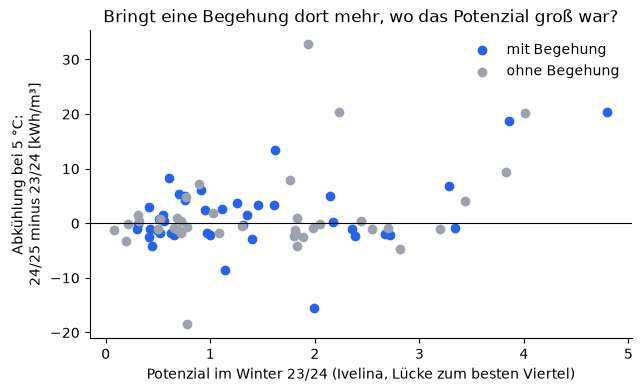

In [41]:
beg = wp[wp["begangen"]]
nicht = wp[~wp["begangen"]]
did = beg["delta_kwh_m3"].median() - nicht["delta_kwh_m3"].median()
p_mw = stats.mannwhitneyu(beg["delta_kwh_m3"], nicht["delta_kwh_m3"], alternative="greater").pvalue
rho, p_rho = stats.spearmanr(beg["potenzial_score"], beg["delta_kwh_m3"], nan_policy="omit")
print(f"Abkühlung bei 5 °C, Winter 24/25 minus 23/24: begangen {beg['delta_kwh_m3'].median():+.2f} kWh/m³ (n = {len(beg)}), "
      f"nicht begangen {nicht['delta_kwh_m3'].median():+.2f} (n = {len(nicht)}); Unterschied {did:+.2f}, p = {p_mw:.3f}")
print(f"Begangene: Potenzial vorher gegen Verbesserung, Spearman rho = {rho:.2f}, p = {p_rho:.3f}")
km = beg.dropna(subset=["kmeans"])
print("Begangene, Verbesserung nach K-Means-Gruppe (Median):", km.groupby("kmeans")["delta_kwh_m3"].median().round(2).to_dict(),
      "| n:", km["kmeans"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(beg["potenzial_score"], beg["delta_kwh_m3"], color=fv.FARBE_IVELINA, label="mit Begehung")
ax.scatter(nicht["potenzial_score"], nicht["delta_kwh_m3"], color="#9CA3AF", label="ohne Begehung")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Potenzial im Winter 23/24 (Ivelina, Lücke zum besten Viertel)")
ax.set_ylabel("Abkühlung bei 5 °C:\n24/25 minus 23/24 [kWh/m³]")
ax.set_title("Bringt eine Begehung dort mehr, wo das Potenzial groß war?")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fv.speichere(fig, "10_potenzial_wirkung")
plt.show()

## Was Test D heißt

- **Zwei Sichten auf dieselbe Frage:** Ivelinas Potenzial und die K-Means-Gruppe passen mittelmäßig
  zusammen (Kappa 0,39).
  - Alle 17 Stationen „schlechter“ haben bei Ivelina mittleres oder hohes Potenzial.
  - Ivelina sieht aber 25 weitere mit Potenzial.
- **Dauerhaft schlechten Betrieb sieht nur der Netzvergleich.** Ein Wächter, der jede Station mit sich
  selbst vergleicht, hält ihn für normal. Beispiel Fall 1: drei Jahre offenes Ventil, Ivelinas
  Netzvergleich setzt die Station vor der Reparatur auf Rang 1.
- **Wirkung der Begehungen:**
  - Begangene Stationen kühlen bei 5 °C im Winter 24/25 um +0,26 kWh/m³ besser als 23/24, nicht
    begangene um 0,56 schlechter.
  - Der Unterschied von 0,82 kWh/m³ ist **nicht gesichert** (p = 0,37).
- **Sagt das Potenzial vorher, wo eine Begehung am meisten bringt?** Kaum: rho = 0,16, p = 0,30.
  K-Means „schlechter“ verbessert sich deutlich mehr (+1,6 gegen −0,3 kWh/m³), das sind aber nur 7
  Stationen.
- **Für das Dashboard:** Netzeffizienz, Rang und Potenzial aus Modell Ivelina **beschreiben**, wo eine
  Station im Netz steht. Sie sind keine Prognose der Einsparung. Euro-Beträge oder Prozent-Einsparungen
  geben diese Daten nicht her.

## 10 · Test E: Reihenfolge der Empfehlungen

**Frage:** Wenn das Team nur 10 Stationen begehen kann, wie viele davon hatten tatsächlich einen
Ventilbefund?

**So prüfen wir:** Die 53 begangenen Stationen werden nach jedem Modell sortiert:
- Ivelinas Priorität (hoch > mittel > niedrig, innerhalb nach Netz-Score),
- p(Ventil) des LSTM-Modells,
- XGBoost,
- die Sommernacht-Regel.

Gezählt werden die Ventilbefunde unter den ersten 10. Zufall ergäbe im Mittel 10 × 11/53 ≈ 2.

In [42]:
rang = fv.oof_breit(KL, "ventil").join(iv[["prioritaet", "netz_score"]])
stufe = rang["prioritaet"].map({"hoch": 2, "mittel": 1, "niedrig": 0}).fillna(-1)
listen = {"Modell Ivelina (Priorität, dann Netz-Score)": stufe * 100 + rang["netz_score"].fillna(-99),
          "Modell LSTM (p Ventil)": rang[fv.ENDMODELL],
          "XGBoost (p Ventil)": rang["XGBoost Kennzahlen + LSTM"],
          "Regel Sommernacht-Anteil": rang["Regel Sommernacht-Anteil"]}
zeilen = []
for name, s in listen.items():
    top = s.sort_values(ascending=False).index[:10]
    zeilen.append({"Reihenfolge nach": name, "Ventilbefunde unter den ersten 10": int(rang.loc[top, "y"].sum())})
print("Ivelinas Priorität unter den 53:", rang["prioritaet"].value_counts().to_dict())
print("davon mit Ventilbefund:", rang.groupby("prioritaet")["y"].sum().to_dict())
pd.DataFrame(zeilen)

Ivelinas Priorität unter den 53: {'niedrig': 31, 'mittel': 21, 'hoch': 1}
davon mit Ventilbefund: {'hoch': 1, 'mittel': 6, 'niedrig': 4}


,Reihenfolge nach,Ventilbefunde unter den ersten 10
0,"Modell Ivelina (Priorität, dann Netz-Score)",5
1,Modell LSTM (p Ventil),7
2,XGBoost (p Ventil),7
3,Regel Sommernacht-Anteil,7


## Was Test E heißt

- Unter den ersten 10 Stationen hatten einen Ventilbefund:
  - Modell LSTM: **8**,
  - XGBoost: 7,
  - Sommernacht-Regel: 7,
  - Ivelinas Priorität: 5,
  - Zufall: etwa 2.
- Ivelinas Stufe „hoch“ bekam vor den Begehungen nur **1** der 53 Stationen (mit Ventilbefund),
  „mittel“ 21, davon 6 mit Ventil. Für eine Reihenfolge ist das zu grob.
- **Daraus folgt:**
  - Die Reparaturliste wird nach dem Ventil-Score des LSTM-Modells sortiert.
  - Ivelinas Fehlerbild „ventil“ ist die Bestätigung und hebt eine Station auf „hoch“.
  - So setzt es `dashboard_daten.empfehlungen` um.
- Die Stufen hoch / mittel / niedrig sind **gesetzt, nicht gelernt**. Ein echter Test wäre prospektiv:
  Stationen der Stufe „hoch“ und gleich viele zufällige begehen, ohne zu wissen, welche welche ist.

## 11 · Neue Stationen, spätere Zeit, Jahreszeiten

| Frage | geprüft wo | Ergebnis |
|---|---|---|
| Bekannte HAST in späterer Zeit | Test A und B (Test ab Juni 2024), Gegenprobe Winter 24/25 (Abschnitt 8) | siehe dort |
| Neue HAST bei der Fehlerart | Test C: Jede Teststation war weder im Encoder noch in der Regression | siehe dort |
| Neue HAST beim Wächter | hier: LSTM ohne ein Fünftel der Stationen lernen | unten |
| Jahreszeiten | Test B Sommer gegen Winter, Fehler je Monat | unten |

In [43]:
neu = fv.lstm_neue_stationen(e, w, log=lambda *a: None)
t = neu["tage"]
print(len(neu["neu"]), "Stationen nie gesehen, gleiche Testtage für alle drei")
mae = t.groupby(["modell", "zaehler"])[["mae_rl", "mae_fluss"]].mean().groupby("modell").agg(["mean", "count"])
mae.round(2)

17 Stationen nie gesehen, gleiche Testtage für alle drei


mae_rl       mae_fluss      
                                  mean count      mean count
modell                                                      
Wochenmittel (ohne Lernen)        4.35    15     54.80    15
bekannt (Station war im Lernen)   3.49    15     46.33    15
neu (Station nie gesehen)         4.02    15     49.00    15

In [44]:
breit = t.groupby(["zaehler", "modell"])["mae_rl"].mean().unstack()
diff = (breit["neu (Station nie gesehen)"] - breit["bekannt (Station war im Lernen)"]).to_numpy()
rng = np.random.default_rng(0)
boot = [diff[rng.integers(0, len(diff), len(diff))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue minus bekannte Station: {diff.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")
diff_wm = (breit["neu (Station nie gesehen)"] - breit["Wochenmittel (ohne Lernen)"]).to_numpy()
boot = [diff_wm[rng.integers(0, len(diff_wm), len(diff_wm))].mean() for _ in range(2000)]
print(f"Rücklauf-Fehler neue Station minus Wochenmittel: {diff_wm.mean():+.2f} K, 95 % [{np.quantile(boot, .025):+.2f}; {np.quantile(boot, .975):+.2f}]")

Rücklauf-Fehler neue minus bekannte Station: +0.54 K, 95 % [+0.20; +1.07]
Rücklauf-Fehler neue Station minus Wochenmittel: -0.32 K, 95 % [-1.00; +0.40]


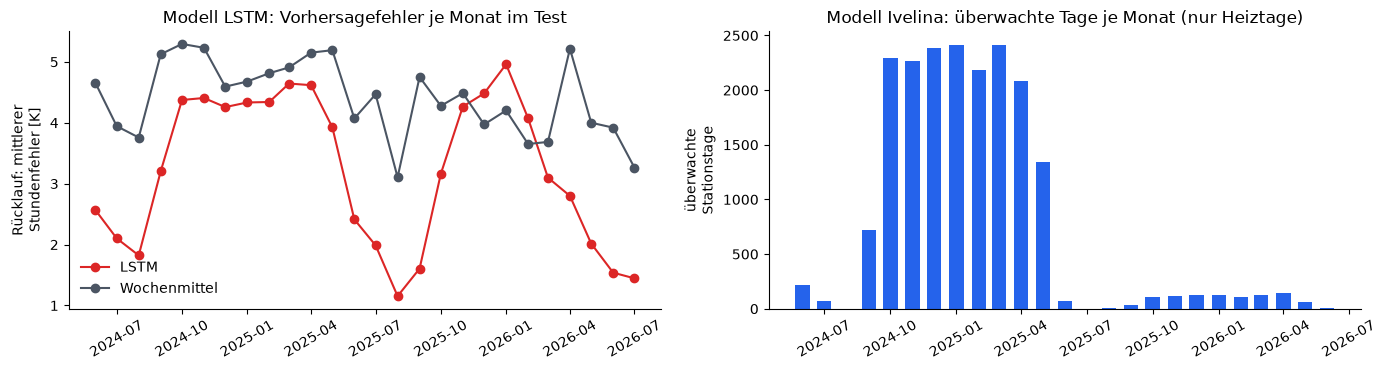

In [45]:
monat = w["abw"][w["abw"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
monat_wm = w["abw_wm"][w["abw_wm"]["tag"] >= fv.TEST_START].assign(monat=lambda d: d["tag"].dt.to_period("M"))
v = w["verlauf"][(w["verlauf"]["datum"] >= fv.TEST_START) & (w["verlauf"]["kanal"] == "kwh_pro_m3")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(monat.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color=fv.FARBE_LSTM, label="LSTM")
ax[0].plot(monat_wm.groupby("monat")["mae_rl"].mean().to_timestamp(), "-o", color="#4B5563", label="Wochenmittel")
ax[0].set_ylabel("Rücklauf: mittlerer\nStundenfehler [K]")
ax[0].set_title("Modell LSTM: Vorhersagefehler je Monat im Test")
ax[0].legend(frameon=False)
mon = v.assign(monat=v["datum"].dt.to_period("M")).groupby("monat")
ax[1].bar(mon.size().index.to_timestamp(), mon.size().values, width=20, color=fv.FARBE_IVELINA)
ax[1].set_ylabel("überwachte\nStationstage")
ax[1].set_title("Modell Ivelina: überwachte Tage je Monat (nur Heiztage)")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
fv.speichere(fig, "11_jahreszeiten")
plt.show()

In [46]:
bewertbar = fv.ab_wann_bewertbar(e, w)
print("Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)")
bewertbar[["Ivelina Tagesmonitor ab Tag", "LSTM-Wächter ab Tag"]].describe().loc[["count", "25%", "50%", "75%"]].round(0)

Ab wann kann jedes Modell eine Station bewerten? (Tage nach dem ersten Messwert, Median über die Stationen)


,Ivelina Tagesmonitor ab Tag,LSTM-Wächter ab Tag
count,93.0,93.0
25%,60.0,27.0
50%,60.0,29.0
75%,87.0,403.0


## Was Abschnitt 11 heißt

- **Spätere Zeit, bekannte Stationen:** Test A und B laufen nur auf Daten nach dem Lernen (ab Juni 2024),
  die Gegenprobe auf dem Winter 24/25. Beide Modelle funktionieren dort.
- **Neue Stationen, Fehlerart:** In Test C war jede Teststation weder im Encoder noch in der Regression.
  Die AUC-Werte gelten also für neue Stationen.
- **Neue Stationen, LSTM-Wächter:** 17 Stationen ohne sie gelernt.
  - Der Rücklauf wird um 0,54 K [0,20; 1,07] schlechter vorhergesagt als mit ihnen.
  - Gegen das Wochenmittel ist das LSTM bei neuen Stationen nicht gesichert besser:
    −0,32 K [−1,00; +0,40].
  - Auch deshalb lernt der Wächter auf allen Stationen, die er überwachen soll.
- **Ab wann bewertbar:**
  - **Ivelinas Wächter** braucht 60 Heiztage mit 8 K Temperaturspanne. Beginnt eine Station im Winter,
    sind das im Median 60 Tage, sonst wartet sie bis zur nächsten Heizperiode. Er rechnet aus
    Zählerständen und nutzt deshalb auch Tageswerte.
  - **Das LSTM** braucht rund 4 Wochen volle Stundenwerte (7 Vortage, 10 Tage für die Skala, 10 Tage
    Kalibrierung), im Median 29 Tage, in jeder Jahreszeit. Stationen, die anfangs nur Tageswerte
    lieferten, kann es erst ab den Stundenwerten bewerten.
- **Jahreszeiten:**
  - Das LSTM sagt im Sommer viel genauer voraus (1 bis 2,5 K) als im Winter (4 bis 5 K). Das Wochenmittel
    liegt das ganze Jahr bei 4 bis 5 K.
  - Ivelinas Wächter überwacht nur Oktober bis April.
  - Die beiden ergänzen sich also über das Jahr.
- **7 Stationen** kann Ivelinas Wächter mit der gemeinsamen Lernzeit nicht einlernen, weil sie zu spät
  Daten liefern. 6 davon hat auch das LSTM nicht kalibriert. Das Dashboard muss „noch nicht bewertbar“
  zeigen, nicht „kein Alarm“.

## 12 · Fallbeispiele mit echten Daten

Je Fall zeigen vier Bilder:
1. Ivelinas Abkühlung (gemessen gegen Kennlinie),
2. ihr CUSUM-Konto mit der Grenze h = 5,
3. Rücklauf gemessen gegen LSTM-Erwartung,
4. die z-Werte des LSTM.

Senkrechte Linien sind Alarme (durchgezogen = schlechter, gepunktet = besser), grün sind Begehungen.
Die Fälle sind nach festen Regeln gewählt, nicht nach schönen Bildern.

{'ventil': True, 'daemmung': False, 'durchfluss': False, 'temperatur': True, 'filter': False, 'ueberdimensioniert': nan} | Begehung: ['09.09.2024']


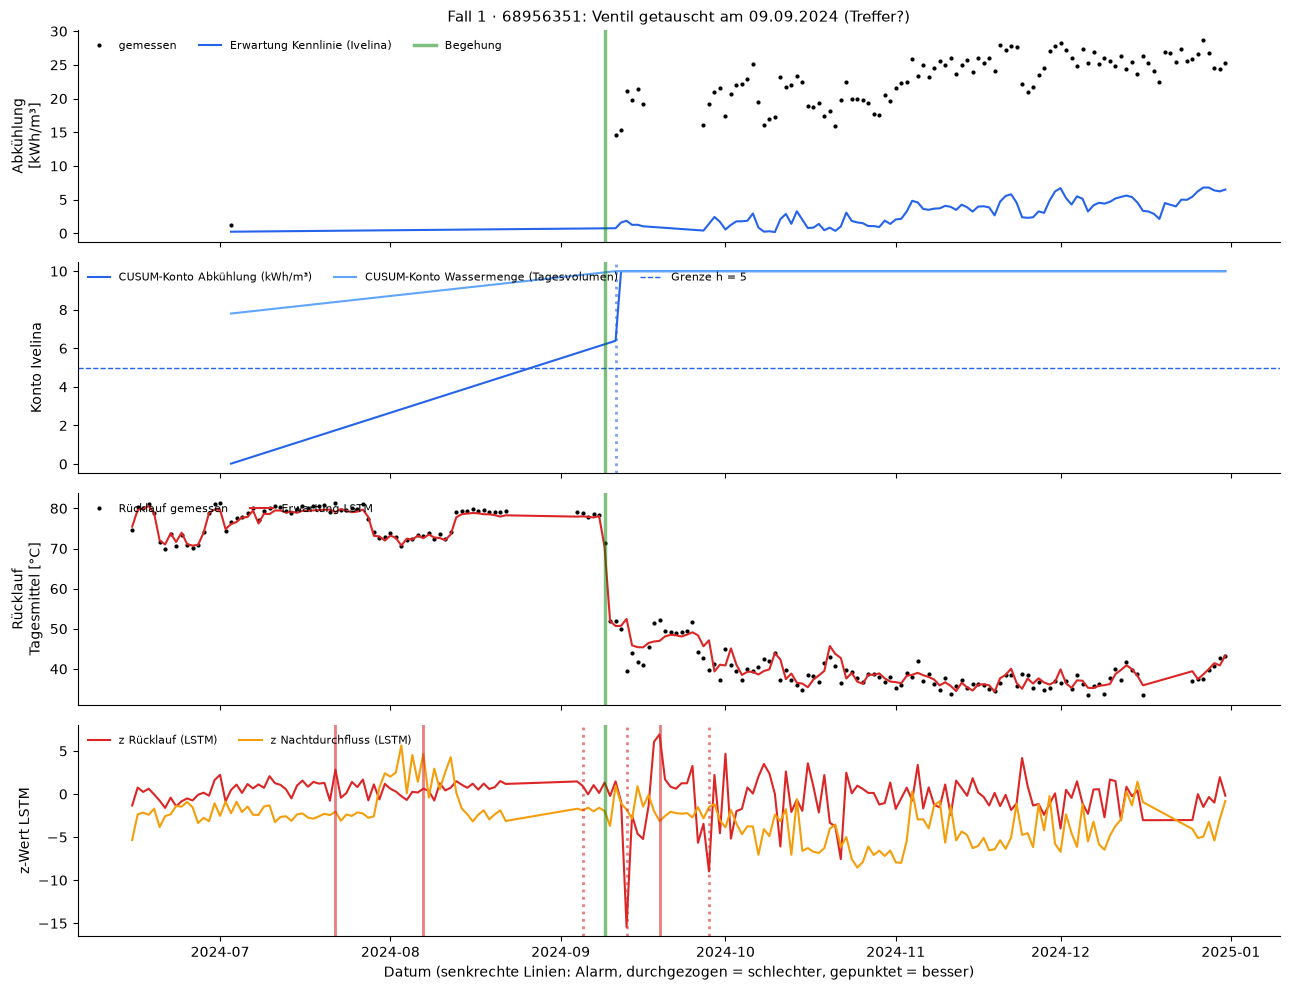

In [47]:
fall1 = 68956351
print(e["labels"].loc[fall1, fv.ZIELE].to_dict(), "| Begehung:", [f"{t:%d.%m.%Y}" for t in termine.get(fall1, [])])
fig = fv.fallbild(fall1, w, e, "2024-06-15", "2024-12-31", f"Fall 1 · {fall1}: Ventil getauscht am 09.09.2024 (Treffer?)")
fv.speichere(fig, "12_fall1")
plt.show()

Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = 0.10), Fehlerbild Ivelina: „durchfluss_je_kw“
Kennzahlen: {'sommer_durchlauf_anteil': 0.93, 'sommer_nachtfluss_lph': 46.0, 'winter_spreizung_last_k': 28.62, 'ruecklauf_lastgewichtet': 47.17}


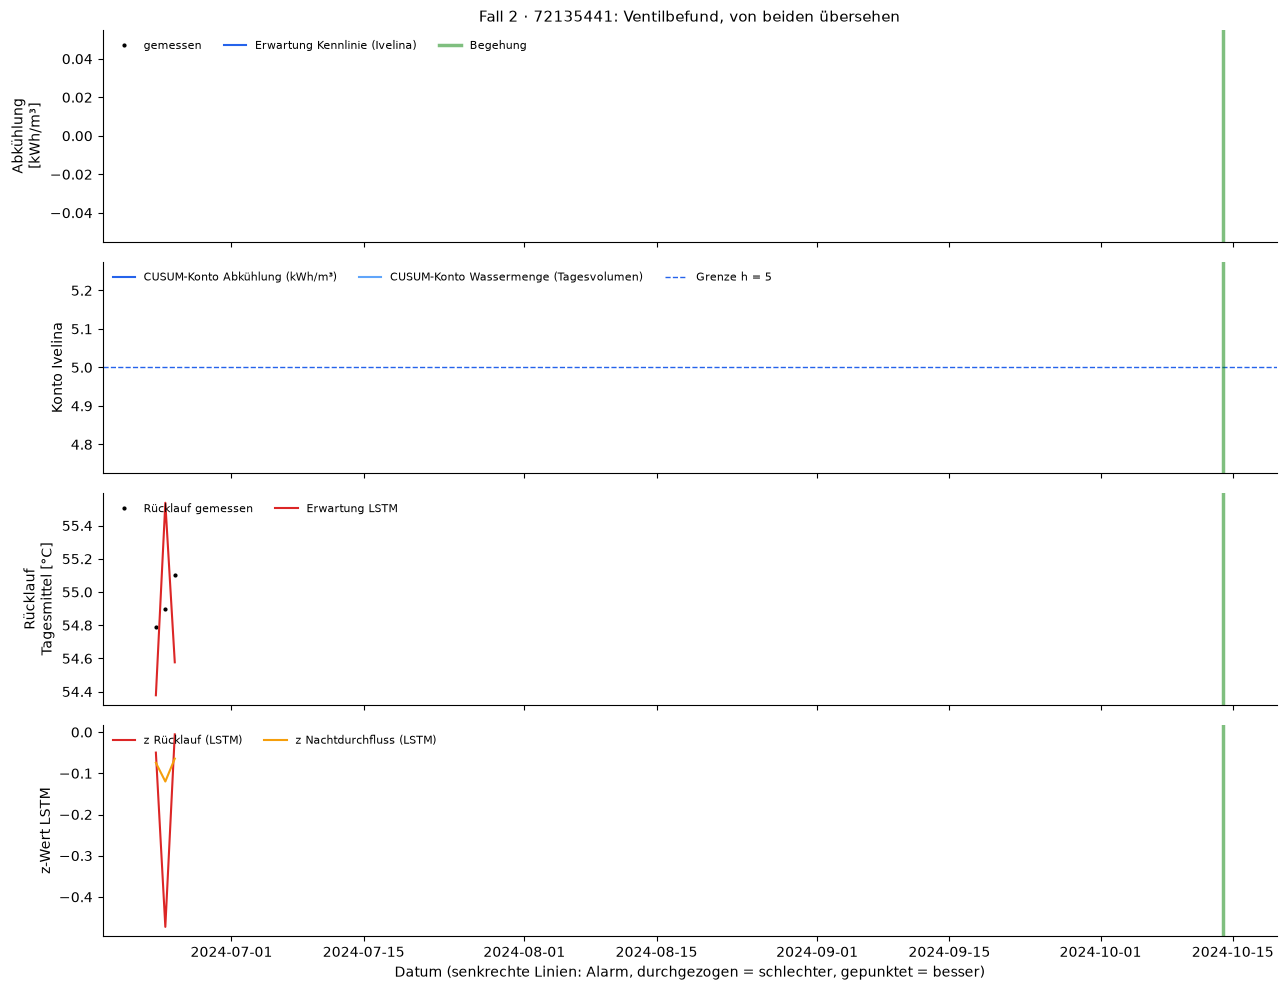

In [48]:
bv2 = fv.oof_breit(KL, "ventil").join(iv[["fehlerbild"]])
uebersehen = bv2[(bv2["y"] == 1) & ~bv2["fehlerbild"].eq("ventil")].sort_values(fv.ENDMODELL)
fall2 = int(uebersehen.index[0])
print(f"Fall 2: Ventilbefund mit dem kleinsten Verdacht des LSTM-Modells (p = {uebersehen.iloc[0][fv.ENDMODELL]:.2f}), "
      f"Fehlerbild Ivelina: „{uebersehen.iloc[0]['fehlerbild'] or 'keins'}“")
print("Kennzahlen:", KL["kz"].loc[fall2, ["sommer_durchlauf_anteil", "sommer_nachtfluss_lph", "winter_spreizung_last_k", "ruecklauf_lastgewichtet"]].round(2).to_dict())
d2 = min(termine.get(fall2, [pd.Timestamp("2024-10-01")]))
fig = fv.fallbild(fall2, w, e, d2 - pd.Timedelta(days=120), d2 + pd.Timedelta(days=90), f"Fall 2 · {fall2}: Ventilbefund, von beiden übersehen")
fv.speichere(fig, "12_fall2")
plt.show()

Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen bei Ivelina im Test: 72135453


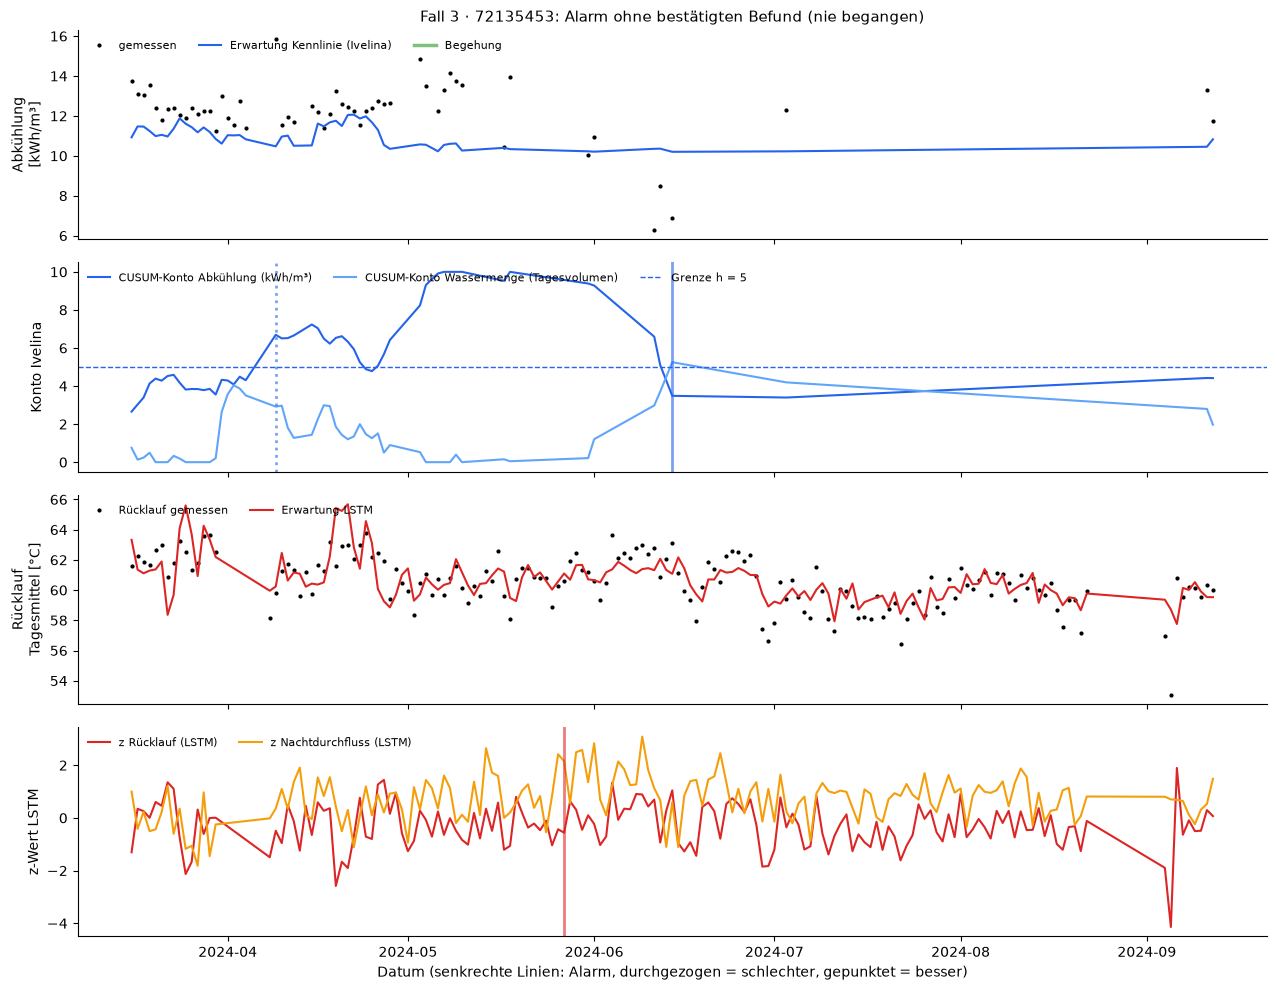

In [49]:
nie = [m for m in w["kal"].index if m not in e["labels"].index and m in set(w["ref"].index[w["ref"]["status"] == "ok"])]
al_iv_t = w["alarme"]["ivelina"]
al_iv_t = al_iv_t[(al_iv_t["datum"] >= fv.TEST_START) & al_iv_t["zaehler"].isin(nie) & (al_iv_t["bewertung"] == "schlechter")]
fall3 = int(al_iv_t["zaehler"].value_counts().index[0])
d3 = al_iv_t[al_iv_t["zaehler"] == fall3]["datum"].min()
print(f"Fall 3: nie begangene Station mit den meisten Verschlechterungsalarmen bei Ivelina im Test: {fall3}")
fig = fv.fallbild(fall3, w, e, d3 - pd.Timedelta(days=90), d3 + pd.Timedelta(days=90), f"Fall 3 · {fall3}: Alarm ohne bestätigten Befund (nie begangen)")
fv.speichere(fig, "12_fall3")
plt.show()

In [50]:
nicht_ok = w["ref"][w["ref"]["status"] != "ok"]
print("Fall 4: Stationen, die Ivelinas Wächter mit der gemeinsamen Lernzeit nicht einlernen kann:")
display(nicht_ok[["ref_tage", "ref_spanne_k", "status"]].assign(LSTM_kalibriert=lambda d: d.index.isin(w["kal"].index)))
print("Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.")

Fall 4: Stationen, die Ivelinas Wächter mit der gemeinsamen Lernzeit nicht einlernen kann:


,ref_tage,ref_spanne_k,status,LSTM_kalibriert
meter,,,,
58177384,460,24.258333,keine Tage nach der Referenz,False
80912191,0,0.000000,zu wenige Referenztage,False
80912194,0,0.000000,zu wenige Referenztage,False
80912199,3,6.258333,zu wenige Referenztage,False
81019433,0,0.000000,zu wenige Referenztage,False
81050517,0,0.000000,zu wenige Referenztage,False
81062289,0,0.000000,zu wenige Referenztage,False


Gründe: zu wenige Heiztage vor dem Lernende, meist weil die Station erst spät Daten liefert.


## Was die Fälle zeigen

- **Fall 1 (68956351, Ventil getauscht am 09.09.2024): Treffer für beide.**
  - Am Tag der Reparatur fällt der Rücklauf von etwa 78 auf 50 °C, die Abkühlung steigt von etwa 1 auf
    über 20 kWh/m³.
  - Ivelinas Wächter meldet zwei Tage später „besser“, das LSTM ebenfalls im September.
  - Vorher meldete das LSTM im Juli und August zweimal „schlechter“.
  - Ivelinas Kennlinie stammt aus der Zeit mit offenem Ventil (Abkühlung nahe 1 kWh/m³). Danach stehen
    ihre Konten am Deckel. Ohne neue Referenz kann ihr Wächter diese Station nicht weiter überwachen.
  - Das LSTM hat sich nach etwa einer Woche angepasst.
  - Vor der Reparatur hatten alle diese Station vorn: Ivelinas Netzvergleich auf Rang 1 mit Fehlerbild
    „ventil“, Ventil-Score des LSTM-Modells 0,80, Sommernacht-Anteil 100 %.
- **Fall 2 (80912189, Ventilbefund): von beiden übersehen.**
  - Die Daten zeigen kein offenes Ventil: 13 % der Sommernächte mit Durchfluss, große Spreizung (34 K),
    Ventil-Score 0,27.
  - Vermutung: Ein anderer Ventilfehler (klemmt, öffnet schlecht), oder der Befund betraf ein anderes
    Ventil.
  - Was die Daten nicht zeigen, kann kein Modell finden.
  - Zusätzlich steht Ivelinas Konto seit der Referenzzeit am Deckel. Der Wächter ist hier stumm.
- **Fall 3 (72135453, nie begangen): Alarm ohne bestätigten Befund.**
  - Ivelinas Wächter meldet im Juni 2024 „schlechter“. Im Übergang zum Sommer gibt es nur wenige
    Heiztage, und an ihnen fällt die Abkühlung auf 6 bis 8 kWh/m³.
  - Das LSTM bleibt bis auf einen Tag ruhig.
  - Ob ein Fehler vorlag, ist unbekannt. Deutung: eher Übergangszeit als Defekt.
  - Deshalb heißt ein Alarm im Dashboard „Veränderung“, nicht „Fehler“.
- **Fall 4: 7 Stationen ohne Referenz.** Sie liefern zu spät Daten, die meisten sind auch für das LSTM
  nicht kalibriert. Ehrlich ist „noch nicht bewertbar“.

## 13 · Entscheidung und Dashboard-Bauplan

### Entscheidung je Aufgabe

| Aufgabe (Abschnitt 1) | Modell im Dashboard | wann es gilt | Urteil | Beleg |
|---|---|---|---|---|
| Stationsleistung, Netzeffizienz, dauerhaft schlechter Betrieb | **Modell Ivelina**: Netzvergleich je Kernwinter (Rang, schlechte Kennzahlen, Fehlerbild), Potenzial | ab dem ersten vollständigen Kernwinter einer Station | Pilot (beschreibend, keine Prognose der Einsparung) | Test D, Fall 1 |
| Veränderung erkennen in der Heizperiode, Erfolgskontrolle | **Modell Ivelina**: Tagesmonitor, CUSUM h = 5; Prognose-LSTM als Hinweis für plötzliche Sprünge (Abschnitt 15) | an Heiztagen (Tagesmittel unter 15 °C), ab 60 Heiztagen Referenz | Pilot mit Einschränkungen: Referenz muss erneuert werden | Test A, B, 7b, Fall 1, 2 |
| Veränderung erkennen an warmen Tagen, plötzlicher Durchfluss | **Modell LSTM**: Prognose-LSTM auf allen Stationen, CUSUM h = 10 | ganzjährig; Hauptkanal an warmen Tagen; ab etwa 4 Wochen Stundenwerten | Pilot mit Einschränkungen: an echten Begehungen nicht belegt | Test B, 7c |
| Fehlerart Ventil (Reparatur) | **Modell LSTM**: Ventil-Score (nur auf begangenen Stationen gelernt); Sommernacht-Anteil als Erklärung; Ivelinas Fehlerbild „ventil“ hebt auf „hoch“ | nach einem Winter und einem Sommer mit Stundenwerten | Pilot: Score ist eine Rangfolge, keine geprüfte Wahrscheinlichkeit | Test C, E, Gegenprobe |
| Dämmung | Modell LSTM: Hinweis; Muster aus mehreren Kennzahlen, das keine einzelne Regel findet | wie oben | weitere Validierung nötig | Test C, Abschnitt 15 |
| Kapazitätsanpassung | Regel Spitzenlast zum alten Vertrag | wenn der Vertrag vor der Maßnahme bekannt ist | Pilot mit Einschränkungen (9 Fälle) | Test C |
| Regelungsoptimierung (Folie 5 „mittel“) | **nicht im Dashboard**: K-Means trifft sie nicht | – | als Fehlerart ungeeignet | Test C (Folie 5) |
| Durchfluss einstellen, Sollwert, Filter, Regelhysterese | als **Symptom** zeigen (z. B. Fehlerbild „unruhig“), nicht als Ursache | – | als Ursache nicht erkennbar | Test B, C |
| Empfehlung und Reihenfolge | `dashboard_daten.empfehlungen`: hoch = Reparatur mit Ivelinas Fehlerbild „ventil“, mittel = Reparatur nach Ventil-Score, niedrig = Kapazität, Dämmung (Hinweis), Daten prüfen; innerhalb der Stufe nach Ventil-Score | – | Pilot; Stufen gesetzt, nicht gelernt | Test E |
| echte Frühwarnung | – | – | nicht prüfbar | Abschnitt 1 |
| XGBoost, LSTM mit fester Referenz, Sommer-LSTM | – | – | geprüft, kein Mehrwert gegenüber dem Einfacheren | Test C, 7b, 7c |

**Regel für „nur begangene Stationen“:** Wo mit Befunden gelernt wird (Fehlerart), lernen die Modelle nur
auf begangenen Stationen, wie vorgegeben. Wo ohne Befunde das Normalverhalten gelernt wird (Wächter),
lernt das Modell auf allen Stationen, die es überwachen soll. Die jeweils andere Fassung ist geprüft und
als Paket gespeichert.

**In einem Satz je Aufgabe:**
- Für Veränderungen in der Heizperiode empfehlen wir **Modell Ivelina**, weil ihr Wächter echte
  Maßnahmen am deutlichsten bemerkt und im Winter eingebaute Fehler am besten findet. Ein gleich gebautes
  LSTM ist nicht besser.
- Für warme Tage empfehlen wir **Modell LSTM**, weil dort nur es rechnet und es das Wochenmittel bei
  wenigen Fehlalarmen klar schlägt.
- Für die Fehlerart Ventil empfehlen wir das **Modell LSTM mit Ivelinas Fehlerbild als Bestätigung**.
  Dass das LSTM besser ist als die einfache Sommernacht-Regel, ist nicht belegt; dafür fehlen mehr
  Ventilfälle.
- Für Regelungsoptimierung und Frühwarnung reicht die Evidenz nicht. Es fehlen Befunde mit klarer
  Fehlerart und bekanntem Fehlerbeginn. Symptome zeigt das Dashboard trotzdem, getrennt von Ursachen.

### Umsetzung nach Aufgabenstellung

So wird jeder Punkt der Aufgabenstellung im Dashboard (Notebook 35) umgesetzt, und nur mit dem, was oben geprüft ist:

| Aufgabe | Umsetzung im Dashboard | Modell | Was bewusst fehlt, und warum |
|---|---|---|---|
| **Datenanalyse:** Stationsleistung, Anomalien wie überhöhter Rücklauf, Dauerdurchfluss, Regelhysterese | Seitenleiste „Netz“, Färbung „Potenzial“ und „Meldungen“, Hausfenster „Leistung im Netz“ und „Veränderung“ | Ivelina: Netzvergleich und Tagesmonitor; LSTM: Prognose an warmen Tagen | Regelhysterese: findet kein Wächter (Test B, höchstens 15 %) |
| **Modellentwicklung:** Anomalien erkennen, Fehlerarten klassifizieren | Meldungen je Tag aus genau einem Wächter; Verdacht auf Ventil, Dämmung, Anschluss zu groß | Tagesmonitor an Heiztagen, sonst Prognose-LSTM; LSTM-Fehlerklassen; Regel Spitzenlast | Regelung, Filter, Sollwert, Durchfluss als Ursache: nicht erkennbar (Test C) |
| **Visualisierung:** Netzeffizienz, Stationsleistung, Optimierungspotenzial | Karte auf dem Rohrbaum aus Notebook 28 mit Zeitregler, immer nur eine Färbung; Reiter „So funktioniert's“ | Messwerte; Ivelinas Netzvergleich und bestes Viertel | Einspar-Schätzung für das Netz: Wirkung der Begehungen nicht gesichert (Test D) |
| **Empfehlungssystem:** priorisierte Empfehlungen Regelungsoptimierung, Reparatur, Kapazitätsanpassung | Reiter „Handlungsliste“: hoch = Reparatur mit Ivelinas Fehlerbild, mittel = Reparatur nach Ventil-Score, niedrig = Kapazität, Dämmung (Hinweis), Daten prüfen; innerhalb nach Ventil-Score | LSTM-Fehlerklassen, Ivelinas Fehlerbild, Regel Spitzenlast | Regelungsoptimierung: K-Means trifft sie nicht (Test C). Sortieren nach Alarmen oder Potenzial: sagt Befunde nicht vorher (Test D, E). Reparatur bei Sonderfällen: dort ist kein Score geprüft |

Code: `src/dashboard_daten.py` (Pakete anwenden, Empfehlung), `src/dashboard_karte.py` (für die Karte aufbereiten),
`notebooks/dashboard_final.py` (Karte, Handlungsliste, Erklärung).

### Dashboard-Bauplan: welches Feld woher kommt

Das Dashboard (Notebook 35, `notebooks/dashboard_final.py`) rechnet nichts selbst. `python -m src.dashboard_daten` wendet
die drei Pakete an und schreibt die Tabellen nach `outputs/dashboard/`.

| Feld im Dashboard | Quelle | Paket / Funktion | Spalte |
|---|---|---|---|
| Netzeffizienz je Monat | Messwerte | `dashboard_daten.netzeffizienz` | `netzeffizienz.parquet` |
| Karte auf dem Rohrbaum mit Zeitregler | Notebook 28, beide Wächter | `notebooks/dashboard_final.py`, `src/dashboard_karte.py` | `alarme.parquet`, `stationen.parquet` |
| Rang im Netz, Fehlerbild, Potenzial | Modell Ivelina | `stationsblatt.rechne` (Netzvergleich) | `netz_rang`, `netz_fehlerbild`, `potenzial` |
| Alarm Heizperiode (Richtung schlechter/besser) | Modell Ivelina | Paket `normalmodell` (Notebook 34) | `alarme.parquet` (Quelle Tagesmonitor), `tm_verschlechterung` |
| Referenz veraltet (Konto am Deckel) | Modell Ivelina | `dashboard_daten.rechne` | `tm_deckel_anteil` |
| Alarm warme Tage | Modell LSTM | Paket `prognose_lstm` (Notebook 34, alle Stationen, CUSUM h = 10) | `alarme.parquet` (Quelle Prognose-LSTM), `lstm_alarme_aktuell` |
| bewertbar oder nicht, mit Grund | beide | Status aus beiden Paketen | `tm_status`, `lstm_status` |
| Ventil-Score, Klasse, Hinweise Dämmung/Vertrag | Modell LSTM | Paket `fehlerklassen` (Notebook 34, nur begangene Stationen) | `p_ventil`, `klasse`, `hinweis_daemmung`, `hinweis_vertrag` |
| beobachtetes Symptom | Netzvergleich, Sommernächte | `dashboard_daten.wissensstand` | `symptom` |
| erkannte Veränderung | beide Wächter | `wissensstand` | `veraenderung` |
| vermutete Ursache | Modell LSTM, Regel | `wissensstand` | `vermutete_ursache` |
| dokumentierter Befund | Begehungsprotokoll | `wissensstand` | `befund` |
| empfohlene Prüfung, Dringlichkeit, Rang | Regeln | `dashboard_daten.empfehlungen` | `handlung`, `dringlichkeit`, `rang` |
| Modellversion | Pakete | `meta.json` | `pakete` |

**Regeln für die Anzeige:**
- „Keine Meldung“ heißt nie „in Ordnung“.
- Ein Score ist keine Wahrscheinlichkeit.
- Symptom, Vermutung und dokumentierter Befund stehen getrennt.
- Fehlt eine Voraussetzung, steht „nicht bewertbar“ mit Grund da.

### Grenzen

- **Wenige Fälle:**
  - 43 Begehungen im Test, 11 Ventil- und 9 Vertragsfälle.
  - Unterschiede unter etwa 0,1 AUC oder 5 Fällen sind nicht sichtbar.
  - „Nicht gesichert“ heißt: Die Daten reichen nicht, nicht „kein Unterschied“.
- **Viele Gegenproben:** sieben Wächter, drei Richtungen, zwei Vergleichsgruppen. Einzelne kleine p-Werte
  können Zufall sein. Entscheidend ist, dass das Bild über Test A, Test B und die Kurven gleich bleibt.
- **Labels:** Laut Team und Projektpartner war, was im Protokoll steht, der Fehler, und was nicht drinsteht,
  war es nicht. Das gilt nur für die begangenen Stationen.
  - Der Beginn eines Fehlers ist unbekannt.
  - 37 nie begangene Stationen sind unbekannt, nicht gesund.
- **Feste Referenz bei Ivelina:** An 43 % der Testtage steht ein Konto am Deckel, bei 31 von 81 Stationen
  mehr als die Hälfte der Zeit. Dort meldet der Wächter nichts Neues.
- **Eingebaute Fehler** zeigen, was ein Wächter grundsätzlich kann, nicht seine Trefferquote bei echten
  Fehlern.
- **Probezeit klein:** Die Alarmlast ist auf 2.184 gemeinsamen Stationstagen im April und Mai 2024
  eingestellt. Im Test liegen die Arbeitslasten deshalb zwischen 2,7 und 6,4 Alarmen je Station und Jahr.
  Die Kurven zeigen, dass die Rangfolge davon kaum abhängt.

### Warum andere Zahlen als in Notebook 32 und 33

| | Notebook 32 | Audit / Notebook 33 | hier (Notebook 34) |
|---|---|---|---|
| Schwellen | auf den Testfällen gleich viele Alarme | Probezeit, Ziel 2 Alarme je Jahr | Probezeit April/Mai, Bezug Ivelinas h = 5 |
| Referenz Ivelina | eigene Regel (endet kurz vor der Begehung) | Kennlinie bis 31.01.2024, ohne Streuungsvergrößerung | Kennlinie bis 31.01.2024, mit ihrer Streuungsregel |
| LSTM-Encoder | sah die Teststationen | je Fold neu, begangene Lernstationen | je Fold neu, nur begangene Lernstationen; Gegenprobe alle |
| Merkmal Auslastung | dabei | entfernt | entfernt |
| Begehungen | alle Alarme zusammen: Ivelina 33/43 | Heiztage, 27 Begehungen, je 6 mit Alarm vorher und nachher | getrennt nach Richtung, Ivelina 18/43 (besser) |

### Kleinster nächster Schritt

1. **Referenz erneuern:** Ivelinas Kennlinie nach jeder Begehung und zu Beginn jeder Heizperiode neu
   lernen (letzte 12 Monate ohne Begehung). Danach Test A und B mit dieser Regel wiederholen.
2. **Ventil prospektiv prüfen:** Die nie begangenen Stationen mit hohem Ventil-Score und Ivelinas
   Fehlerbild „ventil“ gezielt begehen und das Ergebnis eintragen.
3. **Ursachen statt Symptome:** Eine mit der ÜZ abgestimmte Fehler-Symptom-Matrix (Notebook 31) und je
   Befund der geschätzte Beginn. Erst damit lassen sich Regelung, Hysterese und Frühwarnung prüfen.

### Selbstprüfung

| Prüfpunkt | Stand |
|---|---|
| Notebooks beider Modelle zugeordnet | ja, Tabelle oben; vollständiges Inventar in `docs/model_audit/02_inventar_und_pipelines.md` |
| Beide Modelle aus Notebook 00 | ja, Prüfzelle in Abschnitt 3 |
| Labels bis zur Quelle | ja (Notebook 18, Protokoll, Teamangabe); Beginn eines Fehlers ungeklärt |
| Stationen und Fenster getrennt gezählt | ja, Unsicherheit über Stationen |
| Nur vergleichbare Aufgaben verglichen | ja, Alarm, Fehlerart, Effizienz, Reihenfolge getrennt |
| Fairness der Bauweise geprüft | ja, LSTM mit fester Referenz (7b), Sommer-LSTM (7c), nur begangene Stationen |
| Testdaten aus Lernen und Einstellen heraus | ja, Zeitachse und Folds geprüft (`assert`) |
| Generalisierung geprüft oder nur vermutet | geprüft: spätere Zeit, neue Stationen; Jahreszeiten getrennt |
| Gespeichert, nachgerechnet, geplant getrennt | ja; „wie gebaut“-Fassungen als Gegenprobe gekennzeichnet |
| Grenzen in der Empfehlung | ja, Urteil je Aufgabe |

## 14 · Modelle speichern und Dashboard umstellen

Gespeichert wird **genau das, was oben geprüft wurde**, im Format, das `src/dashboard_daten.py` schon
liest. Jedes Paket enthält die Gewichte oder Kennlinien, die Skalierung, die Kalibrierung, die Schwelle,
den Lernzeitraum, den Code-Stand und Prüfsummen. Die alten Versionen bleiben liegen, zurück geht es mit
`mp.setze_aktuell(name, version)`. `models/` ist gitignored, es wird nichts committet.

In [51]:
from datetime import datetime
VERSION = "nb34_" + datetime.now().strftime("%Y-%m-%d_%H%M%S")
regel_lstm, wert_lstm = w["einstellung"]["lstm_c"]
datenstand = e["stunden"]["timestamp"].max()
pk_normal = fv.paket_normalmodell(w["ref"], w["mod"], w["modtab"], VERSION,
    kennzahlen={"stationen": int(len(w["ref"])), "ueberwacht": int((w["ref"]["status"] == "ok").sum()),
                "testA_besser": f"{int(A_besser.iloc[0]['bemerkt'])}/{int(A_besser.iloc[0]['Fälle'])}"},
    lernzeitraum=f"Heiztage bis {fv.LERN_ENDE - pd.Timedelta(days=1):%d.%m.%Y} (spätestens 14 Tage vor der ersten Begehung)",
    datenstand=fv.LERN_ENDE)
pk_lstm = fv.paket_prognose(w["lstm"], w["kal"], w["faktor"], regel_lstm, w["einstellung"]["lstm_s"][1], wert_lstm, VERSION,
    kennzahlen={"lern_ziele": w["lstm"]["lern_ziele"], "kalibrierte_stationen": int(len(w["kal"]))},
    datenstand=fv.VAL_ENDE)
pk_fk = fv.paket_fehlerklassen(teile["netz"], teile["skalierung"], teile["ventil_modell"], teile["daemmung_modell"],
    teile["kmeans"], teile["lernbereich"], teile["kreuzvalidierung"], teile["parameter"], VERSION,
    kennzahlen={"ventil_auc_oof": round(float(tab_ventil.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "daemmung_auc_oof": round(float(tab_daemmung.set_index("Kandidat").loc[fv.ENDMODELL, "AUC"]), 3),
                "lernstationen": int(len(KL["basis"]))},
    datenstand=fv.STICHTAG)
#die jeweils andere Fassung als Paket zum Umschalten, nicht aktiv
VERSION_ALT = VERSION.replace("nb34_", "nb34gegenprobe_")
regel_b, wert_b = w["einstellung"]["lstm_beg"]
pk_lstm_beg = fv.paket_prognose(w["beg"]["lstm"], w["beg"]["kal"], w["beg"]["faktor"], regel_b, w["einstellung"]["lstm_s"][1], wert_b,
    VERSION_ALT, kennzahlen={"fassung": "nur begangene Stationen gelernt", "lern_ziele": w["beg"]["lstm"]["lern_ziele"]},
    datenstand=fv.VAL_ENDE)
teile_alle = fv.fehlerklassen_teile(KL_alle)
pk_fk_alle = fv.paket_fehlerklassen(teile_alle["netz"], teile_alle["skalierung"], teile_alle["ventil_modell"],
    teile_alle["daemmung_modell"], teile_alle["kmeans"], teile_alle["lernbereich"], teile_alle["kreuzvalidierung"],
    teile_alle["parameter"], VERSION_ALT, kennzahlen={"fassung": "Encoder auf allen Stationen gelernt"}, datenstand=fv.STICHTAG)
for p in (pk_normal, pk_lstm, pk_fk, pk_lstm_beg, pk_fk_alle):
    print(f"{p.name:15s} {p.version:38s} {len(p.meta['dateien'])} Dateien  ->  {p.ordner.relative_to(ROOT)}")

normalmodell    nb34_2026-10-27_121626                 3 Dateien  ->  models/normalmodell/nb34_2026-10-27_121626
prognose_lstm   nb34_2026-10-27_121626                 6 Dateien  ->  models/prognose_lstm/nb34_2026-10-27_121626
fehlerklassen   nb34_2026-10-27_121626                 8 Dateien  ->  models/fehlerklassen/nb34_2026-10-27_121626
prognose_lstm   nb34gegenprobe_2026-10-27_121626       6 Dateien  ->  models/prognose_lstm/nb34gegenprobe_2026-10-27_121626
fehlerklassen   nb34gegenprobe_2026-10-27_121626       8 Dateien  ->  models/fehlerklassen/nb34gegenprobe_2026-10-27_121626


**Gegenprobe:** Die geladenen Pakete liefern dieselben Werte wie oben im Speicher.

In [52]:
from src import normalmodell_waechter as nw
g_lstm = pw.lade(VERSION)
pr = pw.anwenden(g_lstm, e["stunden"], ab=fv.VAL_START)
m = pr.merge(w["z"], on=["zaehler", "tag"], suffixes=("_paket", "_nb"))
print("LSTM-Paket: max. Unterschied z Rücklauf", float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()))
g_norm = nw.lade(VERSION)
nm = nw.anwenden(g_norm, e["serien"], e["temp"])
print("Normalmodell-Paket: Alarme", len(nm["alarme"]), "gegen", len(fv.ivelina_alarme(w["verlauf"])), "im Notebook")
g_fk = fk.lade(VERSION)
bew = fk.bewerten(g_fk, KL["kz"], KL["final"]["embedding"], oof=g_fk["kreuzvalidierung"])
print("Fehlerklassen-Paket: Klassen", bew["klasse"].value_counts().to_dict())
assert float((m["z_rl_paket"] - m["z_rl_nb"]).abs().max()) < 1e-3
assert len(nm["alarme"]) == len(fv.ivelina_alarme(w["verlauf"]))

LSTM-Paket: max. Unterschied z Rücklauf 1.5172671208318889e-06


Normalmodell-Paket: Alarme 313 gegen 313 im Notebook
Fehlerklassen-Paket: Klassen {'kein Handlungsbedarf': 61, 'Regelventil tauschen': 25, 'Regelparameter optimieren': 4, 'nicht einstufbar': 1}


**Betriebsversion festlegen.** Nach der Entscheidung in Abschnitt 13 werden die drei Hauptpakete zur
Betriebsversion:
- `normalmodell`: Ivelinas Wächter,
- `prognose_lstm`: auf allen Stationen gelernt,
- `fehlerklassen`: nur auf begangenen Stationen gelernt.

Die Gegenproben (`nb34gegenprobe_…`) liegen daneben. Umschalten geht mit
`mp.setze_aktuell("prognose_lstm", VERSION_ALT)`. Das Dashboard (`python -m src.dashboard_daten`) rechnet
danach mit der aktiven Version.

In [53]:
UMSTELLEN = True
vorher = {n: mp.aktuelle_version(n) for n in ("normalmodell", "prognose_lstm", "fehlerklassen")}
if UMSTELLEN:
    for n in vorher:
        mp.setze_aktuell(n, VERSION)
print("Gegenproben zum Umschalten:", VERSION_ALT, "(prognose_lstm: nur begangene, fehlerklassen: alle Stationen)")
pd.DataFrame({"vorher": vorher, "jetzt": {n: mp.aktuelle_version(n) for n in vorher}})

Gegenproben zum Umschalten: nb34gegenprobe_2026-10-27_121626 (prognose_lstm: nur begangene, fehlerklassen: alle Stationen)


,vorher,jetzt
normalmodell,nb34_2026-10-25_121559,nb34_2026-10-27_121626
prognose_lstm,nb34_2026-10-25_121559,nb34_2026-10-27_121626
fehlerklassen,nb34_2026-10-25_121559,nb34_2026-10-27_121626


In [54]:
aus = fv.AUSGABE
aus.mkdir(parents=True, exist_ok=True)
A.to_csv(aus / "testA_begehungen.csv", index=False)
KA.to_csv(aus / "testA_kurve.csv", index=False)
SA.to_csv(aus / "testB_faelle.csv", index=False)
SK.to_csv(aus / "testB_kurve.csv", index=False)
KL["oof"].to_csv(aus / "testC_vorhersagen.csv", index=False)
pd.concat([tab_ventil.assign(Ziel="ventil"), tab_daemmung.assign(Ziel="daemmung"), tab_ueber.assign(Ziel="ueberdimensioniert")]).to_csv(
    aus / "testC_kennzahlen.csv", index=False)
stab.to_csv(aus / "testC_stabilitaet.csv", index=False)
vergleich_beg.to_csv(aus / "testC_nur_begangene_gegen_alle.csv", index=False)
vergleich_nv.to_csv(aus / "test_nv_lstm_feste_referenz.csv")
som["kurve"].to_csv(aus / "test_sommer_lstm.csv", index=False)
gp.to_csv(aus / "testC_gegenprobe.csv")
wp.to_csv(aus / "testD_potenzial.csv")
last.to_csv(aus / "arbeitslast.csv", index=False)
bewertbar.to_csv(aus / "ab_wann_bewertbar.csv", index=False)
print("Ergebnisse in", aus.relative_to(ROOT), ":", sorted(p.name for p in aus.glob("*.csv")))

Ergebnisse in outputs/finalvergleich : ['ab_wann_bewertbar.csv', 'arbeitslast.csv', 'kennzahlen_saetze.csv', 'ki_gegen_regel.csv', 'ki_gegen_regel_modellwahl.csv', 'ki_gegen_regel_vorhersagen.csv', 'modellwahl_verschachtelt.csv', 'modellwahl_verschachtelt_vorhersagen.csv', 'modellwahl_verschachtelt_wahl.csv', 'modellwahl_verschachtelt_weitere_vorhersagen.csv', 'modellwahl_verschachtelt_weitere_wahl.csv', 'testA_begehungen.csv', 'testA_kurve.csv', 'testB_faelle.csv', 'testB_kurve.csv', 'testC_gegenprobe.csv', 'testC_kennzahlen.csv', 'testC_nur_begangene_gegen_alle.csv', 'testC_stabilitaet.csv', 'testC_vorhersagen.csv', 'testD_potenzial.csv', 'test_nv_lstm_feste_referenz.csv', 'test_sommer_lstm.csv', 'waechter_zusammen.csv']


## 15 · Mehrwert der KI gegenüber Regeln

**Frage:** Findet die KI Muster, die eine Regel nicht findet? Bisher wurde die KI beim Ventil nur mit der **festen**
Sommernacht-Regel verglichen und bei der Dämmung nur mit derselben Regression ohne LSTM-Zahlen. Fair wird der Vergleich
erst, wenn auch die Regel an den Befunden eingestellt wird, so wie es ein Fachmann mit den Begehungsprotokollen tun würde.

**So prüfen wir:** drei Gegenproben auf denselben 53 Stationen und Folds wie Test C, Intervalle über Stationsgruppen wie dort.

1. **KI gegen angepasste Regel:** In jedem Lernteil wird die eine Kennzahl samt Richtung gewählt, die die Befunde dort
   am besten trennt, und im Testteil angewendet (`fv.regel_angepasst`). Dagegen stehen die logistische Regression auf
   Kennzahlen und dieselbe mit LSTM-Zahlen (Werte aus Test C).
2. **Gleiche Methode, andere Kennzahlen:** dieselbe logistische Regression auf Ivelinas 5 Winterkennzahlen und auf
   Teilmengen der 12 Kennzahlen des Modell-Strangs (`fv.merkmalssaetze_vergleich`). So trennt man Kennzahlen und Methode.
3. **Wächter zusammen:** Kennlinie und Prognose-LSTM gemeinsam auf den eingebauten Fehlern im Winter, Meldung, wenn einer
   meldet (`fv.waechter_zusammen`).

Die Zellen sind eigenständig: Sie lesen Test B und C aus `outputs/finalvergleich/` und rechnen die Kennzahlen neu.

In [55]:
oof15 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
kz15 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
ziele15 = ["ventil", "daemmung", "ueberdimensioniert", "filter", "durchfluss", "temperatur"]
regel15 = fv.regel_angepasst(kz15, oof15, ziele15)
kg = fv.ki_gegen_regel(oof15, regel15, e["gruppen"], ziele15)
kg.round(2)

,Fehlerart,Befunde,Stationen,Regel angepasst,LR Kennzahlen,KI,KI − Regel,unten,oben,KI vorn in,gesichert,Regel nutzt
0,ventil,11,53,0.79,0.82,0.83,0.04,-0.17,0.23,0.65,False,sommer_nachtfluss_lph (groß = Befund)
1,daemmung,22,53,0.61,0.73,0.79,0.18,-0.03,0.39,0.96,False,"ruecklauf_lastgewichtet (klein = Befund), somm..."
2,ueberdimensioniert,9,35,0.65,0.39,0.49,-0.16,-0.44,0.12,0.13,False,"streubreite_betriebspunkte (groß = Befund), wi..."
3,filter,25,53,0.47,0.43,0.31,-0.16,-0.31,-0.02,0.01,True,"ruecklauf_lastgewichtet (groß = Befund), winte..."
4,durchfluss,18,53,0.38,0.32,0.36,-0.02,-0.20,0.17,0.42,False,"sommer_durchlauf_anteil (klein = Befund), somm..."
5,temperatur,33,53,0.51,0.38,0.30,-0.21,-0.40,-0.03,0.01,True,"winter_fluss_cv (groß = Befund), winter_rueckl..."


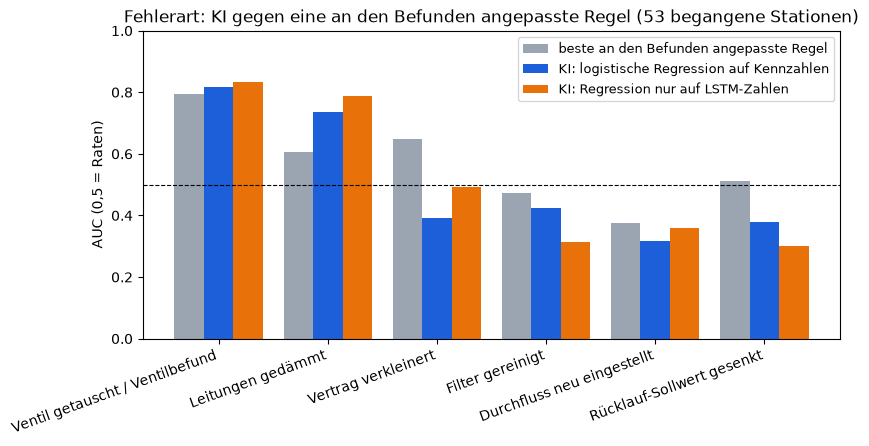

In [56]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg))
ax.bar(x - 0.27, kg["Regel angepasst"], 0.27, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x, kg["LR Kennzahlen"], 0.27, color="#1d5fd8", label="KI: logistische Regression auf Kennzahlen")
ax.bar(x + 0.27, kg["KI"], 0.27, color="#e8710a", label="KI: Regression nur auf LSTM-Zahlen")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI gegen eine an den Befunden angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "13_ki_gegen_regel")
plt.show()

**Ergebnis 1: KI gegen angepasste Regel**

- **Dämmung:** Keine einzelne Kennzahl trennt gut, die beste Regel kommt auf 0,61. Die Regression auf Kennzahlen erreicht
  0,73, die Regression nur auf den LSTM-Zahlen (Dashboard-Modell) 0,79. Die KI liegt um 0,18 vorn, in 96 % der Ziehungen.
  Das 95-%-Intervall reicht von −0,03 bis +0,39 und ist damit **knapp nicht gesichert**. Das Muster steckt in der
  **Kombination** mehrerer Größen (die Regel
  wählt je nach Fold Rücklauf, Spreizung nachts im Sommer oder Rücklauf bei 0 °C). Genau das kann eine einzelne Regel nicht.
- **Ventil:** Die angepasste Regel (Nachtdurchfluss im Sommer) kommt auf 0,79, die KI auf 0,83 (+0,04, in 65 % der
  Ziehungen vorn, nicht gesichert). Das Muster ist einfach, eine Regel sieht es auch. Die feste Sommernacht-Regel aus
  Test C (0,85) ist besser als die angepasste: Fachwissen schlägt hier das Anpassen an 11 Fälle.
- **Anschluss zu groß:** Die KI scheitert (0,49), weil ihr die Auslastung zum alten Vertrag fehlt. Die Regel mit dieser
  Kennzahl aus Test C (0,76) bleibt richtig.
- **Filter, Durchfluss, Temperatur:** Weder Regel noch KI kommen über 0,51. Dass die KI dort unter 0,5 liegt, heißt: Sie
  lernt Rauschen. Die Information steckt nicht in den Zählerwerten.

In [57]:
netz15 = fv.netzvergleich(e["serien"], e["termine"], e["anschluss"], e["bhkw"])
iv15 = fv.ivelina_kennzahlen(netz15, "23/24").add_prefix("iv_")
sommer15 = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "sommer_nacht_spreizung_k", "sommerlast_anteil"]
winter15 = [k for k in fv.KENNZAHLEN if k not in sommer15]
X15 = kz15[fv.KENNZAHLEN].join(iv15)
saetze15 = {"LR Ivelinas 5 Winterkennzahlen": list(iv15.columns),
            "LR 8 Winterkennzahlen (Modell-Strang)": winter15,
            "LR 4 Sommerkennzahlen (Modell-Strang)": sommer15,
            "LR alle 12 Kennzahlen (Modell-Strang)": list(fv.KENNZAHLEN),
            "LR 12 + Ivelinas 5": list(fv.KENNZAHLEN) + list(iv15.columns)}
ms = fv.merkmalssaetze_vergleich(X15, oof15, e["gruppen"], saetze15, ["ventil", "daemmung"])
ms[["Fehlerart", "Kennzahlen", "Anzahl", "AUC", "gefunden", "übersehen", "Fehlalarm"]].round(2)

,Fehlerart,Kennzahlen,Anzahl,AUC,gefunden,übersehen,Fehlalarm
0,ventil,LR Ivelinas 5 Winterkennzahlen,5,0.65,5,6,11
1,ventil,LR 8 Winterkennzahlen (Modell-Strang),8,0.74,6,5,10
2,ventil,LR 4 Sommerkennzahlen (Modell-Strang),4,0.92,8,3,3
3,ventil,LR alle 12 Kennzahlen (Modell-Strang),12,0.82,8,3,5
4,ventil,LR 12 + Ivelinas 5,17,0.82,9,2,6
5,daemmung,LR Ivelinas 5 Winterkennzahlen,5,0.60,12,10,12
6,daemmung,LR 8 Winterkennzahlen (Modell-Strang),8,0.73,13,9,10
7,daemmung,LR 4 Sommerkennzahlen (Modell-Strang),4,0.57,10,12,9
8,daemmung,LR alle 12 Kennzahlen (Modell-Strang),12,0.73,14,8,7
9,daemmung,LR 12 + Ivelinas 5,17,0.76,14,8,7


**Ergebnis 2: Gleiche Methode, andere Kennzahlen**

- Beim **Ventil** entscheiden die **Sommerkennzahlen**: mit Winterkennzahlen 0,65 (Ivelinas 5) bis 0,74 (8 des
  Modell-Strangs), mit den 4 Sommerkennzahlen 0,92. Auf Ivelinas eigenen Kennzahlen ist die gelernte Regression (0,65)
  nicht besser als ihre feste Regel (0,73, Test C). Der Vorsprung des Modell-Strangs kommt also daher, *was* gemessen wird,
  nicht vom Lernen.
- Bei der **Dämmung** tragen die Winterkennzahlen (0,73), der Sommer allein nicht (0,57). Hier hilft das Lernen auch auf
  Ivelinas Kennzahlen: 0,60 gegen 0,38 mit ihrer festen Regel.
- **Mehr Kennzahlen sind nicht automatisch besser:** Beim Ventil verwässern die Winterkennzahlen das Sommersignal
  (12 Kennzahlen 0,82 gegen 4 Sommerkennzahlen 0,92).
- **Vorsicht:** Diese fünf Sätze wurden nachträglich auf denselben 53 Stationen verglichen. Die 0,92 ist ein Hinweis, kein
  geprüfter Wert. Belastbar ist die Richtung, die auch die Vorarbeit (0,91), der Lernpfad (0,88) und die feste
  Sommernacht-Regel (0,85) zeigen.

In [58]:
faelle15 = pd.read_csv(fv.AUSGABE / "testB_faelle.csv")
wz = fv.waechter_zusammen(faelle15, "ivelina", "lstm_c", "Winter")
anzeige = wz.rename(columns={"ivelina": "Ivelina %", "lstm_c": "Prognose-LSTM %", "zusammen": "zusammen %"})
anzeige[["Ivelina %", "Prognose-LSTM %", "zusammen %"]] *= 100
anzeige.round(0)

key,Ivelina %,Prognose-LSTM %,zusammen %,Fälle
art,,,,
Dauerdurchfluss 150 l/h,78.0,69.0,87.0,77
Dauerdurchfluss 50 l/h,57.0,45.0,70.0,77
Fühler hängt,48.0,27.0,61.0,77
Regelhysterese 6 h,13.0,10.0,22.0,77
Rücklauf +5 K,56.0,25.0,65.0,77
ohne Fehler,12.0,3.0,12.0,77
schleichend +5 K in 30 Tagen,53.0,18.0,56.0,78


**Ergebnis 3: Wächter zusammen**

- Im Winter findet das Prognose-LSTM Fehler, die Ivelinas Kennlinie übersieht, vor allem **plötzliche**: Dauerdurchfluss
  50 l/h 57 → 70 %, Fühler hängt 48 → 61 %, Rücklauf +5 K 56 → 65 %. Bei langsamen Fehlern bringt es kaum etwas
  (53 → 56 %). Über alle eingebauten Fehler steigt die Trefferquote von 51 auf 60 %.
- **Die Fehlalarme bleiben gleich (12 %):** Die wenigen Fehlalarme des LSTM fallen in dieselben Fenster wie Ivelinas.
- Gemessen ist das nur an eingebauten Fehlern. An echten Begehungen (Test A) meldet das LSTM nicht öfter als an
  Vergleichsstationen.

In [59]:
kg.to_csv(fv.AUSGABE / "ki_gegen_regel.csv", index=False)
regel15.to_csv(fv.AUSGABE / "ki_gegen_regel_vorhersagen.csv", index=False)
ms.to_csv(fv.AUSGABE / "kennzahlen_saetze.csv", index=False)
wz.to_csv(fv.AUSGABE / "waechter_zusammen.csv")
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/projektseminar_neu/outputs/finalvergleich


### Was Abschnitt 15 heißt

- **Die KI hat einen Mehrwert, wo eine Regel nicht reicht:** bei der Dämmung, weil das Muster aus mehreren Kennzahlen
  besteht (knapp nicht gesichert), und als Wächter für plötzliche Sprünge (an eingebauten Fehlern, ohne zusätzliche
  Fehlalarme). Beim Ventil ist das Muster so einfach, dass eine Regel genauso gut ist.
- **Das LSTM trägt dazu bei:** Die Regression auf dem LSTM-Fingerabdruck kommt bei der Dämmung auf 0,79, die auf
  Kennzahlen auf 0,73 (nicht gesichert). Als Wächter merkt das LSTM plötzliche Sprünge.
- **An der Logik des Dashboards ändert sich nichts:** Die Dämmung bleibt ein Hinweis mit niedriger Dringlichkeit, weil das
  Muster physikalisch noch ungeklärt ist (gedämmt wurde eher an Stationen, die im Winter gut laufen). Die Meldungen des LSTM
  an Heiztagen bleiben als Hinweis im Hausfenster, weil ihr Nutzen nur an eingebauten Fehlern gemessen ist. Der Reiter
  „So funktioniert's“ nennt jetzt beides.
- **Viele Gegenproben:** Abschnitt 15 prüft sechs Fehlerarten und fünf Kennzahlensätze. Einzelne knappe Ergebnisse können
  Zufall sein. Belastbar ist das Bild über alle Prüfungen.

## 16 · Modellwahl ohne Blick auf die Testdaten

**Frage:** In Test C wurde jeder Kandidat sauber außerhalb des Folds bewertet. Welcher Kandidat ins Dashboard kommt, haben
wir zuerst anhand genau dieser Testwerte entschieden: die Regression auf Kennzahlen und LSTM-Zahlen mit 0,88. Damit
steckt in der Wahl Wissen über die Teststationen, und die Zahl des Siegers ist zu optimistisch. Wie gut ist das ganze
Verfahren, wenn auch die Wahl nur auf den Lernstationen passiert?

**So prüfen wir:** gleiche Stationen, Folds und Startwerte wie Test C (`fv.modellwahl_verschachtelt`). In jedem Durchgang:

1. Der LSTM-Fingerabdruck wird ohne die Teststationen neu gelernt, wie in Test C.
2. Jeder der fünf Kandidaten wird nur auf den Lernstationen bewertet: innere Kreuzvalidierung mit 4 Teilen über
   Stationsgruppen. Die Bremse der Regression wird darin wieder nur im jeweiligen Lernteil gesucht.
3. Der Kandidat mit der höchsten AUC in dieser Validierung wird auf allen Lernstationen gelernt und einmal auf die
   Teststationen angewendet. Bei Gleichstand gewinnt der einfachere.

Gerechnet für Ventil und Dämmung, die beiden Modelle im Dashboard. Die Teststationen sehen damit weder die Gewichte noch die
Bremse noch die Wahl des Modells.

In [60]:
oof16 = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
mw = fv.modellwahl_verschachtelt(e, oof16, ["ventil", "daemmung"], log=print)
mw["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 7 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 7 s


...

LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 7 s


Durchgang 5 von 5 fertig


ziel,daemmung,ventil
fold,,
0,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM
1,LR nur LSTM-Embedding,LR Kennzahlen + LSTM
2,LR Kennzahlen + LSTM,LR nur LSTM-Embedding
3,LR nur LSTM-Embedding,LR nur LSTM-Embedding
4,LR nur LSTM-Embedding,XGBoost Kennzahlen + LSTM


In [61]:
innen16 = mw["wahl"].set_index(["ziel", "fold"]).drop(columns="gewaehlt")
innen16.columns = [c.replace("AUC im Lernteil: ", "") for c in innen16.columns]
innen16.round(2)

,,LR Kennzahlen,LR Kennzahlen + LSTM,LR nur LSTM-Embedding,XGBoost Kennzahlen,XGBoost Kennzahlen + LSTM
ziel,fold,,,,,
ventil,0,0.81,0.86,0.91,0.66,0.94
daemmung,0,0.75,0.81,0.79,0.70,0.87
ventil,1,0.85,0.87,0.82,0.83,0.81
daemmung,1,0.66,0.76,0.79,0.60,0.73
ventil,2,0.73,0.81,0.82,0.71,0.72
daemmung,2,0.68,0.81,0.77,0.68,0.75
ventil,3,0.76,0.82,0.84,0.66,0.68
daemmung,3,0.61,0.68,0.71,0.59,0.60
ventil,4,0.84,0.85,0.81,0.77,0.88


**Welcher Kandidat gewinnt in der Validierung?** Er wechselt von Durchgang zu Durchgang. Beim Ventil zweimal XGBoost mit
LSTM-Zahlen, zweimal die Regression nur auf LSTM-Zahlen, einmal die Regression auf Kennzahlen und LSTM-Zahlen. Bei der
Dämmung dreimal die Regression nur auf LSTM-Zahlen. Auffällig: In jedem Durchgang gewinnt ein Kandidat **mit** LSTM-Zahlen,
nie die Regression auf Kennzahlen allein. Die Abstände in der Validierung sind aber oft nur wenige Hundertstel.

In [62]:
vgl16 = mw["oof"].merge(oof16[oof16["kandidat"] == fv.ENDMODELL][["zaehler", "ziel", "p"]]
                        .rename(columns={"p": "p_test_c"}), on=["zaehler", "ziel"])
abw16 = (vgl16["p_fest_nachgerechnet"] - vgl16["p_test_c"]).abs()
print(f"Abgleich mit Test C (feste Wahl {fv.ENDMODELL}, gleiche Folds und Startwerte):",
      f"größte Abweichung {abw16.max():.4f}, mittlere {abw16.mean():.4f}")

Abgleich mit Test C (feste Wahl LR nur LSTM-Embedding, gleiche Folds und Startwerte): größte Abweichung 0.0000, mittlere 0.0000


Mit denselben Folds und Startwerten rechnet der Code die feste Wahl aus Test C genau nach (Abweichung 0). Unterschiede in
der Tabelle unten kommen also nur von der Modellwahl.

In [63]:
tab16 = fv.modellwahl_auswerten(mw, oof16, e["gruppen"])
tab16.round(2)

,Fehlerart,Verfahren,AUC,unten,oben,gefunden,übersehen,Fehlalarm,Befunde unter den ersten 10,gegen feste Wahl,Diff. unten,Diff. oben
0,ventil,Modellwahl im Lernteil (verschachtelt),0.84,0.68,0.97,8,3,5,8,0.00,-0.08,0.10
1,ventil,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.83,0.64,0.98,8,3,4,7,NaN,NaN,NaN
2,ventil,Regel Sommernacht-Anteil (ohne Lernen),0.85,0.68,0.98,9,2,5,7,NaN,NaN,NaN
3,daemmung,Modellwahl im Lernteil (verschachtelt),0.78,0.64,0.91,15,7,6,9,-0.01,-0.10,0.09
4,daemmung,"LR nur LSTM-Embedding, fest gewählt (Test C)",0.79,0.65,0.90,15,7,7,9,NaN,NaN,NaN


**Ergebnis**

- **Ventil:** Mit der Wahl im Lernteil 0,84 [0,68; 0,97], 8 von 11 gefunden bei 5 Fehlalarmen, unter den ersten 10
  sind 8. Das Dashboard-Modell allein (Regression nur auf LSTM-Zahlen) kommt auf 0,83, Unterschied +0,00 [−0,08; +0,10].
  Die zuerst nach den Testzahlen gewählte Fassung mit Kennzahlen hatte 0,88, das war um etwa 0,05 zu optimistisch.
  Alles ist so gut wie die einfache Sommernacht-Regel (0,85; Unterschied −0,01 [−0,14; +0,12]).
- **Dämmung:** 0,78 [0,64; 0,91], das Dashboard-Modell allein 0,79 (Unterschied −0,01 [−0,10; +0,09]). Gegen die beste an den Befunden angepasste Regel
  (0,61) bleibt ein Vorsprung von +0,17 [−0,04; +0,38], in 95 % der Ziehungen vorn, also weiter knapp nicht gesichert.

In [64]:
mw["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_vorhersagen.csv", index=False)
mw["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_wahl.csv", index=False)
tab16.to_csv(fv.AUSGABE / "modellwahl_verschachtelt.csv", index=False)
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/projektseminar_neu/outputs/finalvergleich


### Was Abschnitt 16 heißt

- **Die ehrlichen Zahlen** des ganzen Verfahrens, bei dem auch die Modellwahl die Teststationen nicht kennt: Ventil 0,84,
  Dämmung 0,78. Die 0,88 aus Test C galt für die Fassung mit Kennzahlen, die wir zuerst nachträglich ausgewählt hatten, und war
  deshalb zu hoch.
- **Beim Ventil ist die KI damit gleichauf mit der einfachen Regel.** Bei der Dämmung findet nur die KI ein Muster
  (0,78 gegen 0,61), knapp nicht gesichert.
- **Fürs Dashboard:** In der Validierung gewinnt in jedem Durchgang ein Kandidat mit LSTM-Zahlen, welcher genau, hängt an
  wenigen Hundertstel. Das Dashboard nimmt die einfachste dieser Fassungen, die Regression nur auf den LSTM-Zahlen
  (Abschnitt 16c). Die Begründung im Hausfenster bleibt die Sommernacht-Regel.
- **Für Aussagen gelten ab jetzt diese Zahlen:** Ventil 0,84, Dämmung 0,78.

### 16b · Alle fünf Fehlerarten gegen die Regeln

Damit das Bild „KI gegen Regel“ aus Abschnitt 15 auf denselben sauberen Zahlen steht, rechnen wir die Modellwahl im
Lernteil auch für Filter, Durchfluss und Sollwert. Danach treten alle fünf Fehlerarten gegen die angepasste Regel aus
Abschnitt 15 an, gleiche Stationen, Folds und Ziehungen. Beim Ventil zusätzlich gegen die feste Sommernacht-Regel aus
Fachwissen, weil sie dort die stärkere Regel ist.

In [65]:
mw3 = fv.modellwahl_verschachtelt(e, oof16, ["filter", "durchfluss", "temperatur"], log=print)
mw3["wahl"].pivot(index="fold", columns="ziel", values="gewaehlt")

LSTM-Encoder: 88 Runden, bester Validierungsfehler 0.1708, 7 s


Durchgang 1 von 5 fertig


LSTM-Encoder: 85 Runden, bester Validierungsfehler 0.1617, 7 s


Durchgang 2 von 5 fertig


LSTM-Encoder: 87 Runden, bester Validierungsfehler 0.1935, 7 s


...

LSTM-Encoder: 73 Runden, bester Validierungsfehler 0.1845, 6 s


Durchgang 4 von 5 fertig


LSTM-Encoder: 84 Runden, bester Validierungsfehler 0.1374, 7 s


Durchgang 5 von 5 fertig


ziel,durchfluss,filter,temperatur
fold,,,
0,XGBoost Kennzahlen + LSTM,LR Kennzahlen,LR Kennzahlen
1,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen,LR Kennzahlen
2,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen + LSTM,LR nur LSTM-Embedding
3,XGBoost Kennzahlen,LR nur LSTM-Embedding,XGBoost Kennzahlen
4,LR Kennzahlen,XGBoost Kennzahlen + LSTM,XGBoost Kennzahlen


Bei Filter, Durchfluss und Sollwert wechselt der Sieger noch stärker, und hier gewinnen auch Kandidaten ohne LSTM-Zahlen.
Das passt dazu, dass es dort kein Muster gibt, das ein Kandidat zuverlässig trifft.

In [66]:
ziele16 = ["ventil", "daemmung", "filter", "durchfluss", "temperatur"]
kz16 = fv.kennzahlen_vor_begehung(e["stunden"], e["labels"])
regel16 = fv.regel_angepasst(kz16, oof16, ziele16)
verschachtelt = pd.concat([mw["oof"], mw3["oof"]])
ki16 = verschachtelt[["zaehler", "fold", "ziel", "p", "y"]].assign(kandidat="KI mit Modellwahl im Lernteil")
kg16 = fv.ki_gegen_regel(pd.concat([oof16, ki16]), regel16, e["gruppen"], ziele16, ki="KI mit Modellwahl im Lernteil")
kg16 = kg16.rename(columns={"KI": "KI mit Modellwahl im Lernteil"})
kg16[["Fehlerart", "Befunde", "Regel angepasst", "LR Kennzahlen", "KI mit Modellwahl im Lernteil",
      "KI − Regel", "unten", "oben", "KI vorn in", "gesichert"]].round(2)

,Fehlerart,Befunde,Regel angepasst,LR Kennzahlen,KI mit Modellwahl im Lernteil,KI − Regel,unten,oben,KI vorn in,gesichert
0,ventil,11,0.79,0.82,0.84,0.04,-0.11,0.22,0.69,False
1,daemmung,22,0.61,0.73,0.78,0.17,-0.04,0.38,0.95,False
2,filter,25,0.47,0.43,0.39,-0.08,-0.25,0.09,0.18,False
3,durchfluss,18,0.38,0.32,0.37,-0.01,-0.22,0.19,0.45,False
4,temperatur,33,0.51,0.38,0.37,-0.15,-0.36,0.07,0.08,False


In [67]:
v = verschachtelt[verschachtelt["ziel"] == "ventil"].set_index("zaehler")
regel_fest = oof16[(oof16["ziel"] == "ventil") & (oof16["kandidat"] == "Regel Sommernacht-Anteil")].set_index("zaehler")["p"]
d, lo, hi = fv.bootstrap_auc_differenz(v["y"].to_numpy(), v["p"].to_numpy(), regel_fest.reindex(v.index).to_numpy(),
                                       e["gruppen"].reindex(v.index).to_numpy())
print(f"Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: {d:+.2f} [{lo:+.2f}; {hi:+.2f}]")

Ventil, KI mit Modellwahl im Lernteil gegen die feste Sommernacht-Regel: -0.01 [-0.14; +0.12]


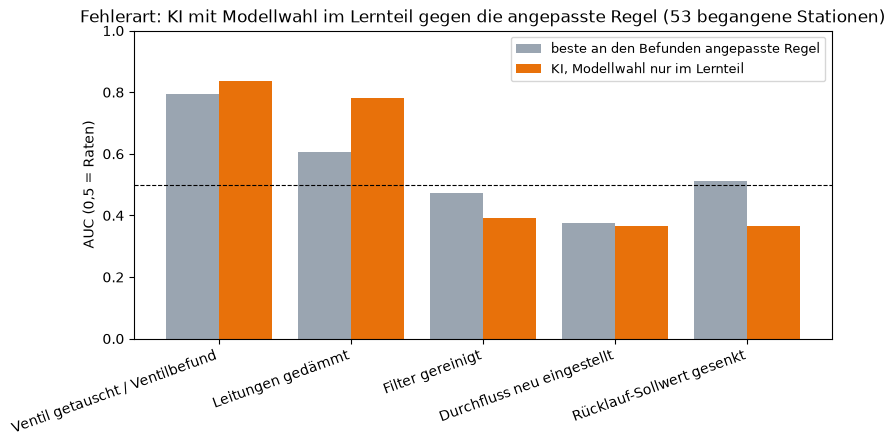

In [68]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(kg16))
ax.bar(x - 0.2, kg16["Regel angepasst"], 0.4, color="#9aa5b1", label="beste an den Befunden angepasste Regel")
ax.bar(x + 0.2, kg16["KI mit Modellwahl im Lernteil"], 0.4, color="#e8710a", label="KI, Modellwahl nur im Lernteil")
ax.axhline(0.5, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [fv.ZIEL_TEXT.get(z, z) for z in kg16["Fehlerart"]], rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("AUC (0,5 = Raten)")
ax.set_title("Fehlerart: KI mit Modellwahl im Lernteil gegen die angepasste Regel (53 begangene Stationen)")
ax.legend(loc="upper right", fontsize=9)
fv.speichere(fig, "14_ki_gegen_regel_modellwahl")
plt.show()

**Ergebnis**

- **Ventil:** KI 0,84 gegen die angepasste Regel 0,79 (+0,04 [−0,11; +0,22], in 69 % der Ziehungen vorn). Gegen die
  feste Sommernacht-Regel (0,85) gleichauf: −0,01 [−0,14; +0,12].
- **Dämmung:** KI 0,78 gegen 0,61: +0,17 [−0,04; +0,38], in 95 % der Ziehungen vorn, knapp nicht gesichert.
- **Filter, Durchfluss, Sollwert:** KI 0,39 / 0,37 / 0,37, Regel 0,47 / 0,38 / 0,51. Keiner ist besser als Raten. Unter 0,5
  heißt hier nicht „umgekehrt richtig“, sondern: nichts gefunden.
- **Die Aussage aus Abschnitt 15 bleibt:** Beim Ventil reicht eine Regel, bei der Dämmung findet nur die KI ein Muster, die
  übrigen Maßnahmen findet niemand. Nur die Zahlen sind jetzt etwas kleiner und dafür sauber.

In [69]:
mw3["oof"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_vorhersagen.csv", index=False)
mw3["wahl"].to_csv(fv.AUSGABE / "modellwahl_verschachtelt_weitere_wahl.csv", index=False)
kg16.to_csv(fv.AUSGABE / "ki_gegen_regel_modellwahl.csv", index=False)
print("gespeichert in", fv.AUSGABE)

gespeichert in /home/dom/Code/Github Projekt/projektseminar_neu/outputs/finalvergleich


**Welches Modell kommt ins Dashboard?** Auch diese Wahl darf nicht auf die Testzahlen schauen. Deshalb hier nur die
Validierung: die AUC jedes Kandidaten in den inneren Teilen, gemittelt über die fünf Durchgänge.

In [70]:
wahl16 = pd.concat([mw["wahl"], mw3["wahl"]])
spalten = [c for c in wahl16.columns if c.startswith("AUC im Lernteil")]
innen_mittel = wahl16.groupby("ziel")[spalten].mean().T
innen_mittel.index = [i.replace("AUC im Lernteil: ", "") for i in innen_mittel.index]
innen_mittel[["ventil", "daemmung"]].round(2)

ziel,ventil,daemmung
LR Kennzahlen,0.80,0.67
LR Kennzahlen + LSTM,0.84,0.76
LR nur LSTM-Embedding,0.84,0.77
XGBoost Kennzahlen,0.73,0.63
XGBoost Kennzahlen + LSTM,0.81,0.73


- **Ventil:** Die Regression nur auf LSTM-Zahlen und die auf Kennzahlen + LSTM-Zahlen sind gleichauf (beide 0,84).
  **Dämmung:** ebenfalls gleichauf (0,77 und 0,76). XGBoost liegt dahinter und schwankt je nach Startwert.
- **Das Dashboard nimmt bei Gleichstand das einfachere Modell: die Regression nur auf den 16 LSTM-Zahlen**
  (`fv.ENDMODELL`). Auch diese Wahl schaut nicht auf die Testzahlen. Die Kennzahlen bleiben als Begründung im
  Hausfenster (Sommernacht) und als Messlatte.
- **Seine eigene Testzahl** (Test C): Ventil 0,83, 8 von 11 bei 4 Fehlalarmen; Dämmung 0,79, 15 von 22 bei 7
  Fehlalarmen. Das liegt nah am sauberen Verfahren aus Abschnitt 16 (0,84 und 0,78), das für Aussagen gilt.
- **Was es kostet:** Mit anderen Startwerten schwankt es beim Ventil stärker (0,83 bis 0,90 gegen 0,88 bis 0,89), und
  nach einer Begehung sinkt sein Score auch ohne Ventiltausch (Gegenprobe, Test C). Die Fassung mit Kennzahlen war in beidem
  ruhiger.